# Glacial Lake Segmentation — ResNet34-FCN Baseline (Google Colab Training)

[![Python 3.9+](https://img.shields.io/badge/Python-3.9%2B-blue.svg)](https://www.python.org/)
[![PyTorch 2.0+](https://img.shields.io/badge/PyTorch-2.0%2B-ee4c2c.svg)](https://pytorch.org/)
[![Dataset: GLID](https://img.shields.io/badge/Dataset-GLID-green.svg)](https://doi.org/10.5281/zenodo.14838695)

This notebook is the **dedicated, reproducible Google Colab training, checkpointing, and evaluation environment** for the **ResNet-34 Fully Convolutional Network (FCN)** baseline model.

---

### Architectural Specifications
* **Encoder**: ResNet-34 convolutional backbone initialized with ImageNet pretrained weights (`ResNet34_Weights.DEFAULT`).
* **Decoder**: 5-stage progressive transposed-convolution upsampling head ($512 \to 256 \to 128 \to 64 \to 32 \to 16 \to 1$) with Batch Normalization and ReLU activations.
* **Exact Parameters**: **24,079,153 total parameters** (21,284,672 encoder + 2,794,481 decoder; 100% trainable, 0 non-trainable).
* **Comparison Model**: DeepLabV3+ with ResNet-50 + ASPP (**40,347,041 total parameters**).

---

### Key Operational Safeguards
1. **Isolated Google Drive Experiment Folder**: Checkpoints, logs, training curves, evaluation metrics, and comparison summaries are saved in:
   `Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/` (completely isolated from DeepLabV3+ files).
2. **Explicit Multi-Candidate Dataset Selection**: Scans Google Drive, displays all candidate paths and sample counts, avoids auto-selecting `test` folders as validation, and requires an explicit unambiguous match.
3. **Reusable Archive Transfer, Local SSD Extraction & Integrity Checks**: Confirms matching image-label filenames, validates readability on sample pairs, and creates a reusable Drive archive once, extracts to local SSD with progress, and verifies cache metadata; source data is never deleted.
4. **Zero Weight-Mutation Speed Benchmark**: Benchmarks GPU throughput on an isolated temporary model instance, programmatically asserting that training model weights remain 100% untouched.
5. **Atomic Checkpointing & CSV-History Sync**: Checkpoint payload and CSV history are strictly synchronized upon resume, preventing duplicate or skipped epoch records after Colab disconnections.
6. **Optional Smoke Test Mode**: An isolated 1-epoch mini smoke-test verifies forward pass, loss computation, atomic checkpoint saving, checkpoint reload, and evaluation without modifying primary weights.

> **Hardware Requirement**: Ensure GPU acceleration is enabled via **Runtime → Change runtime type → T4 GPU** (or A100/V100).


## 1. Hardware & Environment Verification
Verify CUDA availability, GPU device specifications, and runtime memory.


In [1]:
# 1.1 GPU and CUDA Verification
import sys
import torch

print("=" * 65)
print("  Environment & Hardware Verification")
print("=" * 65)
print(f"Python Version    : {sys.version.split()[0]}")
print(f"PyTorch Version   : {torch.__version__}")
print(f"CUDA Available    : {torch.cuda.is_available()}")

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU is not detected!\n"
        "Please navigate to: Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU"
    )

gpu_name = torch.cuda.get_device_name(0)
gpu_mem_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
print(f"GPU Model         : {gpu_name}")
print(f"GPU VRAM          : {gpu_mem_gb:.2f} GB")
print(f"CUDA Device Count : {torch.cuda.device_count()}")
print("=" * 65)

# Enable cuDNN benchmark for optimized conv kernels with fixed 512x512 inputs
torch.backends.cudnn.benchmark = True


  Environment & Hardware Verification
Python Version    : 3.13.16
PyTorch Version   : 2.11.0+cu130
CUDA Available    : True
GPU Model         : Tesla T4
GPU VRAM          : 14.56 GB
CUDA Device Count : 1


## 2. Google Drive Mounting & Repository Setup
Mount Google Drive and clone or pull the latest project source code.


In [2]:
# 2.1 Mount Google Drive
from google.colab import drive
import os

drive.mount('/content/drive')
print("✓ Google Drive mounted successfully.")


Mounted at /content/drive
✓ Google Drive mounted successfully.


In [3]:
# 2.2 Clone or update project repository
from pathlib import Path

%cd /content
REPO_DIR = Path("/content/glacial-lake-segmentation")
REPO_URL = "https://github.com/ShubhamSnSharma/glacial-lake-segmentation.git"

if not REPO_DIR.exists():
    print(f"Cloning repository from {REPO_URL}...")
    !git clone -q {REPO_URL}
else:
    print("Repository exists locally. Pulling latest commits from main...")
    %cd {REPO_DIR}
    !git pull -q

%cd {REPO_DIR}
!git log -1 --oneline
print("✓ Working directory set to:", os.getcwd())


/content
Cloning repository from https://github.com/ShubhamSnSharma/glacial-lake-segmentation.git...
/content/glacial-lake-segmentation
bccccf7 (HEAD -> main, origin/main, origin/HEAD) Add Streamlit segmentation MVP
✓ Working directory set to: /content/glacial-lake-segmentation


In [4]:
# 2.3 Install project dependencies and restore repository imports

import sys
import subprocess
from pathlib import Path

REPO_DIR = Path("/content/glacial-lake-segmentation")

if not REPO_DIR.exists():
    raise FileNotFoundError(
        f"Repository not found: {REPO_DIR}. "
        "Run cell 2.2 first."
    )

# Set repository root as the working directory
%cd /content/glacial-lake-segmentation

# Register repository root for imports such as `from src.dataset import GLIDDataset`
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

# Install only the supporting packages.
# Do not reinstall or replace Colab's PyTorch/CUDA build.
packages = [
    "pillow",
    "pyyaml",
    "matplotlib",
    "tqdm",
    "scikit-learn",
    "pandas"
]

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", *packages
])

# Verify that the repository imports work
from src.dataset import GLIDDataset

print("✓ Repository path restored.")
print("✓ GLIDDataset imported successfully.")
print("✓ Supporting dependencies installed.")
print("Repository:", REPO_DIR)

/content/glacial-lake-segmentation
✓ Repository path restored.
✓ GLIDDataset imported successfully.
✓ Supporting dependencies installed.
Repository: /content/glacial-lake-segmentation


## 3. Directory Configuration & Dataset Restore
Configure the existing experiment directories and restore the verified staged GLID archive directly, without rebuilding the failed chunk archive.

In [5]:
# 3.1 Path Configuration & Isolated Output Directories
from pathlib import Path

# Base Google Drive root for the project
DRIVE_PROJECT_ROOT = Path("/content/drive/MyDrive/Glacial_Lake_Segmentation")

# Dedicated experiment folder for ResNet34-FCN
EXP_DIR = DRIVE_PROJECT_ROOT / "experiments" / "resnet34_fcn_colab"
EXP_CHECKPOINTS = EXP_DIR / "checkpoints"
EXP_RESULTS = EXP_DIR / "results"
EXP_LOGS = EXP_RESULTS / "logs"
EXP_PLOTS = EXP_RESULTS / "plots"
EXP_PREDICTIONS = EXP_RESULTS / "predictions"
EXP_EVALUATION = EXP_RESULTS / "evaluation"
EXP_COMPARISON = EXP_DIR / "comparison"
EXP_SMOKE_TEST = EXP_DIR / "smoke_test"

# Create all persistent experiment directories in Drive
for folder in [EXP_CHECKPOINTS, EXP_LOGS, EXP_PLOTS, EXP_PREDICTIONS, EXP_EVALUATION, EXP_COMPARISON, EXP_SMOKE_TEST]:
    folder.mkdir(parents=True, exist_ok=True)

# Local fast NVMe SSD storage path
LOCAL_DATA_ROOT = Path("/content/dataset")
LOCAL_TRAIN_DIR = LOCAL_DATA_ROOT / "GLID"
LOCAL_VAL_DIR = LOCAL_DATA_ROOT / "val"

print("✓ Experiment output paths initialized:")
print(f"  Checkpoints : {EXP_CHECKPOINTS}")
print(f"  Logs        : {EXP_LOGS}")
print(f"  Evaluation  : {EXP_EVALUATION}")


✓ Experiment output paths initialized:
  Checkpoints : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/checkpoints
  Logs        : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/results/logs
  Evaluation  : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/results/evaluation


In [6]:
# 3.2–3.4 Reliable dataset restore from the verified staged ZIP
# This replaces the fragile chunk-generation workflow. It does NOT create chunks
# and does not modify/delete any Google Drive dataset or archive.
import json
import shutil
import time
import zipfile
from pathlib import Path
import numpy as np
from PIL import Image

EXPECTED_TRAIN_PAIRS = 16_000
EXPECTED_VAL_PAIRS = 2_367
DRIVE_ARCHIVE = Path("/content/drive/MyDrive/persistent_dataset/glid_staged_dataset.zip")
DRIVE_ARCHIVE_MARKER = Path("/content/drive/MyDrive/persistent_dataset/archive_complete.json")

LOCAL_DATA_ROOT = Path("/content/dataset")
LOCAL_TRAIN_DIR = LOCAL_DATA_ROOT / "GLID"
LOCAL_VAL_DIR = LOCAL_DATA_ROOT / "val"
CLEAN_ROOT = Path("/content/glid_clean")
CLEAN_TRAIN = CLEAN_ROOT / "GLID"
CLEAN_VAL = CLEAN_ROOT / "val"

def _matched_names(split_dir):
    image_dir, mask_dir = split_dir / "images", split_dir / "labels"
    if not image_dir.is_dir() or not mask_dir.is_dir():
        raise FileNotFoundError(
            f"Expected {image_dir} and {mask_dir}. "
            "The staged ZIP must contain GLID/images, GLID/labels, val/images, and val/labels."
        )
    image_names = {p.name for p in image_dir.glob("*.png") if not p.name.startswith(".")}
    mask_names = {p.name for p in mask_dir.glob("*.png") if not p.name.startswith(".")}
    return sorted(image_names & mask_names), sorted(image_names - mask_names), sorted(mask_names - image_names)

def _split_is_complete(split_dir, expected_count):
    try:
        matched, _, _ = _matched_names(split_dir)
        return len(matched) == expected_count
    except (FileNotFoundError, OSError):
        return False

def _validate_archive_paths(zf):
    # Reject absolute paths and parent traversal before extracting.
    allowed_roots = {"GLID", "val"}
    for member in zf.namelist():
        p = Path(member)
        if p.is_absolute() or ".." in p.parts or not p.parts or p.parts[0] not in allowed_roots:
            raise RuntimeError(f"Unexpected path in staged dataset ZIP: {member}")

def _copy_archive_to_local(src, dst, attempts=3):
    if not src.is_file():
        raise FileNotFoundError(f"Verified staged dataset ZIP not found: {src}")
    dst.parent.mkdir(parents=True, exist_ok=True)
    last_error = None
    for attempt in range(1, attempts + 1):
        tmp = dst.with_suffix(dst.suffix + ".partial")
        try:
            expected_size = src.stat().st_size
            copied = 0
            print(f"Copying staged ZIP from Drive to Colab local storage, attempt {attempt}/{attempts}...")
            with src.open("rb") as fin, tmp.open("wb") as fout:
                while True:
                    block = fin.read(16 * 1024 * 1024)
                    if not block:
                        break
                    fout.write(block)
                    copied += len(block)
            if copied != expected_size or tmp.stat().st_size != expected_size:
                raise IOError(f"Archive copy size mismatch: {copied} / {expected_size} bytes")
            tmp.replace(dst)
            return
        except Exception as exc:
            last_error = exc
            tmp.unlink(missing_ok=True)
            print(f"Copy attempt failed: {type(exc).__name__}: {exc}")
            if attempt < attempts:
                time.sleep(3)
    raise RuntimeError("Could not copy the staged ZIP to local storage.") from last_error

def _create_clean_split(source_split, clean_split, split_name, expected_count):
    matched, orphan_images, orphan_masks = _matched_names(source_split)
    print(f"{split_name}: {len(matched):,} matched pairs, "
          f"{len(orphan_images):,} orphan images, {len(orphan_masks):,} orphan masks")
    if len(matched) != expected_count:
        raise RuntimeError(
            f"{split_name} matched-pair count mismatch: expected {expected_count:,}, got {len(matched):,}. "
            "No training should be started until the correct archive/split is restored."
        )
    # Rebuild only this disposable local symlink view, never the source data.
    if clean_split.exists():
        shutil.rmtree(clean_split)
    (clean_split / "images").mkdir(parents=True, exist_ok=True)
    (clean_split / "labels").mkdir(parents=True, exist_ok=True)
    for name in matched:
        (clean_split / "images" / name).symlink_to((source_split / "images" / name).resolve())
        (clean_split / "labels" / name).symlink_to((source_split / "labels" / name).resolve())
    return matched

t0 = time.time()
LOCAL_DATA_ROOT.mkdir(parents=True, exist_ok=True)
local_archive = Path("/content/glid_staged_dataset.zip")

if _split_is_complete(LOCAL_TRAIN_DIR, EXPECTED_TRAIN_PAIRS) and _split_is_complete(LOCAL_VAL_DIR, EXPECTED_VAL_PAIRS):
    print("Local dataset already contains the expected matched-pair counts. Skipping ZIP copy/extraction.")
else:
    if not DRIVE_ARCHIVE.is_file():
        raise FileNotFoundError(f"Staged dataset ZIP not found: {DRIVE_ARCHIVE}")
    if DRIVE_ARCHIVE_MARKER.is_file():
        marker = json.loads(DRIVE_ARCHIVE_MARKER.read_text(encoding="utf-8"))
        expected_marker = (EXPECTED_TRAIN_PAIRS, EXPECTED_TRAIN_PAIRS, EXPECTED_VAL_PAIRS, EXPECTED_VAL_PAIRS)
        actual_marker = (
            marker.get("train_images"), marker.get("train_masks"),
            marker.get("val_images"), marker.get("val_masks")
        )
        if actual_marker != expected_marker:
            raise RuntimeError(f"Archive metadata count mismatch: expected {expected_marker}, got {actual_marker}")
        print("Archive metadata counts verified.")
    else:
        print(f"Warning: metadata file not found at {DRIVE_ARCHIVE_MARKER}; validating actual ZIP contents instead.")

    _copy_archive_to_local(DRIVE_ARCHIVE, local_archive)
    print("Checking staged ZIP integrity. This can take a few minutes...")
    with zipfile.ZipFile(local_archive, "r") as zf:
        bad_member = zf.testzip()
        if bad_member is not None:
            raise IOError(f"ZIP integrity check failed at member: {bad_member}")
        _validate_archive_paths(zf)
        names = zf.namelist()
        print(f"ZIP integrity: PASS | entries: {len(names):,}")
        print("Extracting to local Colab storage, not Google Drive...")
        # Remove only the disposable local extraction, never the Drive source/archive.
        for split in ("GLID", "val"):
            target = LOCAL_DATA_ROOT / split
            if target.exists():
                shutil.rmtree(target)
        zf.extractall(LOCAL_DATA_ROOT)

    if not (_split_is_complete(LOCAL_TRAIN_DIR, EXPECTED_TRAIN_PAIRS) and
            _split_is_complete(LOCAL_VAL_DIR, EXPECTED_VAL_PAIRS)):
        raise RuntimeError(
            "Extraction completed, but expected matched pairs were not found under /content/dataset/GLID and /content/dataset/val. "
            "Inspect ZIP paths before proceeding; the loader will not silently substitute another split."
        )

train_names = _create_clean_split(LOCAL_TRAIN_DIR, CLEAN_TRAIN, "Training", EXPECTED_TRAIN_PAIRS)
val_names = _create_clean_split(LOCAL_VAL_DIR, CLEAN_VAL, "Validation", EXPECTED_VAL_PAIRS)

# Verify a sample of actual image/mask files, dimensions, readability, and mask conversion contract.
for split_name, split_dir, names in [
    ("train", CLEAN_TRAIN, train_names),
    ("validation", CLEAN_VAL, val_names),
]:
    for name in names[:min(12, len(names))]:
        with Image.open(split_dir / "images" / name) as im:
            im.verify()
        with Image.open(split_dir / "images" / name) as im:
            if im.size != (512, 512) or im.mode not in ("RGB", "RGBA"):
                raise ValueError(f"Unexpected {split_name} image format: {name}, size={im.size}, mode={im.mode}")
        with Image.open(split_dir / "labels" / name) as mask:
            mask.verify()
        with Image.open(split_dir / "labels" / name) as mask:
            if mask.size != (512, 512):
                raise ValueError(f"Unexpected {split_name} mask size: {name}, {mask.size}")
            values = set(np.unique(np.asarray(mask)).tolist())
            if not values.issubset({0, 1, 255}):
                raise ValueError(f"Unexpected mask values in {name}: {values}")

print("=" * 72)
print(f"Dataset restored and audited in {time.time() - t0:.1f}s")
print(f"Clean training pairs   : {len(train_names):,}")
print(f"Clean validation pairs : {len(val_names):,}")
print(f"Training source        : {CLEAN_TRAIN}")
print(f"Validation source      : {CLEAN_VAL}")
print("Mask contract retained: existing GLIDDataset conversion treats values > 0 as foreground.")


Archive metadata counts verified.
Copying staged ZIP from Drive to Colab local storage, attempt 1/3...
Checking staged ZIP integrity. This can take a few minutes...
ZIP integrity: PASS | entries: 36,734
Extracting to local Colab storage, not Google Drive...
Training: 16,000 matched pairs, 0 orphan images, 0 orphan masks
Validation: 2,367 matched pairs, 0 orphan images, 0 orphan masks
Dataset restored and audited in 237.3s
Clean training pairs   : 16,000
Clean validation pairs : 2,367
Training source        : /content/glid_clean/GLID
Validation source      : /content/glid_clean/val
Mask contract retained: existing GLIDDataset conversion treats values > 0 as foreground.


### Dataset archive workflow (superseded by the reliable restore cell above)

This legacy cell is intentionally disabled in this revised notebook. The replacement cell restores the verified staged ZIP directly and builds a local matched-pair symlink view. It does not generate chunks or change the source archive.

### Archive diagnostics (superseded by the reliable restore cell above)

This legacy cell is intentionally disabled in this revised notebook. The replacement cell restores the verified staged ZIP directly and builds a local matched-pair symlink view. It does not generate chunks or change the source archive.

### Raw split diagnostics (superseded by the reliable restore cell above)

This legacy cell is intentionally disabled in this revised notebook. The replacement cell restores the verified staged ZIP directly and builds a local matched-pair symlink view. It does not generate chunks or change the source archive.

### Clean matched-pair view (superseded by the reliable restore cell above)

This legacy cell is intentionally disabled in this revised notebook. The replacement cell restores the verified staged ZIP directly and builds a local matched-pair symlink view. It does not generate chunks or change the source archive.

In [7]:
# ==============================================================================
# Cell 3.4 — GLID Dataset Validation
# CPU ONLY — NO GPU REQUIRED
# ==============================================================================

from src.dataset import GLIDDataset

# Use the CLEAN matched-pair dataset
LOCAL_TRAIN_DIR = CLEAN_TRAIN
LOCAL_VAL_DIR   = CLEAN_VAL

# ---------------------------------------------------------------------------
# Create dataset objects
# ---------------------------------------------------------------------------

train_ds = GLIDDataset(
    str(LOCAL_TRAIN_DIR),
    is_train=True,
    split="train"
)

val_ds = GLIDDataset(
    str(LOCAL_VAL_DIR),
    is_train=False,
    split="val"
)

n_train = len(train_ds)
n_val = len(val_ds)

print("\n" + "=" * 70)
print("GLID DATASET DISCOVERY VERIFICATION")
print("=" * 70)

print(f"Training samples   : {n_train:,}")
print(f"Validation samples : {n_val:,}")

print("=" * 70)

assert n_train == 16000, \
    f"Training count mismatch: expected 16,000, got {n_train}"

assert n_val == 2367, \
    f"Validation count mismatch: expected 2,367, got {n_val}"

print("✓ Training dataset : 16,000 valid image-mask pairs")
print("✓ Validation dataset: 2,367 valid image-mask pairs")
print("✓ No orphan files are visible to GLIDDataset")


GLID DATASET DISCOVERY VERIFICATION
Training samples   : 16,000
Validation samples : 2,367
✓ Training dataset : 16,000 valid image-mask pairs
✓ Validation dataset: 2,367 valid image-mask pairs
✓ No orphan files are visible to GLIDDataset


## 4. PyTorch DataLoaders & Architecture Initialization


In [8]:
# ==============================================================================
# 4.1 PyTorch DataLoaders
# CPU/GPU adaptive configuration
# ==============================================================================

import torch
from torch.utils.data import DataLoader

HAS_GPU = torch.cuda.is_available()

if HAS_GPU:
    BATCH_SIZE = 8
    NUM_WORKERS = 2
    PIN_MEMORY = True
else:
    # CPU verification mode only
    BATCH_SIZE = 2
    NUM_WORKERS = 0
    PIN_MEMORY = False

print("=" * 65)
print("DataLoader Configuration")
print("=" * 65)
print(f"GPU available : {HAS_GPU}")
print(f"Batch size    : {BATCH_SIZE}")
print(f"Workers       : {NUM_WORKERS}")
print(f"Pin memory    : {PIN_MEMORY}")
print("=" * 65)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    prefetch_factor=2 if NUM_WORKERS > 0 else None,
    drop_last=True,
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    prefetch_factor=2 if NUM_WORKERS > 0 else None,
    drop_last=False,
)

print("\n✓ DataLoaders created successfully.")
print(f"  Training batches   : {len(train_loader):,}")
print(f"  Validation batches : {len(val_loader):,}")

DataLoader Configuration
GPU available : True
Batch size    : 8
Workers       : 2
Pin memory    : True

✓ DataLoaders created successfully.
  Training batches   : 2,000
  Validation batches : 296


In [9]:
# 4.2 Verify tensor shape and contract on a real batch
sample_images, sample_masks = next(iter(train_loader))

print("Batch Tensor Check:")
print(f"  Images shape : {sample_images.shape} | dtype: {sample_images.dtype}")
print(f"  Masks shape  : {sample_masks.shape} | dtype: {sample_masks.dtype}")
print(f"  Mask values  : {torch.unique(sample_masks).tolist()}")

assert sample_images.shape == (BATCH_SIZE, 3, 512, 512), "Image shape mismatch!"
assert sample_masks.shape == (BATCH_SIZE, 1, 512, 512), "Mask shape mismatch!"
assert set(torch.unique(sample_masks).tolist()).issubset({0.0, 1.0}), "Masks must be binary {0.0, 1.0}!"
print("✓ Batch shape contract verified.")


Batch Tensor Check:
  Images shape : torch.Size([8, 3, 512, 512]) | dtype: torch.float32
  Masks shape  : torch.Size([8, 1, 512, 512]) | dtype: torch.float32
  Mask values  : [0.0, 1.0]
✓ Batch shape contract verified.


In [10]:
# ==============================================================================
# 4.3 ResNet34-FCN Model Initialization + Parameter Verification
# CPU/GPU adaptive
# ==============================================================================

import torch
from src.model import build_model

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("ResNet34-FCN Model Initialization")
print("=" * 65)
print(f"Device: {device}")

if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# ---------------------------------------------------------------------------
# Model configuration
# ---------------------------------------------------------------------------

fcn_cfg = {
    "model": {
        "name": "resnet34_fcn",
        "pretrained": True,
        "pretrained_source": "imagenet",
        "num_classes": 1,
        "freeze_encoder": False,
    }
}

# ---------------------------------------------------------------------------
# Build model
# ---------------------------------------------------------------------------

model = build_model(fcn_cfg).to(device)

# channels_last is useful for CUDA convolution performance
if device.type == "cuda":
    model = model.to(memory_format=torch.channels_last)

# ---------------------------------------------------------------------------
# Exact parameter counts
# ---------------------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

non_trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if not p.requires_grad
)

summary = model.get_parameter_summary()

encoder_params = summary["encoder_parameters"]
decoder_params = summary["decoder_parameters"]

print("\n" + "=" * 65)
print("ResNet34-FCN Parameter Verification")
print("=" * 65)

print(
    f"Total Parameters         : "
    f"{total_params:,}"
)

print(
    f"Trainable Parameters     : "
    f"{trainable_params:,}"
)

print(
    f"Non-Trainable Parameters : "
    f"{non_trainable_params:,}"
)

print(
    f"Encoder (ResNet-34)      : "
    f"{encoder_params:,}"
)

print(
    f"Decoder (5-Stage FCN)    : "
    f"{decoder_params:,}"
)

print("=" * 65)

# Exact expected value for this project implementation
assert total_params == 24_079_153, (
    f"Unexpected parameter count: {total_params:,}"
)

assert trainable_params == 24_079_153
assert non_trainable_params == 0

print("✓ Exact parameter count verified: 24,079,153")

# ---------------------------------------------------------------------------
# Forward pass
# ---------------------------------------------------------------------------

model.eval()

with torch.no_grad():

    x = sample_images.to(device)

    if device.type == "cuda":
        x = x.to(memory_format=torch.channels_last)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            out = model(x)

    else:
        # CPU: normal float32 inference
        out = model(x)

expected_shape = (
    BATCH_SIZE,
    1,
    512,
    512,
)

assert out.shape == expected_shape, (
    f"Unexpected output shape: {out.shape}; "
    f"expected {expected_shape}"
)

print(
    f"✓ Forward pass verified: "
    f"{tuple(out.shape)}"
)

print("=" * 65)
print("✓ MODEL INITIALIZATION COMPLETE")
print("=" * 65)

ResNet34-FCN Model Initialization
Device: cuda
GPU: Tesla T4
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 168MB/s]



ResNet34-FCN Parameter Verification
Total Parameters         : 24,079,153
Trainable Parameters     : 24,079,153
Non-Trainable Parameters : 0
Encoder (ResNet-34)      : 21,284,672
Decoder (5-Stage FCN)    : 2,794,481
✓ Exact parameter count verified: 24,079,153
✓ Forward pass verified: (8, 1, 512, 512)
✓ MODEL INITIALIZATION COMPLETE


## Implementation Note — Pretraining Difference from the Reference Paper

The reference study initializes its ResNet-34 encoder using **GID-pretrained weights** before fine-tuning on the GLID dataset.

In this implementation, **ImageNet-pretrained ResNet-34 weights** are used instead because the GID-pretrained weights used by the original study were not available for this implementation.

Therefore, this project follows the reference paper's overall glacial-lake segmentation approach and ResNet-34-based architecture, but it should **not be considered an exact reproduction** of the paper's ResNet34-FT model.

This distinction is explicitly reported to ensure a fair and transparent comparison of results.

## 5. GPU Speed Benchmark (Isolated — Zero Model Mutation)
Run a 2-batch benchmark using a **separate temporary model** to measure GPU throughput without altering the training model's weights.


In [11]:
# 5.1 Isolated Speed Benchmark (Guarantees Training Model Remains 100% Untouched)
import time
import copy
from src.losses import CombinedBCEDiceLoss

# Snapshot training model weights to assert zero mutation
initial_weights_snapshot = {k: v.clone().cpu() for k, v in model.state_dict().items()}

print("Running isolated speed benchmark on a temporary model...")

# 1. Create dedicated temporary model and optimizer for benchmark only
bench_model = build_model(fcn_cfg).to(device)
bench_model = bench_model.to(memory_format=torch.channels_last)
bench_model.train()

bench_loss = CombinedBCEDiceLoss()
bench_opt = torch.optim.AdamW(bench_model.parameters(), lr=1e-4)
bench_scaler = torch.amp.GradScaler("cuda")

times = []

for i, (imgs, msks) in enumerate(train_loader):
    if i >= 2:
        break
    t0 = time.time()

    imgs = imgs.to(device, non_blocking=True, memory_format=torch.channels_last)
    msks = msks.to(device, non_blocking=True)

    bench_opt.zero_grad(set_to_none=True)
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        preds = bench_model(imgs)
        loss = bench_loss(preds, msks)

    bench_scaler.scale(loss).backward()
    bench_scaler.unscale_(bench_opt)
    torch.nn.utils.clip_grad_norm_(bench_model.parameters(), max_norm=1.0)
    bench_scaler.step(bench_opt)
    bench_scaler.update()

    torch.cuda.synchronize()
    times.append(time.time() - t0)
    print(f"  Benchmark batch {i+1}/2 | Loss: {loss.item():.4f} | Batch Time: {times[-1]:.3f}s")

# Clean up benchmark artifacts and free GPU memory
del bench_model, bench_opt, bench_scaler
torch.cuda.empty_cache()

# 2. Programmatically verify that training model weights are 100% UNTOUCHED
for k, v in model.state_dict().items():
    if not torch.equal(v.cpu(), initial_weights_snapshot[k]):
        raise RuntimeError(f"FATAL: Benchmark mutated training model weights in layer {k}!")

del initial_weights_snapshot

avg_time = sum(times) / len(times)
est_epoch_min = (avg_time * len(train_loader)) / 60

print("\n" + "=" * 65)
print("  GPU Benchmark Results (Zero Model Mutation Verified)")
print("=" * 65)
print(f"Average Batch Time    : {avg_time:.3f} seconds")
print(f"Estimated Epoch Time  : {est_epoch_min:.1f} minutes (~{est_epoch_min * 30 / 60:.1f} hours for 30 epochs)")
print("✓ Verified: Training model weights are 100% intact and unmutated.")
print("=" * 65)


Running isolated speed benchmark on a temporary model...
  Benchmark batch 1/2 | Loss: 1.1288 | Batch Time: 1.647s
  Benchmark batch 2/2 | Loss: 1.0917 | Batch Time: 0.086s

  GPU Benchmark Results (Zero Model Mutation Verified)
Average Batch Time    : 0.867 seconds
Estimated Epoch Time  : 28.9 minutes (~14.4 hours for 30 epochs)
✓ Verified: Training model weights are 100% intact and unmutated.


## 6. Optional: 1-Epoch End-to-End Smoke Test
Run a 1-epoch test on a small 3-batch sample to verify the entire pipeline (forward, loss, backward, atomic checkpoint save, reload, and evaluation) without modifying the real training checkpoints.


In [12]:
# 6.1 Optional 1-Epoch Smoke Test (Isolated from Main Checkpoints)
RUN_SMOKE_TEST = True  # Set to False to skip smoke test and proceed directly to full training

if RUN_SMOKE_TEST:
    print("=" * 65)
    print("  Running 1-Epoch End-to-End Pipeline Smoke Test")
    print("=" * 65)

    # Create isolated smoke test model
    smoke_model = build_model(fcn_cfg).to(device)
    smoke_opt = torch.optim.AdamW(smoke_model.parameters(), lr=1e-4)
    smoke_crit = CombinedBCEDiceLoss().to(device)
    smoke_scaler = torch.amp.GradScaler("cuda")

    # 1. Train on 3 batches
    smoke_model.train()
    for batch_idx, (imgs, msks) in enumerate(train_loader):
        if batch_idx >= 3:
            break
        imgs = imgs.to(device, non_blocking=True)
        msks = msks.to(device, non_blocking=True)
        smoke_opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            l = smoke_crit(smoke_model(imgs), msks)
        smoke_scaler.scale(l).backward()
        smoke_scaler.step(smoke_opt)
        smoke_scaler.update()
        print(f"  [Smoke Train] Batch {batch_idx+1}/3 | Loss: {l.item():.4f}")

    # 2. Validation on 2 batches
    smoke_model.eval()
    val_losses = []
    with torch.no_grad():
        for batch_idx, (imgs, msks) in enumerate(val_loader):
            if batch_idx >= 2:
                break
            imgs = imgs.to(device, non_blocking=True)
            msks = msks.to(device, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                vl = smoke_crit(smoke_model(imgs), msks)
            val_losses.append(vl.item())
            print(f"  [Smoke Val]   Batch {batch_idx+1}/2 | Loss: {vl.item():.4f}")

    # 3. Save smoke test checkpoint atomically
    smoke_chk_path = EXP_SMOKE_TEST / "smoke_model.pth"
    smoke_tmp_path = EXP_SMOKE_TEST / "smoke_model.pth.tmp"
    torch.save({
        "epoch": 1,
        "model_state_dict": smoke_model.state_dict(),
        "optimizer_state_dict": smoke_opt.state_dict(),
        "smoke_val_loss": sum(val_losses)/len(val_losses)
    }, smoke_tmp_path)
    smoke_tmp_path.replace(smoke_chk_path)

    # 4. Reload smoke checkpoint and assert weights
    loaded_smoke = torch.load(smoke_chk_path, map_location=device, weights_only=False)
    assert "model_state_dict" in loaded_smoke
    assert loaded_smoke["epoch"] == 1
    reloaded_smoke = build_model(fcn_cfg).to(device)
    reloaded_smoke.load_state_dict(loaded_smoke["model_state_dict"])
    saved_state, reloaded_state = smoke_model.state_dict(), reloaded_smoke.state_dict()
    assert saved_state.keys() == reloaded_state.keys()
    assert all(torch.equal(saved_state[k].detach().cpu(), reloaded_state[k].detach().cpu())
               for k in saved_state), "Reloaded weights differ from saved weights."
    del reloaded_smoke

    # Clean up smoke test model
    del smoke_model, smoke_opt, smoke_crit, smoke_scaler
    torch.cuda.empty_cache()

    print("=" * 65)
    print("✓ Smoke test passed: forward, loss, backward, atomic save, and exact weight reload verified.")
    print("=" * 65)
else:
    print("Smoke test skipped.")


  Running 1-Epoch End-to-End Pipeline Smoke Test
  [Smoke Train] Batch 1/3 | Loss: 0.8859
  [Smoke Train] Batch 2/3 | Loss: 0.8609
  [Smoke Train] Batch 3/3 | Loss: 0.8374
  [Smoke Val]   Batch 1/2 | Loss: 0.8041
  [Smoke Val]   Batch 2/2 | Loss: 0.8074
✓ Smoke test passed: forward, loss, backward, atomic save, and exact weight reload verified.


In [13]:
from pathlib import Path

drive = Path("/content/drive/MyDrive")

patterns = [
    "latest_model*.pth",
    "best_model*.pth",
    "*.pth",
    "*.pt",
]

found = set()

for pattern in patterns:
    for path in drive.rglob(pattern):
        if path.is_file() and "Glacial_Lake_Segmentation" in str(path):
            found.add(path)

print("CHECKPOINTS FOUND")
print("=" * 70)

for path in sorted(found):
    print(f"{path}  ({path.stat().st_size / (1024**2):.1f} MB)")

if not found:
    print("No model checkpoints found under the project directory.")


CHECKPOINTS FOUND
/content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_colab/checkpoints/best_model.pth  (96.8 MB)
/content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_colab/checkpoints/last_checkpoint.pth  (290.1 MB)
/content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/checkpoints/best_model_corrected.pth  (275.8 MB)
/content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/checkpoints/latest_model_corrected.pth  (275.8 MB)
/content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/checkpoints/selected_model.pth  (275.8 MB)
/content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/smoke_test/smoke_model.pth  (275.8 MB)
/content/drive/MyDrive/Glacial_Lake_Segmentation/training/deeplabv3plus_fast/checkpoints/best_amp_model.pth  (462.2 MB)
/content/drive/MyDrive/Glacial_Lake_Segmentation/training/deeplabv3plus_fast/checkpoints/latest_amp_model.pth  (46

## 7. Checkpoint State Inspection & Resume Configuration
Inspect Google Drive for existing checkpoints to support automatic resumption if a session was previously disconnected.


In [14]:
from pathlib import Path
import torch

ckpt_dir = Path(
    "/content/drive/MyDrive/Glacial_Lake_Segmentation/"
    "experiments/resnet34_fcn_colab/checkpoints"
)

for name in ["latest_model_corrected.pth",
             "best_model_corrected.pth"]:
    path = ckpt_dir / name
    print(f"\n{name}: exists={path.exists()}")

    if path.exists():
        ckpt = torch.load(
            path, map_location="cpu", weights_only=False
        )
        print("Saved epoch:", ckpt.get("epoch", "unknown"))
        print("Best metric:", ckpt.get("best_metric_val", "unknown"))
        print("History records:", len(ckpt.get("history", [])))



latest_model_corrected.pth: exists=True
Saved epoch: 30
Best metric: 0.9341049347408803
History records: 30

best_model_corrected.pth: exists=True
Saved epoch: 29
Best metric: 0.9341049347408803
History records: 29


In [15]:
from pathlib import Path

EXP_CHECKPOINTS = Path(
    "/content/drive/MyDrive/Glacial_Lake_Segmentation/"
    "experiments/resnet34_fcn_colab/checkpoints"
)

EXP_LOGS = Path(
    "/content/drive/MyDrive/Glacial_Lake_Segmentation/"
    "experiments/resnet34_fcn_colab/logs"
)

EXP_CHECKPOINTS.mkdir(parents=True, exist_ok=True)
EXP_LOGS.mkdir(parents=True, exist_ok=True)

LATEST_CHECKPOINT_PATH = (
    EXP_CHECKPOINTS / "latest_model_corrected.pth"
)
BEST_CHECKPOINT_PATH = (
    EXP_CHECKPOINTS / "best_model_corrected.pth"
)

RESUME_IF_AVAILABLE = True

assert LATEST_CHECKPOINT_PATH.exists(), (
    f"Checkpoint not found: {LATEST_CHECKPOINT_PATH}"
)

print("Resume configuration ready.")
print("Latest checkpoint:", LATEST_CHECKPOINT_PATH)
print("Best checkpoint:", BEST_CHECKPOINT_PATH)


Resume configuration ready.
Latest checkpoint: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/checkpoints/latest_model_corrected.pth
Best checkpoint: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/checkpoints/best_model_corrected.pth


In [16]:
from torch.utils.data import DataLoader

# Rebuild loaders without multiprocessing.
# This fixes common Colab DataLoader worker crashes.

old_train = train_loader
old_val = val_loader

train_loader = DataLoader(
    old_train.dataset,
    batch_size=old_train.batch_size,
    sampler=old_train.sampler,
    num_workers=0,
    pin_memory=old_train.pin_memory,
    drop_last=old_train.drop_last,
    collate_fn=old_train.collate_fn,
)

val_loader = DataLoader(
    old_val.dataset,
    batch_size=old_val.batch_size,
    sampler=old_val.sampler,
    num_workers=0,
    pin_memory=old_val.pin_memory,
    drop_last=old_val.drop_last,
    collate_fn=old_val.collate_fn,
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Workers:", train_loader.num_workers, val_loader.num_workers)

# Test loading one batch before committing GPU time.
images, masks = next(iter(train_loader))
print("Batch test passed")
print("Images:", images.shape)
print("Masks:", masks.shape)

Train batches: 2000
Validation batches: 296
Workers: 0 0
Batch test passed
Images: torch.Size([8, 3, 512, 512])
Masks: torch.Size([8, 1, 512, 512])


In [17]:
# ============================================================
# ORIGINAL RESNET34-FCN TRAINING CONFIGURATION
# ============================================================

TOTAL_EPOCHS = 30
BATCH_SIZE = 8

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

WARMUP_EPOCHS = 3

RESUME_IF_AVAILABLE = True

# Confirm GPU
assert torch.cuda.is_available(), "CUDA GPU is not available!"

# Confirm existing checkpoint
assert LATEST_CHECKPOINT_PATH.exists(), (
    f"Missing checkpoint: {LATEST_CHECKPOINT_PATH}"
)

print("Training configuration restored.")
print("Total epochs:", TOTAL_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Warmup epochs:", WARMUP_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Resume enabled:", RESUME_IF_AVAILABLE)


Training configuration restored.
Total epochs: 30
Learning rate: 0.0001
Weight decay: 0.0001
Warmup epochs: 3
Batch size: 8
Resume enabled: True


## 8. Resilient 30-Epoch ResNet34-FCN Training Loop
Executes training with live `tqdm` progress, validation metric accumulation, atomic Drive checkpointing, and synchronized CSV history logging.


In [18]:
# 8.1 Corrected ResNet34-FCN Training Loop
#
# IMPORTANT:
# This cell is the corrected training implementation.
# DO NOT rerun it on the already-completed experiment unless you intentionally
# want to perform a new training run.
#
# The key correction is that segmentation metrics are computed explicitly
# from sigmoid(logits) at threshold 0.5.

import csv
import time
from pathlib import Path
from tqdm.auto import tqdm
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
from src.losses import CombinedBCEDiceLoss


# ---------------------------------------------------------------------------
# Global metric calculation
# ---------------------------------------------------------------------------

def compute_segmentation_metrics_from_logits(logits, targets, threshold=0.5):
    """
    Compute global binary segmentation metrics directly from model logits.

    logits:
        Raw model output of shape (B, 1, H, W)

    targets:
        Binary masks of shape (B, 1, H, W)

    IMPORTANT:
        Sigmoid is applied exactly once here.
    """

    probs = torch.sigmoid(logits.float())
    preds = probs >= threshold
    truth = targets >= 0.5

    tp = torch.logical_and(preds, truth).sum().item()
    fp = torch.logical_and(preds, ~truth).sum().item()
    fn = torch.logical_and(~preds, truth).sum().item()
    tn = torch.logical_and(~preds, ~truth).sum().item()

    eps = 1e-8

    iou = (tp + eps) / (tp + fp + fn + eps)
    f1 = (2 * tp + eps) / (2 * tp + fp + fn + eps)
    precision = (tp + eps) / (tp + fp + eps)
    recall = (tp + eps) / (tp + fn + eps)
    accuracy = (tp + tn) / (tp + tn + fp + fn + eps)

    return {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
        "iou": iou,
        "f1": f1,
        "precision": precision,
        "recall": recall,
        "accuracy": accuracy,
    }


def merge_counts(total, current):
    """Merge confusion-matrix counts across batches."""
    for key in ["tp", "fp", "fn", "tn"]:
        total[key] += current[key]
    return total


def metrics_from_counts(c):
    """Compute final metrics from globally accumulated confusion counts."""
    tp = c["tp"]
    fp = c["fp"]
    fn = c["fn"]
    tn = c["tn"]

    eps = 1e-8

    return {
        "iou": (tp + eps) / (tp + fp + fn + eps),
        "f1": (2 * tp + eps) / (2 * tp + fp + fn + eps),
        "precision": (tp + eps) / (tp + fp + eps),
        "recall": (tp + eps) / (tp + fn + eps),
        "accuracy": (tp + tn) / (tp + tn + fp + fn + eps),
    }


# ---------------------------------------------------------------------------
# Optimizer / loss / scaler
# ---------------------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

criterion = CombinedBCEDiceLoss(
    bce_weight=0.5,
    dice_weight=0.5
).to(device)

scaler = torch.amp.GradScaler("cuda")


# ---------------------------------------------------------------------------
# Scheduler
# ---------------------------------------------------------------------------

if WARMUP_EPOCHS > 0 and TOTAL_EPOCHS > WARMUP_EPOCHS:

    warmup_scheduler = LinearLR(
        optimizer,
        start_factor=0.1,
        total_iters=WARMUP_EPOCHS
    )

    cosine_scheduler = CosineAnnealingLR(
        optimizer,
        T_max=TOTAL_EPOCHS - WARMUP_EPOCHS,
        eta_min=1e-6
    )

    scheduler = SequentialLR(
        optimizer,
        schedulers=[
            warmup_scheduler,
            cosine_scheduler
        ],
        milestones=[WARMUP_EPOCHS]
    )

else:

    scheduler = CosineAnnealingLR(
        optimizer,
        T_max=TOTAL_EPOCHS,
        eta_min=1e-6
    )


# ---------------------------------------------------------------------------
# State
# ---------------------------------------------------------------------------

start_epoch = 1
best_val_f1 = -1.0
best_epoch = 0
history = []

csv_log_path = EXP_LOGS / "training_history_corrected.csv"

CSV_HEADERS = [
    "epoch",
    "train_loss",
    "train_iou",
    "train_f1",
    "train_precision",
    "train_recall",
    "val_loss",
    "val_iou",
    "val_f1",
    "val_precision",
    "val_recall",
    "val_accuracy",
    "learning_rate",
    "epoch_time"
]


# ---------------------------------------------------------------------------
# Resume
# ---------------------------------------------------------------------------

if RESUME_IF_AVAILABLE and LATEST_CHECKPOINT_PATH.exists():

    print(f"Loading checkpoint: {LATEST_CHECKPOINT_PATH}")

    checkpoint = torch.load(
        LATEST_CHECKPOINT_PATH,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    if checkpoint.get("optimizer_state_dict") is not None:
        optimizer.load_state_dict(
            checkpoint["optimizer_state_dict"]
        )

    if checkpoint.get("scaler_state_dict") is not None:
        scaler.load_state_dict(
            checkpoint["scaler_state_dict"]
        )

    if checkpoint.get("scheduler_state_dict") is not None:
        scheduler.load_state_dict(
            checkpoint["scheduler_state_dict"]
        )


    start_epoch = int(checkpoint.get("epoch", 0)) + 1

    # Restore the previous best metric and training history.
    best_val_f1 = float(
        checkpoint.get(
            "best_metric_val",
            checkpoint.get("best_f1", -1.0)
        )
    )

    best_epoch = int(checkpoint.get("best_epoch", 0))
    history = checkpoint.get("history", []) or []

    print(f"Resuming at epoch {start_epoch}")
    print(f"Previous best F1: {best_val_f1:.4f}")
    print(f"Previous best epoch: {best_epoch}")
    print(f"Restored history records: {len(history)}")


    print(f"✓ Model weights restored from epoch {start_epoch - 1}")
    print("✓ Model, optimizer, scaler, and scheduler restored.")
    print("✓ Previous best F1 and training history restored.")


# ---------------------------------------------------------------------------
# Training
# ---------------------------------------------------------------------------

if start_epoch > TOTAL_EPOCHS:

    print("\nTraining already completed.")
    print(
        "This corrected training cell is ready for a future clean run, "
        "but no additional training is required for the current experiment."
    )

else:

    print("=" * 75)
    print(
        f"  Corrected ResNet34-FCN Training: "
        f"Epoch {start_epoch} -> {TOTAL_EPOCHS}"
    )
    print("=" * 75)

    for epoch in range(start_epoch, TOTAL_EPOCHS + 1):

        epoch_start = time.time()

        # ================================================================
        # TRAIN
        # ================================================================

        model.train()

        train_counts = {
            "tp": 0,
            "fp": 0,
            "fn": 0,
            "tn": 0
        }

        train_loss_sum = 0.0
        train_samples = 0

        train_pbar = tqdm(
            train_loader,
            desc=f"Epoch {epoch:02d}/{TOTAL_EPOCHS:02d} [Train]",
            leave=False
        )

        for images, masks in train_pbar:

            images = images.to(
                device,
                non_blocking=True,
                memory_format=torch.channels_last
            )

            masks = masks.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                logits = model(images)

                loss = criterion(
                    logits,
                    masks
                )

            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)
            scaler.update()

            batch_size = images.shape[0]

            train_loss_sum += loss.item() * batch_size
            train_samples += batch_size

            batch_metrics = compute_segmentation_metrics_from_logits(
                logits.detach(),
                masks
            )

            merge_counts(
                train_counts,
                batch_metrics
            )

            train_pbar.set_postfix(
                loss=f"{loss.item():.4f}",
                f1=f"{batch_metrics['f1']:.3f}",
                iou=f"{batch_metrics['iou']:.3f}"
            )

        train_metrics = metrics_from_counts(train_counts)

        train_loss = train_loss_sum / max(train_samples, 1)


        # ================================================================
        # VALIDATION
        # ================================================================

        model.eval()

        val_counts = {
            "tp": 0,
            "fp": 0,
            "fn": 0,
            "tn": 0
        }

        val_loss_sum = 0.0
        val_samples = 0

        val_pbar = tqdm(
            val_loader,
            desc=f"Epoch {epoch:02d}/{TOTAL_EPOCHS:02d} [Val]",
            leave=False
        )

        with torch.no_grad():

            for images, masks in val_pbar:

                images = images.to(
                    device,
                    non_blocking=True,
                    memory_format=torch.channels_last
                )

                masks = masks.to(
                    device,
                    non_blocking=True
                )

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):

                    logits = model(images)

                    val_loss = criterion(
                        logits,
                        masks
                    )

                batch_size = images.shape[0]

                val_loss_sum += val_loss.item() * batch_size
                val_samples += batch_size

                batch_metrics = compute_segmentation_metrics_from_logits(
                    logits,
                    masks
                )

                merge_counts(
                    val_counts,
                    batch_metrics
                )

                val_pbar.set_postfix(
                    loss=f"{val_loss.item():.4f}",
                    f1=f"{batch_metrics['f1']:.3f}",
                    iou=f"{batch_metrics['iou']:.3f}"
                )

        val_metrics = metrics_from_counts(val_counts)

        val_loss = val_loss_sum / max(val_samples, 1)


        # ================================================================
        # SCHEDULER
        # ================================================================

        current_lr = optimizer.param_groups[0]["lr"]

        scheduler.step()


        # ================================================================
        # BEST CHECKPOINT
        # ================================================================

        epoch_time = time.time() - epoch_start

        is_best = val_metrics["f1"] > best_val_f1

        if is_best:

            best_val_f1 = val_metrics["f1"]
            best_epoch = epoch


        # ================================================================
        # HISTORY
        # ================================================================

        record = {
            "epoch": epoch,

            "train_loss": train_loss,
            "train_iou": train_metrics["iou"],
            "train_f1": train_metrics["f1"],
            "train_precision": train_metrics["precision"],
            "train_recall": train_metrics["recall"],

            "val_loss": val_loss,
            "val_iou": val_metrics["iou"],
            "val_f1": val_metrics["f1"],
            "val_precision": val_metrics["precision"],
            "val_recall": val_metrics["recall"],
            "val_accuracy": val_metrics["accuracy"],

            "learning_rate": current_lr,
            "epoch_time": round(epoch_time, 2)
        }

        history.append(record)


        # ================================================================
        # CHECKPOINT
        # ================================================================

        checkpoint_payload = {
            "epoch": epoch,
            "model_name": "resnet34_fcn",

            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),

            "best_metric_val": best_val_f1,
            "best_f1": best_val_f1,
            "best_epoch": best_epoch,

            "history": history,

            "batch_size": BATCH_SIZE,
            "amp": True,

            "metric_definition": (
                "sigmoid(logits) -> threshold 0.5 -> "
                "global TP/FP/FN/TN accumulation"
            )
        }


        # Latest checkpoint
        tmp_latest = EXP_CHECKPOINTS / "latest_model_corrected.pth.tmp"

        torch.save(
            checkpoint_payload,
            tmp_latest
        )

        tmp_latest.replace(
            EXP_CHECKPOINTS / "latest_model_corrected.pth"
        )


        # Best checkpoint
        if is_best:

            tmp_best = EXP_CHECKPOINTS / "best_model_corrected.pth.tmp"

            torch.save(
                checkpoint_payload,
                tmp_best
            )

            tmp_best.replace(
                EXP_CHECKPOINTS / "best_model_corrected.pth"
            )


        # ================================================================
        # LOG
        # ================================================================

        log_path = EXP_LOGS / "training_history_corrected.csv"

        write_header = not log_path.exists()

        with open(
            log_path,
            "a",
            newline="",
            encoding="utf-8"
        ) as f:

            writer = csv.writer(f)

            if write_header:
                writer.writerow(CSV_HEADERS)

            writer.writerow([
                epoch,

                f"{train_loss:.6f}",
                f"{train_metrics['iou']:.6f}",
                f"{train_metrics['f1']:.6f}",
                f"{train_metrics['precision']:.6f}",
                f"{train_metrics['recall']:.6f}",

                f"{val_loss:.6f}",
                f"{val_metrics['iou']:.6f}",
                f"{val_metrics['f1']:.6f}",
                f"{val_metrics['precision']:.6f}",
                f"{val_metrics['recall']:.6f}",
                f"{val_metrics['accuracy']:.6f}",

                f"{current_lr:.8e}",
                round(epoch_time, 2)
            ])


        remaining = TOTAL_EPOCHS - epoch
        eta_min = remaining * epoch_time / 60

        print(
            f"Epoch [{epoch:02d}/{TOTAL_EPOCHS:02d}] "
            f"({epoch_time:.1f}s, ETA: {eta_min:.1f}m) | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val F1: {val_metrics['f1']:.4f} | "
            f"Val IoU: {val_metrics['iou']:.4f} | "
            f"Prec: {val_metrics['precision']:.4f} | "
            f"Rec: {val_metrics['recall']:.4f} "
            f"{'[★ BEST]' if is_best else ''}"
        )


    print("\n" + "=" * 75)
    print(
        f"Corrected training finished. "
        f"Best F1 = {best_val_f1:.4f} "
        f"at epoch {best_epoch}"
    )
    print("=" * 75)

Loading checkpoint: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/checkpoints/latest_model_corrected.pth
Resuming at epoch 31
Previous best F1: 0.9341
Previous best epoch: 29
Restored history records: 30
✓ Model weights restored from epoch 30
✓ Model, optimizer, scaler, and scheduler restored.
✓ Previous best F1 and training history restored.

Training already completed.
This corrected training cell is ready for a future clean run, but no additional training is required for the current experiment.


## 9. Training History Visualization


  ResNet34-FCN Training History
✓ Loaded 30 history records from latest checkpoint.


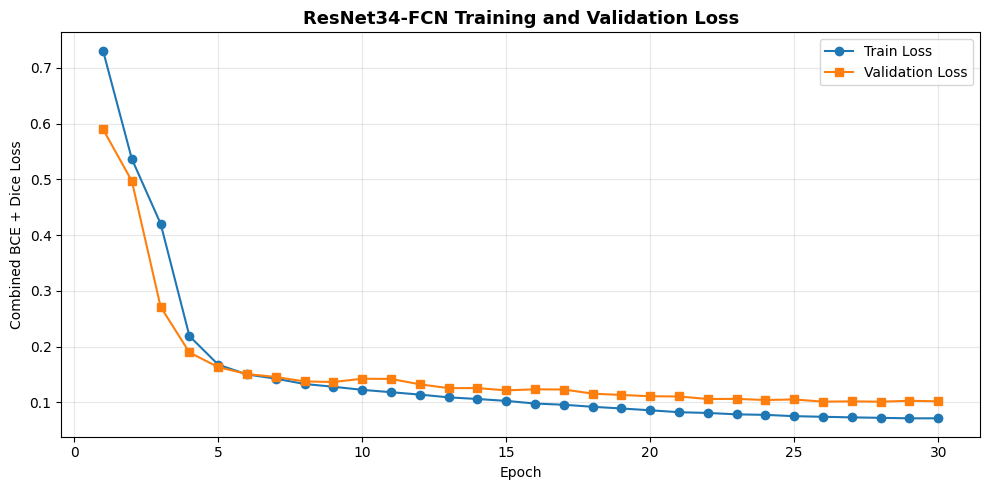


✓ Loss curve saved to: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/results/plots/resnet34_fcn_loss_curve.png

NOTE:
• Training/validation loss is shown for optimization analysis.
• Legacy F1/IoU training curves are intentionally omitted.
• Final segmentation metrics are obtained from independent
  global validation evaluation.


In [19]:
# 9.1 Training History Visualization
#
# The legacy F1/IoU values are intentionally NOT plotted because
# the old training-loop metric path is not used for final evaluation.
#
# Training and validation LOSS values remain valid for inspecting
# optimization behavior.

import json
import pandas as pd
import matplotlib.pyplot as plt


print("=" * 75)
print("  ResNet34-FCN Training History")
print("=" * 75)


history_records = []


# ---------------------------------------------------------------------------
# 1. Prefer history stored inside the completed checkpoint
# ---------------------------------------------------------------------------

if LATEST_CHECKPOINT_PATH.exists():

    checkpoint_for_history = torch.load(
        LATEST_CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False
    )

    stored_history = checkpoint_for_history.get(
        "history",
        []
    )

    if stored_history:
        history_records = stored_history
        print(
            f"✓ Loaded {len(history_records)} history records "
            f"from latest checkpoint."
        )


# ---------------------------------------------------------------------------
# 2. Fallback to CSV if checkpoint history is unavailable
# ---------------------------------------------------------------------------

if not history_records and csv_log_path.exists():

    df_history = pd.read_csv(
        csv_log_path
    )

    print(
        f"✓ Loaded {len(df_history)} history records "
        f"from CSV."
    )

else:

    if history_records:

        df_history = pd.DataFrame(
            history_records
        )

    elif csv_log_path.exists():

        df_history = pd.read_csv(
            csv_log_path
        )

    else:

        df_history = None


# ---------------------------------------------------------------------------
# 3. Validate required loss columns
# ---------------------------------------------------------------------------

if df_history is None:

    raise FileNotFoundError(
        "No training history was found in either the "
        "latest checkpoint or training_history.csv."
    )


required_columns = {
    "epoch",
    "train_loss",
    "val_loss"
}

missing_columns = required_columns - set(
    df_history.columns
)

if missing_columns:

    raise ValueError(
        f"Training history is missing required columns: "
        f"{sorted(missing_columns)}"
    )


# ---------------------------------------------------------------------------
# 4. Plot training and validation loss
# ---------------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    df_history["epoch"],
    df_history["train_loss"],
    marker="o",
    label="Train Loss"
)

ax.plot(
    df_history["epoch"],
    df_history["val_loss"],
    marker="s",
    label="Validation Loss"
)

ax.set_title(
    "ResNet34-FCN Training and Validation Loss",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel(
    "Epoch"
)

ax.set_ylabel(
    "Combined BCE + Dice Loss"
)

ax.grid(
    True,
    alpha=0.3
)

ax.legend()

plt.tight_layout()


# ---------------------------------------------------------------------------
# 5. Save figure
# ---------------------------------------------------------------------------

curve_path = (
    EXP_PLOTS /
    "resnet34_fcn_loss_curve.png"
)

plt.savefig(
    curve_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()


print()
print(f"✓ Loss curve saved to: {curve_path}")
print()
print("NOTE:")
print("• Training/validation loss is shown for optimization analysis.")
print("• Legacy F1/IoU training curves are intentionally omitted.")
print("• Final segmentation metrics are obtained from independent")
print("  global validation evaluation.")

## 10. Full Validation Benchmark Evaluation
Execute `scripts/evaluate.py` across all **2,367 validation samples** ($620,494,848$ total pixels) using the best saved ResNet34-FCN checkpoint.


In [20]:
# 10.1 Robust Full Validation Evaluation & Final Checkpoint Selection
#
# Both the legacy best checkpoint and the latest checkpoint are evaluated
# independently using scripts/evaluate.py.
#
# The checkpoint with the higher independently measured validation F1
# is selected as the final ResNet34-FCN model.

import json
import shutil
import subprocess
from pathlib import Path


# ---------------------------------------------------------------------------
# Evaluation directories
# ---------------------------------------------------------------------------

EVAL_ROOT = (
    EXP_EVALUATION /
    "checkpoint_selection"
)

EVAL_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


# ---------------------------------------------------------------------------
# Helper: read checkpoint epoch directly
# ---------------------------------------------------------------------------

def get_checkpoint_epoch(checkpoint_path):

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    return int(
        checkpoint.get(
            "epoch",
            0
        )
    )


# ---------------------------------------------------------------------------
# Helper: independently evaluate a checkpoint
# ---------------------------------------------------------------------------

def evaluate_checkpoint(
    checkpoint_path: Path,
    output_dir: Path
):

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    cmd = [
        sys.executable,
        "scripts/evaluate.py",

        "--checkpoint",
        str(checkpoint_path),

        "--model",
        "resnet34_fcn",

        "--val-dir",
        str(LOCAL_VAL_DIR),

        "--output-dir",
        str(output_dir),

        "--batch-size",
        "8",

        "--device",
        "cuda"
    ]

    print("\nRunning:")
    print(" ".join(cmd))
    print()

    subprocess.run(
        cmd,
        cwd=str(REPO_DIR),
        check=True
    )

    json_path = (
        output_dir /
        "eval_metrics.json"
    )

    if not json_path.exists():

        raise FileNotFoundError(
            f"Evaluation JSON was not created:\n{json_path}"
        )

    with open(
        json_path,
        "r",
        encoding="utf-8"
    ) as f:

        data = json.load(f)

    return data


# ---------------------------------------------------------------------------
# Checkpoint existence
# ---------------------------------------------------------------------------

if not BEST_CHECKPOINT_PATH.exists():

    raise FileNotFoundError(
        f"Missing legacy best checkpoint:\n"
        f"{BEST_CHECKPOINT_PATH}"
    )


if not LATEST_CHECKPOINT_PATH.exists():

    raise FileNotFoundError(
        f"Missing latest checkpoint:\n"
        f"{LATEST_CHECKPOINT_PATH}"
    )


# ---------------------------------------------------------------------------
# Read actual checkpoint epochs
# ---------------------------------------------------------------------------

best_epoch = get_checkpoint_epoch(
    BEST_CHECKPOINT_PATH
)

latest_epoch = get_checkpoint_epoch(
    LATEST_CHECKPOINT_PATH
)


BEST_EVAL_DIR = (
    EVAL_ROOT /
    f"legacy_best_epoch{best_epoch}"
)

LATEST_EVAL_DIR = (
    EVAL_ROOT /
    f"latest_epoch{latest_epoch}"
)


# ---------------------------------------------------------------------------
# Evaluate both checkpoints
# ---------------------------------------------------------------------------

print("=" * 75)
print("  RESNET34-FCN CHECKPOINT SELECTION")
print("=" * 75)

print(
    f"\nLegacy best checkpoint : Epoch {best_epoch}"
)

best_data = evaluate_checkpoint(
    BEST_CHECKPOINT_PATH,
    BEST_EVAL_DIR
)


print(
    f"\nLatest checkpoint      : Epoch {latest_epoch}"
)

latest_data = evaluate_checkpoint(
    LATEST_CHECKPOINT_PATH,
    LATEST_EVAL_DIR
)


# ---------------------------------------------------------------------------
# Extract independently evaluated metrics
# ---------------------------------------------------------------------------

best_metrics = best_data["metrics"]
latest_metrics = latest_data["metrics"]


# ---------------------------------------------------------------------------
# Display independent results
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("  INDEPENDENT VALIDATION RESULTS")
print("=" * 75)

print(
    f"Legacy best checkpoint | "
    f"Epoch {best_epoch} | "
    f"F1 = {best_metrics['f1'] * 100:.2f}% | "
    f"IoU = {best_metrics['iou'] * 100:.2f}%"
)

print(
    f"Latest checkpoint      | "
    f"Epoch {latest_epoch} | "
    f"F1 = {latest_metrics['f1'] * 100:.2f}% | "
    f"IoU = {latest_metrics['iou'] * 100:.2f}%"
)


# ---------------------------------------------------------------------------
# Select final checkpoint using independently evaluated F1
# ---------------------------------------------------------------------------

if best_metrics["f1"] >= latest_metrics["f1"]:

    selected_checkpoint = (
        BEST_CHECKPOINT_PATH
    )

    selected_data = best_data

    selected_epoch = best_epoch

    selected_label = (
        "Legacy best checkpoint"
    )

    selected_eval_source = (
        BEST_EVAL_DIR /
        "eval_metrics.json"
    )

else:

    selected_checkpoint = (
        LATEST_CHECKPOINT_PATH
    )

    selected_data = latest_data

    selected_epoch = latest_epoch

    selected_label = (
        "Latest checkpoint"
    )

    selected_eval_source = (
        LATEST_EVAL_DIR /
        "eval_metrics.json"
    )


# ---------------------------------------------------------------------------
# Stable final checkpoint paths
# ---------------------------------------------------------------------------

SELECTED_CHECKPOINT_PATH = (
    EXP_CHECKPOINTS /
    "selected_model.pth"
)

SELECTED_EVAL_JSON = (
    EVAL_ROOT /
    "selected_eval_metrics.json"
)


# ---------------------------------------------------------------------------
# Save selected checkpoint and evaluation
# ---------------------------------------------------------------------------

shutil.copy2(
    selected_checkpoint,
    SELECTED_CHECKPOINT_PATH
)

shutil.copy2(
    selected_eval_source,
    SELECTED_EVAL_JSON
)


# ---------------------------------------------------------------------------
# Final selected-model report
# ---------------------------------------------------------------------------

m = selected_data["metrics"]
cm = selected_data["confusion_matrix"]


print("\n" + "=" * 75)
print("  SELECTED FINAL RESNET34-FCN CHECKPOINT")
print("=" * 75)

print(
    f"Selection : {selected_label}"
)

print(
    f"Epoch     : {selected_epoch}"
)

print(
    f"Checkpoint: {SELECTED_CHECKPOINT_PATH}"
)

print()

print(
    f"F1 / Dice       : {m['f1'] * 100:.2f}%"
)

print(
    f"IoU             : {m['iou'] * 100:.2f}%"
)

print(
    f"Precision       : {m['precision'] * 100:.2f}%"
)

print(
    f"Recall          : {m['recall'] * 100:.2f}%"
)

print(
    f"Pixel Accuracy  : {m['accuracy'] * 100:.2f}%"
)

print()

print(
    f"True Positives  : {cm['TP']:,}"
)

print(
    f"False Positives : {cm['FP']:,}"
)

print(
    f"False Negatives : {cm['FN']:,}"
)

print(
    f"True Negatives  : {cm['TN']:,}"
)

print("=" * 75)

print()
print(
    "✓ Final checkpoint selected using independently evaluated "
    "global validation F1."
)

print(
    "✓ Epoch number was read directly from the checkpoint."
)

print(
    "✓ Final checkpoint copied to selected_model.pth."
)

print(
    f"✓ Evaluation JSON saved to: {SELECTED_EVAL_JSON}"
)

  RESNET34-FCN CHECKPOINT SELECTION

Legacy best checkpoint : Epoch 29

Running:
/usr/bin/python3 scripts/evaluate.py --checkpoint /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/checkpoints/best_model_corrected.pth --model resnet34_fcn --val-dir /content/glid_clean/val --output-dir /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/results/evaluation/checkpoint_selection/legacy_best_epoch29 --batch-size 8 --device cuda


Latest checkpoint      : Epoch 30

Running:
/usr/bin/python3 scripts/evaluate.py --checkpoint /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/checkpoints/latest_model_corrected.pth --model resnet34_fcn --val-dir /content/glid_clean/val --output-dir /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/results/evaluation/checkpoint_selection/latest_epoch30 --batch-size 8 --device cuda


  INDEPENDENT VALIDATION RESULTS
Legacy best checkpoint | Epoch 29

## 11. DeepLabV3+ vs. ResNet34-FCN Comparative Benchmark

Generate a side-by-side benchmark table comparing the **DeepLabV3+ advanced model** (ResNet-50 + ASPP) against the **ResNet34-FCN baseline** on the identical validation split ($N=2,367$).

> **Academic Rigor & Fairness Notice**:
> - Both architectures were trained and evaluated on the exact same official GLID validation split ($2,367$ samples, $620,494,848$ total pixels).
> - Both architectures use the exact same input standardization (ImageNet $\mu, \sigma$), binary decision threshold ($0.5$), and global confusion matrix metric formulation.
> - All reported numbers represent **validation metrics**, not independent unannotated field test scenes.


In [21]:

# ================================================================
# 11.1 RESNET34-FCN vs DEEPLABV3+
# Professional Same-Split Validation Comparison
# ================================================================

import json
import csv
import html
from pathlib import Path
from contextlib import nullcontext

import torch
from tqdm.auto import tqdm
from IPython.display import display, HTML


# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

DEEPLAB_CHECKPOINT_PATH = Path(
    "/content/drive/MyDrive/Glacial_Lake_Segmentation/"
    "training/deeplabv3plus_fast/checkpoints/best_amp_model.pth"
)

assert DEEPLAB_CHECKPOINT_PATH.exists(), (
    f"DeepLabV3+ checkpoint missing: {DEEPLAB_CHECKPOINT_PATH}"
)

assert Path(SELECTED_EVAL_JSON).exists(), (
    f"ResNet34-FCN evaluation JSON missing: {SELECTED_EVAL_JSON}"
)

assert len(val_loader.dataset) > 0, "Validation dataset is empty."


THRESHOLD = 0.5

deeplab_cfg = {
    "model": {
        "name": "deeplabv3plus",
        "pretrained": False,
        "num_classes": 1,
        "freeze_encoder": False,
        "aspp_dilations": [6, 12, 18],
    }
}


# ------------------------------------------------
# 2. SHARED METRIC FUNCTIONS
# ------------------------------------------------

def global_metrics_from_logits(logits, masks, counts):

    probabilities = torch.sigmoid(logits.float())

    predictions = probabilities >= THRESHOLD
    ground_truth = masks >= 0.5

    counts["TP"] += torch.logical_and(
        predictions, ground_truth
    ).sum().item()

    counts["FP"] += torch.logical_and(
        predictions, ~ground_truth
    ).sum().item()

    counts["FN"] += torch.logical_and(
        ~predictions, ground_truth
    ).sum().item()

    counts["TN"] += torch.logical_and(
        ~predictions, ~ground_truth
    ).sum().item()

    return counts


def metrics_from_cm(cm):

    tp = cm["TP"]
    fp = cm["FP"]
    fn = cm["FN"]
    tn = cm["TN"]

    def safe_divide(numerator, denominator):
        return numerator / denominator if denominator else 0.0

    return {
        "f1": safe_divide(2 * tp, 2 * tp + fp + fn),
        "iou": safe_divide(tp, tp + fp + fn),
        "precision": safe_divide(tp, tp + fp),
        "recall": safe_divide(tp, tp + fn),
        "accuracy": safe_divide(
            tp + tn, tp + tn + fp + fn
        )
    }


# ------------------------------------------------
# 3. LOAD RESNET34-FCN EVALUATION
# ------------------------------------------------

print("Loading ResNet34-FCN evaluation...")

with open(SELECTED_EVAL_JSON, "r", encoding="utf-8") as f:
    resnet_eval = json.load(f)

resnet_metrics = resnet_eval["metrics"]

required_metrics = [
    "f1", "iou", "precision", "recall", "accuracy"
]

for key in required_metrics:
    assert key in resnet_metrics, (
        f"Missing ResNet34-FCN metric: {key}"
    )

print("ResNet34-FCN evaluation loaded.")


# ------------------------------------------------
# 4. LOAD DEEPLABV3+
# ------------------------------------------------

print("\nLoading DeepLabV3+ checkpoint...")

deeplab_model = build_model(deeplab_cfg).to(device)

deeplab_checkpoint = torch.load(
    DEEPLAB_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

deeplab_model.load_state_dict(
    deeplab_checkpoint["model_state_dict"]
)

deeplab_model.eval()

deeplab_epoch = deeplab_checkpoint.get("epoch", "Unknown")

print(f"DeepLabV3+ checkpoint epoch: {deeplab_epoch}")


# ------------------------------------------------
# 5. EVALUATE DEEPLABV3+ ON VALIDATION DATA
# ------------------------------------------------

print("\nEvaluating DeepLabV3+ on validation dataset...")

deeplab_cm = {
    "TP": 0,
    "FP": 0,
    "FN": 0,
    "TN": 0
}

evaluated_samples = 0

use_amp = device.type == "cuda"

with torch.inference_mode():

    for images, masks in tqdm(
        val_loader,
        desc="DeepLabV3+ validation",
        unit="batch"
    ):

        batch_size = images.shape[0]
        evaluated_samples += batch_size

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        amp_context = (
            torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            )
            if use_amp else nullcontext()
        )

        with amp_context:
            logits = deeplab_model(images)

        assert logits.shape == masks.shape, (
            f"Prediction/mask shape mismatch: "
            f"{logits.shape} vs {masks.shape}"
        )

        deeplab_cm = global_metrics_from_logits(
            logits,
            masks,
            deeplab_cm
        )


deeplab_metrics = metrics_from_cm(deeplab_cm)

print(f"\nDeepLabV3+ evaluation completed.")
print(f"Samples evaluated: {evaluated_samples:,}")


# ------------------------------------------------
# 6. COUNT MODEL PARAMETERS
# ------------------------------------------------

print("\nCalculating model parameters...")

resnet_model_for_count = build_model({
    "model": {
        "name": "resnet34_fcn",
        "pretrained": False,
        "num_classes": 1,
        "freeze_encoder": False
    }
})

resnet_params = sum(
    p.numel() for p in resnet_model_for_count.parameters()
)

deeplab_params = sum(
    p.numel() for p in deeplab_model.parameters()
)

del resnet_model_for_count

# Keep the comparison tied to the actual evaluated data.
validation_samples = evaluated_samples


# ------------------------------------------------
# 7. BUILD COMPARISON DATA
# ------------------------------------------------

comparison = {
    "validation_samples": validation_samples,
    "threshold": THRESHOLD,
    "evaluation_method": "Global pixel-level confusion matrix",
    "ResNet34-FCN": {
        "epoch": resnet_eval.get("checkpoint_epoch", "Selected"),
        "parameters": resnet_params,
        **{k: float(resnet_metrics[k]) for k in required_metrics},
        "hardware": "Tesla T4 / CUDA + AMP"
    },
    "DeepLabV3+": {
        "epoch": deeplab_epoch,
        "parameters": deeplab_params,
        **{k: float(deeplab_metrics[k]) for k in required_metrics},
        "hardware": "Tesla T4 / CUDA + AMP"
    }
}



# ------------------------------------------------
# 8. DISPLAY CLEAN COMPARISON TABLE
# ------------------------------------------------

import pandas as pd
from IPython.display import display, Markdown

resnet_data = comparison["ResNet34-FCN"]
deeplab_data = comparison["DeepLabV3+"]

table_data = {
    "Metric": [
        "Selected Epoch",
        "Model Parameters",
        "F1 / Dice",
        "IoU",
        "Precision",
        "Recall",
        "Pixel Accuracy",
        "Training Hardware"
    ],

    "ResNet34-FCN": [
        resnet_data["epoch"],
        f'{resnet_data["parameters"]:,}',
        f'{resnet_data["f1"] * 100:.2f}%',
        f'{resnet_data["iou"] * 100:.2f}%',
        f'{resnet_data["precision"] * 100:.2f}%',
        f'{resnet_data["recall"] * 100:.2f}%',
        f'{resnet_data["accuracy"] * 100:.2f}%',
        resnet_data["hardware"]
    ],

    "DeepLabV3+": [
        deeplab_data["epoch"],
        f'{deeplab_data["parameters"]:,}',
        f'{deeplab_data["f1"] * 100:.2f}%',
        f'{deeplab_data["iou"] * 100:.2f}%',
        f'{deeplab_data["precision"] * 100:.2f}%',
        f'{deeplab_data["recall"] * 100:.2f}%',
        f'{deeplab_data["accuracy"] * 100:.2f}%',
        deeplab_data["hardware"]
    ]
}

df = pd.DataFrame(table_data)

display(Markdown(
    "## ResNet34-FCN vs DeepLabV3+ Validation Comparison\n\n"
    f"**Validation samples:** {comparison['validation_samples']:,}  \n"
    f"**Threshold:** {comparison['threshold']}  \n"
    f"**Evaluation:** {comparison['evaluation_method']}"
))

display(
    df.style
    .hide(axis="index")
    .set_properties(**{
        "text-align": "center",
        "padding": "8px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("padding", "8px")
            ]
        }
    ])
)


# ------------------------------------------------
# 9. SAVE COMPARISON OUTPUTS
# ------------------------------------------------

EXP_COMPARISON.mkdir(
    parents=True,
    exist_ok=True
)

# JSON
comparison_json = (
    EXP_COMPARISON /
    "resnet34_vs_deeplabv3_comparison.json"
)

with open(comparison_json, "w", encoding="utf-8") as f:
    json.dump(comparison, f, indent=2)


# CSV
comparison_csv = (
    EXP_COMPARISON /
    "resnet34_vs_deeplabv3_comparison.csv"
)

df.to_csv(comparison_csv, index=False)


# Markdown
comparison_md = (
    EXP_COMPARISON /
    "comparison_table.md"
)

markdown_table = [
    "# ResNet34-FCN vs DeepLabV3+ Validation Comparison",
    "",
    f"**Validation samples:** {comparison['validation_samples']:,}",
    f"**Threshold:** {comparison['threshold']}",
    "",
    "| Metric | ResNet34-FCN | DeepLabV3+ |",
    "|---|---:|---:|"
]

for _, row in df.iterrows():
    markdown_table.append(
        f"| {row['Metric']} | "
        f"{row['ResNet34-FCN']} | "
        f"{row['DeepLabV3+']} |"
    )

markdown_table.extend([
    "",
    "> These are validation metrics, not independent test-set results."
])

comparison_md.write_text(
    "\n".join(markdown_table),
    encoding="utf-8"
)


# ------------------------------------------------
# 10. FINAL OUTPUT
# ------------------------------------------------

print("\n" + "=" * 70)
print("COMPARISON REPORT SAVED SUCCESSFULLY")
print("=" * 70)

print(f"\nValidation samples: {comparison['validation_samples']:,}")

print("\nSaved files:")
print("JSON:", comparison_json)
print("CSV:", comparison_csv)
print("Markdown:", comparison_md)

print("\nNote: These are validation results, not independent test-set results.")

Loading ResNet34-FCN evaluation...
ResNet34-FCN evaluation loaded.

Loading DeepLabV3+ checkpoint...
DeepLabV3+ checkpoint epoch: 26

Evaluating DeepLabV3+ on validation dataset...


DeepLabV3+ validation:   0%|          | 0/296 [00:00<?, ?batch/s]


DeepLabV3+ evaluation completed.
Samples evaluated: 2,367

Calculating model parameters...


## ResNet34-FCN vs DeepLabV3+ Validation Comparison

**Validation samples:** 2,367  
**Threshold:** 0.5  
**Evaluation:** Global pixel-level confusion matrix

Metric,ResNet34-FCN,DeepLabV3+
Selected Epoch,Selected,26
Model Parameters,"24,079,153","40,347,041"
F1 / Dice,93.41%,93.97%
IoU,87.64%,88.62%
Precision,95.26%,95.61%
Recall,91.63%,92.38%
Pixel Accuracy,99.70%,99.73%
Training Hardware,Tesla T4 / CUDA + AMP,Tesla T4 / CUDA + AMP



COMPARISON REPORT SAVED SUCCESSFULLY

Validation samples: 2,367

Saved files:
JSON: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/comparison/resnet34_vs_deeplabv3_comparison.json
CSV: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/comparison/resnet34_vs_deeplabv3_comparison.csv
Markdown: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/comparison/comparison_table.md

Note: These are validation results, not independent test-set results.


## 12. Qualitative Visual Predictions
Generate 4-panel visual comparison figures (Satellite RGB, Ground Truth, ResNet34-FCN Prediction, Probability Heatmap) for representative validation scenes.


✓ Loaded selected ResNet34-FCN checkpoint (epoch 29)


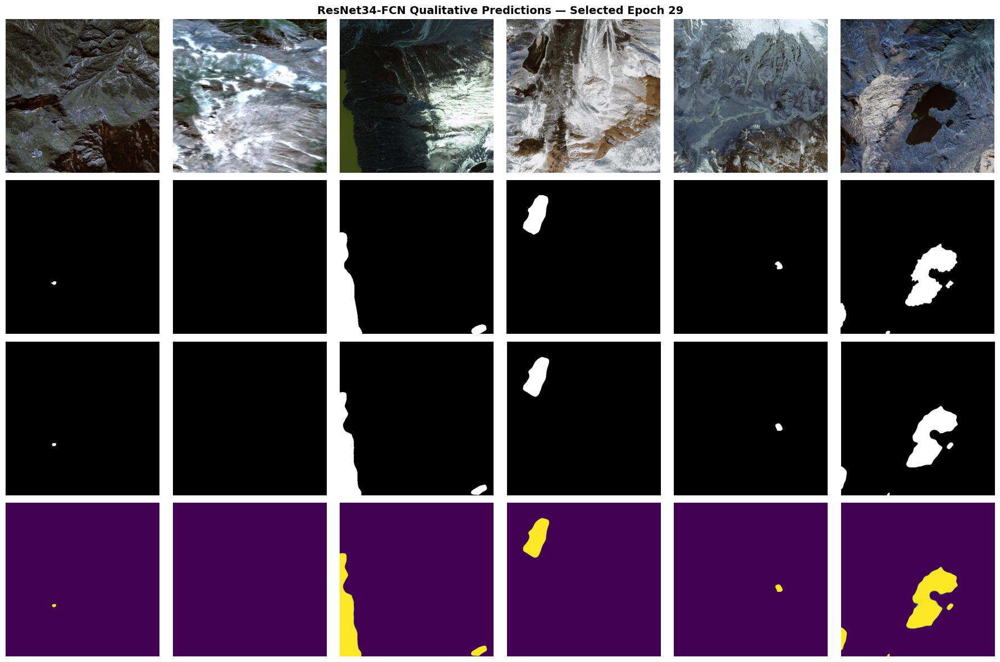

✓ Qualitative predictions saved to: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/results/predictions/selected_model_validation_predictions.png


In [22]:
# 12.1 Qualitative Predictions from the Selected Final Checkpoint

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader


if not SELECTED_CHECKPOINT_PATH.exists():

    raise FileNotFoundError(
        f"Selected checkpoint not found:\n"
        f"{SELECTED_CHECKPOINT_PATH}\n"
        "Run Cell 10.1 first."
    )


# ---------------------------------------------------------------------------
# Load selected checkpoint into a fresh model
# ---------------------------------------------------------------------------

selected_model = build_model({
    "model": {
        "name": "resnet34_fcn",
        "pretrained": False,
        "num_classes": 1,
        "freeze_encoder": False
    }
}).to(device)

selected_checkpoint = torch.load(
    SELECTED_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

selected_model.load_state_dict(
    selected_checkpoint["model_state_dict"]
)

selected_model.eval()

selected_epoch = selected_checkpoint.get(
    "epoch",
    "unknown"
)

print(
    f"✓ Loaded selected ResNet34-FCN checkpoint "
    f"(epoch {selected_epoch})"
)


# ---------------------------------------------------------------------------
# Load validation samples
# ---------------------------------------------------------------------------

vis_loader = DataLoader(
    val_ds,
    batch_size=6,
    shuffle=False
)

imgs, msks = next(
    iter(vis_loader)
)


# ---------------------------------------------------------------------------
# Prediction
# ---------------------------------------------------------------------------

with torch.no_grad():

    x = imgs.to(
        device,
        memory_format=torch.channels_last
    )

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):

        logits = selected_model(x)

        probs = torch.sigmoid(
            logits
        )

        preds = (
            probs >= 0.5
        ).float()


# ---------------------------------------------------------------------------
# Convert normalized RGB back to display space
# ---------------------------------------------------------------------------

imgs_np = (
    imgs
    .permute(0, 2, 3, 1)
    .cpu()
    .numpy()
)

mean = np.array(
    [0.485, 0.456, 0.406]
)

std = np.array(
    [0.229, 0.224, 0.225]
)

imgs_np = np.clip(
    imgs_np * std + mean,
    0.0,
    1.0
)

gt_np = (
    msks
    .squeeze(1)
    .cpu()
    .numpy()
)

pred_np = (
    preds
    .squeeze(1)
    .cpu()
    .numpy()
)

prob_np = (
    probs
    .squeeze(1)
    .float()
    .cpu()
    .numpy()
)


# ---------------------------------------------------------------------------
# Figure
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(
    4,
    6,
    figsize=(18, 12)
)

for i in range(6):

    # RGB
    axes[0, i].imshow(
        imgs_np[i]
    )

    axes[0, i].axis("off")

    if i == 0:
        axes[0, i].set_ylabel(
            "Satellite RGB",
            fontsize=10,
            fontweight="bold"
        )


    # Ground truth
    axes[1, i].imshow(
        gt_np[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, i].axis("off")

    if i == 0:
        axes[1, i].set_ylabel(
            "Ground Truth",
            fontsize=10,
            fontweight="bold"
        )


    # Prediction
    axes[2, i].imshow(
        pred_np[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[2, i].axis("off")

    if i == 0:
        axes[2, i].set_ylabel(
            "Predicted Mask",
            fontsize=10,
            fontweight="bold"
        )


    # Probability
    axes[3, i].imshow(
        prob_np[i],
        cmap="viridis",
        vmin=0,
        vmax=1
    )

    axes[3, i].axis("off")

    if i == 0:
        axes[3, i].set_ylabel(
            "Lake Probability",
            fontsize=10,
            fontweight="bold"
        )


plt.suptitle(
    f"ResNet34-FCN Qualitative Predictions — Selected Epoch {selected_epoch}",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

vis_save_path = (
    EXP_PREDICTIONS /
    "selected_model_validation_predictions.png"
)

plt.savefig(
    vis_save_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print(
    f"✓ Qualitative predictions saved to: "
    f"{vis_save_path}"
)

## 13. Representative predictions and worst-case validation analysis

This section is inference-only. It reloads the selected ResNet34-FCN checkpoint into a fresh model, uses threshold 0.5, reports per-image Dice/IoU/precision/recall, and saves figures/CSV files under `experiments/resnet34_fcn_colab/visualizations/`. TP is green, FP red, and FN blue.

Evaluated 2,367/2,367 validation images.
Per-image metrics CSV: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/visualizations/validation_per_image_metrics.csv
Dice threshold: 0.50 | selected checkpoint epoch: 29

Representative validation predictions


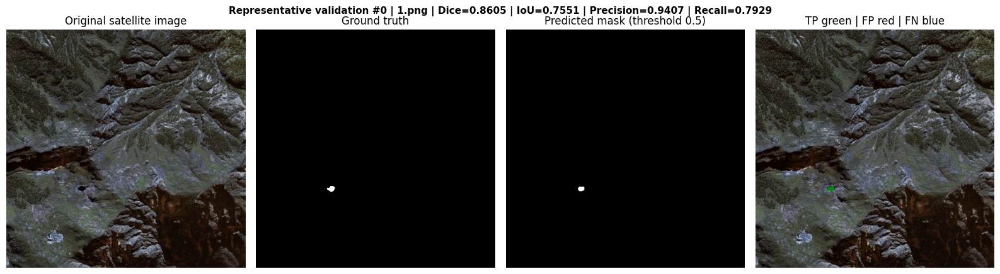

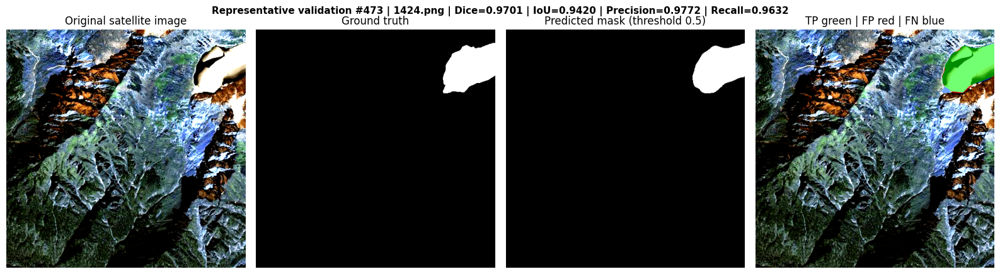

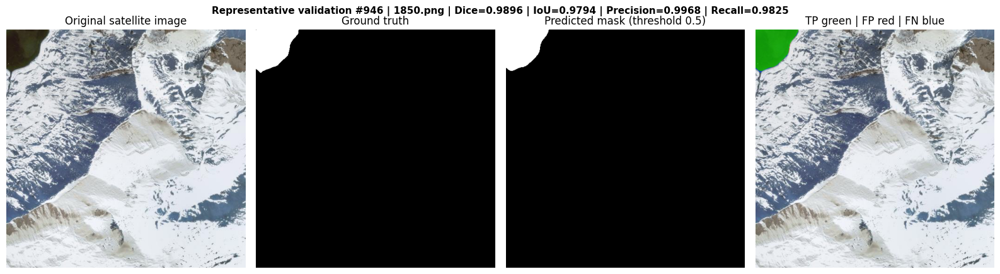

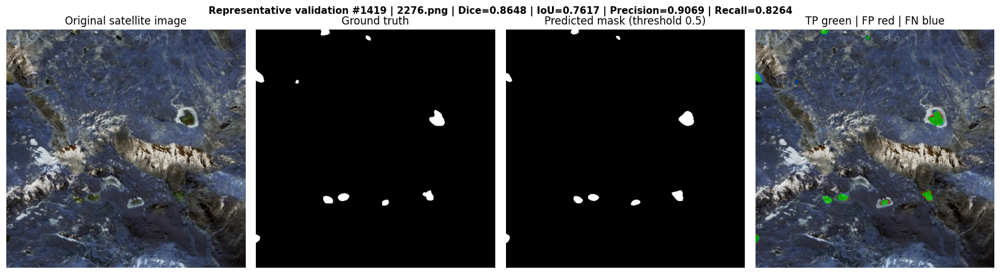

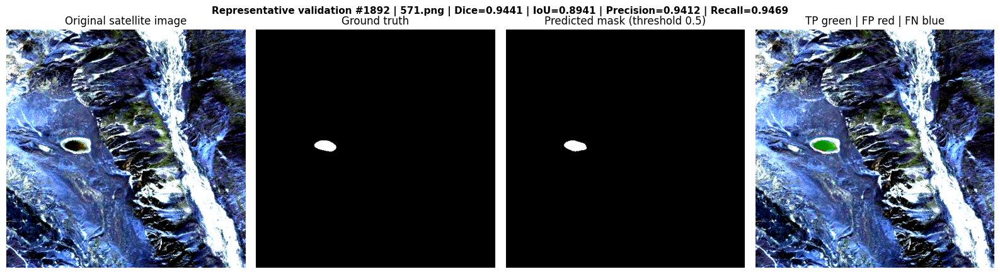

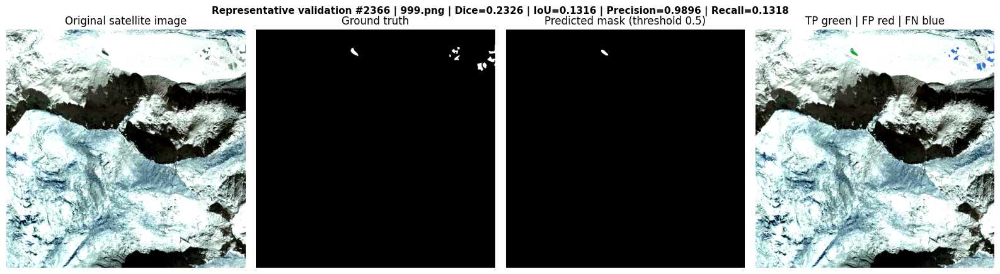


Worst-performing validation cases, sorted by Dice ascending


,index,image,dice,iou,precision,recall,tp,fp,fn,gt_pixels,pred_pixels
1,1,10.png,0.0,0.0,0.0,0.0,0,0,2,2,0
63,63,1055.png,0.0,0.0,0.0,0.0,0,0,3,3,0
93,93,1082.png,0.0,0.0,0.0,0.0,0,0,381,381,0
102,102,1090.png,0.0,0.0,0.0,0.0,0,0,75,75,0
111,111,1099.png,0.0,0.0,0.0,0.0,0,0,1099,1099,0
124,124,111.png,0.0,0.0,0.0,0.0,0,0,2533,2533,0
131,131,1116.png,0.0,0.0,0.0,0.0,0,0,1312,1312,0
133,133,1118.png,0.0,0.0,0.0,0.0,0,0,1715,1715,0
140,140,1124.png,0.0,0.0,0.0,0.0,0,124,264,264,124
142,142,1126.png,0.0,0.0,0.0,0.0,0,0,451,451,0


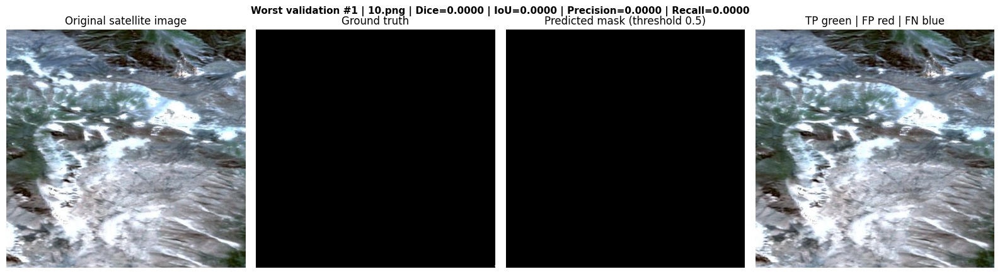

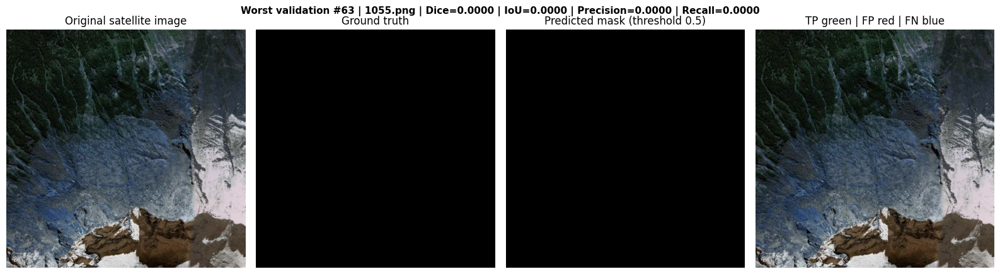

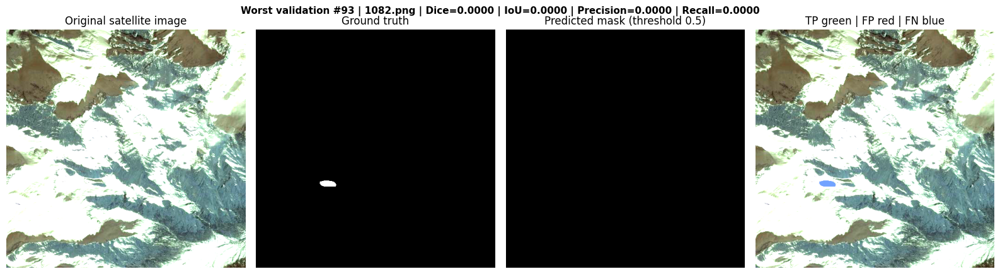

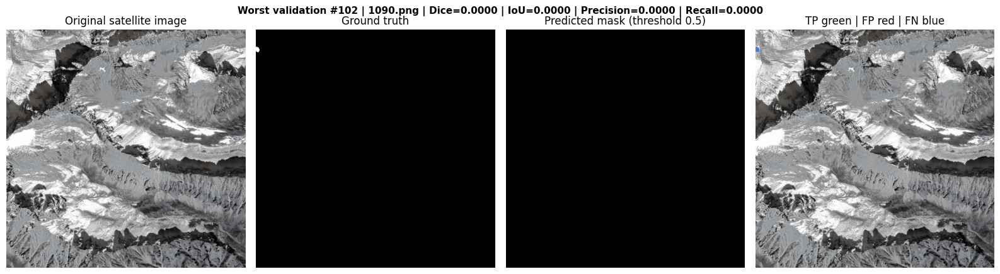

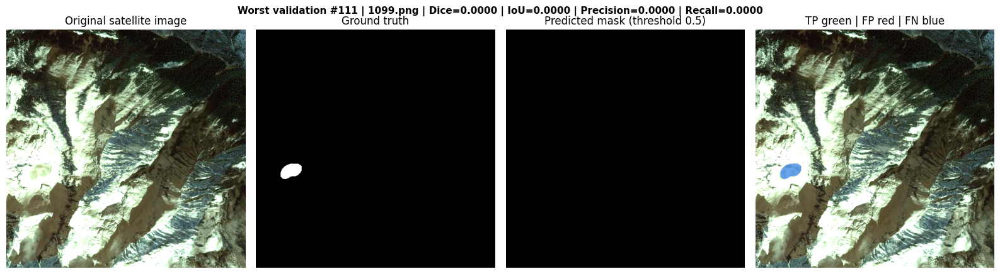

...

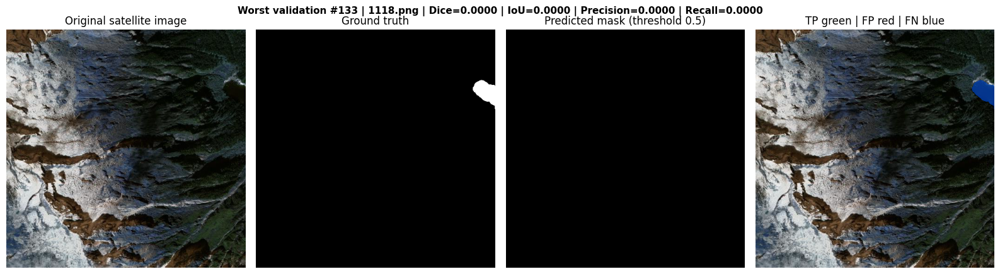

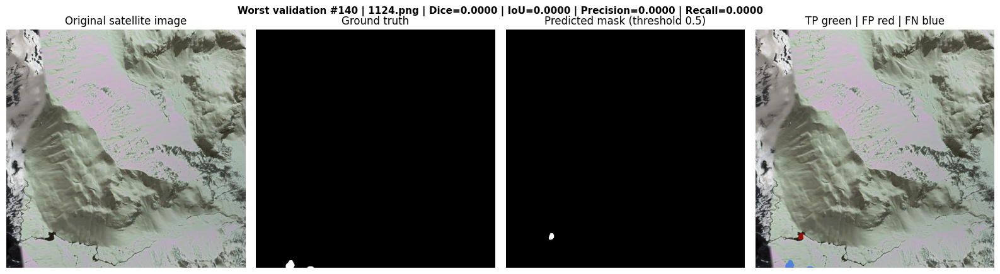

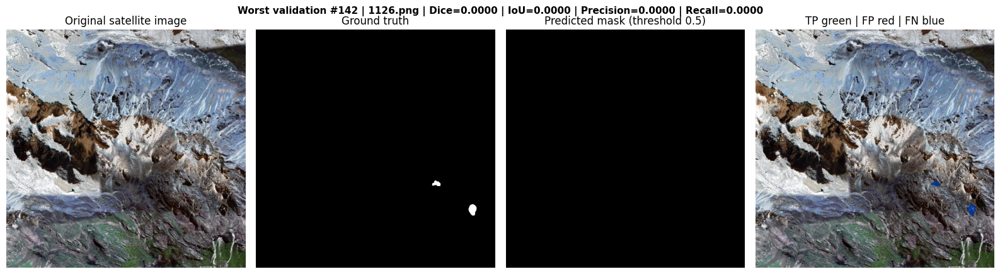

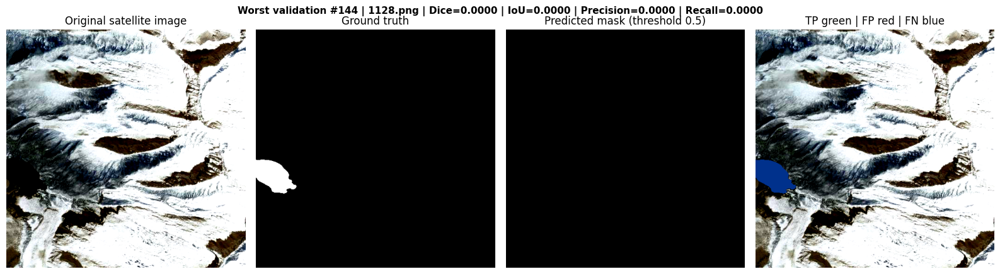

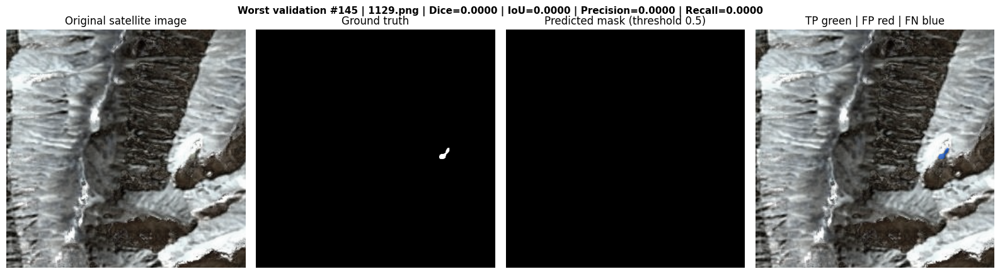


Visualization artifacts saved separately from checkpoints and existing evaluation outputs:
  Folder                  : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/visualizations
  Per-image metrics       : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/visualizations/validation_per_image_metrics.csv
  Lowest-Dice case metrics: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/visualizations/lowest_dice_validation_cases.csv
  Representative figures  : 6
  Worst-case figures      : 12


In [23]:
# 13. Representative and worst-case validation analysis (inference only)
# Uses the selected checkpoint, evaluation mode, and threshold=0.5.
# No optimizer/training calls are made and model weights are never modified.

import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from pathlib import Path

VIS_DIR = EXP_DIR / "visualizations"
VIS_DIR.mkdir(parents=True, exist_ok=True)
VIS_THRESHOLD = 0.5
N_REPRESENTATIVE = 6
N_WORST = 12
VIS_BATCH_SIZE = 8

if not SELECTED_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Selected checkpoint not found: {SELECTED_CHECKPOINT_PATH}. "
        "Run the existing full-validation/checkpoint-selection cell first."
    )

# A fresh inference model prevents any accidental mutation of the training model.
vis_model = build_model({
    "model": {
        "name": "resnet34_fcn",
        "pretrained": False,
        "num_classes": 1,
        "freeze_encoder": False
    }
}).to(device)
vis_checkpoint = torch.load(SELECTED_CHECKPOINT_PATH, map_location=device, weights_only=False)
vis_model.load_state_dict(vis_checkpoint["model_state_dict"])
vis_model.eval()
vis_epoch = vis_checkpoint.get("epoch", "unknown")

VIS_MEAN = np.asarray([0.485, 0.456, 0.406], dtype=np.float32)
VIS_STD = np.asarray([0.229, 0.224, 0.225], dtype=np.float32)

def _unpack_batch(batch):
    # Existing GLIDDataset normally returns (image, mask). Be tolerant of an optional metadata field.
    if not isinstance(batch, (tuple, list)) or len(batch) < 2:
        raise ValueError("GLIDDataset must return at least (image, mask).")
    return batch[0], batch[1]

def _to_binary_mask(mask_tensor):
    arr = mask_tensor.detach().float().cpu().numpy()
    arr = np.squeeze(arr)
    return (arr > 0).astype(np.uint8)

def _safe_scores(gt, pred):
    gt = np.asarray(gt, dtype=bool)
    pred = np.asarray(pred, dtype=bool)
    tp = int(np.logical_and(gt, pred).sum())
    fp = int(np.logical_and(~gt, pred).sum())
    fn = int(np.logical_and(gt, ~pred).sum())
    gt_sum, pred_sum = int(gt.sum()), int(pred.sum())
    dice_den = 2 * tp + fp + fn
    iou_den = tp + fp + fn
    # Empty GT + empty prediction is a perfect empty-mask match.
    dice = (2 * tp / dice_den) if dice_den else 1.0
    iou = (tp / iou_den) if iou_den else 1.0
    precision = (tp / (tp + fp)) if (tp + fp) else (1.0 if gt_sum == 0 else 0.0)
    recall = (tp / (tp + fn)) if (tp + fn) else 1.0
    return {
        "dice": float(dice), "iou": float(iou),
        "precision": float(precision), "recall": float(recall),
        "tp": tp, "fp": fp, "fn": fn,
        "gt_pixels": gt_sum, "pred_pixels": pred_sum
    }

def _display_rgb(image_tensor):
    x = image_tensor.detach().float().cpu().permute(1, 2, 0).numpy()
    return np.clip(x * VIS_STD + VIS_MEAN, 0, 1)

def _predict_tensor_batch(images):
    x = images.to(device)
    if device.type == "cuda":
        x = x.to(memory_format=torch.channels_last)
        with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = vis_model(x)
            probs = torch.sigmoid(logits.float())
    else:
        with torch.no_grad():
            logits = vis_model(x)
            probs = torch.sigmoid(logits.float())
    return probs.detach().cpu()

def _overlay_errors(image_rgb, gt, pred):
    # RGB overlay: TP green, FP red, FN blue; image remains visible underneath.
    overlay = image_rgb.copy()
    tp = (gt == 1) & (pred == 1)
    fp = (gt == 0) & (pred == 1)
    fn = (gt == 1) & (pred == 0)
    tint = np.zeros_like(overlay)
    tint[tp] = (0.0, 1.0, 0.0)
    tint[fp] = (1.0, 0.0, 0.0)
    tint[fn] = (0.0, 0.35, 1.0)
    active = tp | fp | fn
    overlay[active] = 0.45 * overlay[active] + 0.55 * tint[active]
    return overlay

def _resolve_image_label(index):
    # Dataset is built from sorted, matched PNG names in the clean validation view.
    name = val_names[index] if index < len(val_names) else f"validation_index_{index}"
    return name

def _load_one_prediction(index):
    image_tensor, mask_tensor = _unpack_batch(val_ds[index])
    probs = _predict_tensor_batch(image_tensor.unsqueeze(0))[0, 0].numpy()
    gt = _to_binary_mask(mask_tensor)
    pred = (probs >= VIS_THRESHOLD).astype(np.uint8)
    scores = _safe_scores(gt, pred)
    return image_tensor, gt, pred, probs, scores

def _plot_case(index, image_tensor, gt, pred, scores, output_path=None, title_prefix="Validation"):
    rgb = _display_rgb(image_tensor)
    overlay = _overlay_errors(rgb, gt, pred)
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
    axes[0].imshow(rgb)
    axes[0].set_title("Original satellite image")
    axes[1].imshow(gt, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Ground truth")
    axes[2].imshow(pred, cmap="gray", vmin=0, vmax=1)
    axes[2].set_title("Predicted mask (threshold 0.5)")
    axes[3].imshow(overlay)
    axes[3].set_title("TP green | FP red | FN blue")
    for ax in axes:
        ax.axis("off")
    filename = _resolve_image_label(index)
    fig.suptitle(
        f"{title_prefix} #{index} | {filename} | Dice={scores['dice']:.4f} | "
        f"IoU={scores['iou']:.4f} | Precision={scores['precision']:.4f} | Recall={scores['recall']:.4f}",
        fontsize=11, fontweight="bold"
    )
    fig.tight_layout()
    if output_path is not None:
        fig.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# ---------------------------------------------------------------------------
# Evaluate every validation image once and retain scalar per-image metrics.
# ---------------------------------------------------------------------------
vis_loader = DataLoader(
    val_ds, batch_size=VIS_BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=(device.type == "cuda")
)
rows = []
offset = 0
with torch.inference_mode():
    for batch in vis_loader:
        images, masks = _unpack_batch(batch)
        prob_batch = _predict_tensor_batch(images)
        for j in range(images.shape[0]):
            gt = _to_binary_mask(masks[j])
            pred = (prob_batch[j, 0].numpy() >= VIS_THRESHOLD).astype(np.uint8)
            scores = _safe_scores(gt, pred)
            rows.append({
                "index": offset,
                "image": _resolve_image_label(offset),
                "mask": _resolve_image_label(offset),
                **scores
            })
            offset += 1

if len(rows) != len(val_ds):
    raise RuntimeError(f"Per-image evaluation count mismatch: {len(rows)} vs {len(val_ds)}")

per_image_df = pd.DataFrame(rows).sort_values(["dice", "iou", "index"], ascending=[True, True, True])
csv_path = VIS_DIR / "validation_per_image_metrics.csv"
per_image_df.to_csv(csv_path, index=False)
print(f"Evaluated {len(per_image_df):,}/{len(val_ds):,} validation images.")
print(f"Per-image metrics CSV: {csv_path}")
print(f"Dice threshold: {VIS_THRESHOLD:.2f} | selected checkpoint epoch: {vis_epoch}")

# ---------------------------------------------------------------------------
# Representative examples: evenly spaced through the original validation order.
# ---------------------------------------------------------------------------
rep_indices = sorted(set(np.linspace(0, len(val_ds) - 1, min(N_REPRESENTATIVE, len(val_ds)), dtype=int).tolist()))
print("\nRepresentative validation predictions")
for idx in rep_indices:
    image_tensor, gt, pred, probs, scores = _load_one_prediction(idx)
    _plot_case(
        idx, image_tensor, gt, pred, scores,
        output_path=VIS_DIR / f"representative_{idx:04d}.png",
        title_prefix="Representative validation"
    )

# ---------------------------------------------------------------------------
# Worst cases: sorted by per-image Dice ascending. Zero-Dice and empty predictions
# remain eligible and are not filtered out.
# ---------------------------------------------------------------------------
worst_df = per_image_df.sort_values(["dice", "iou", "index"], ascending=[True, True, True]).head(min(N_WORST, len(per_image_df)))
worst_csv = VIS_DIR / "lowest_dice_validation_cases.csv"
worst_df.to_csv(worst_csv, index=False)
print("\nWorst-performing validation cases, sorted by Dice ascending")
display(worst_df[["index", "image", "dice", "iou", "precision", "recall", "tp", "fp", "fn", "gt_pixels", "pred_pixels"]])

for _, row in worst_df.iterrows():
    idx = int(row["index"])
    image_tensor, gt, pred, probs, scores = _load_one_prediction(idx)
    _plot_case(
        idx, image_tensor, gt, pred, scores,
        output_path=VIS_DIR / f"worst_dice_{idx:04d}.png",
        title_prefix="Worst validation"
    )

print("\nVisualization artifacts saved separately from checkpoints and existing evaluation outputs:")
print(f"  Folder                  : {VIS_DIR}")
print(f"  Per-image metrics       : {csv_path}")
print(f"  Lowest-Dice case metrics: {worst_csv}")
print(f"  Representative figures  : {len(rep_indices)}")
print(f"  Worst-case figures      : {len(worst_df)}")


Previous DeepLabV3+ visualization outputs cleaned.

DEEPLABV3+ VALIDATION VISUALIZATION
Checkpoint: best_amp_model.pth
Best epoch: 26
Validation images: 2,367
Threshold: 0.5

Evaluating all validation images...


DeepLabV3+ validation:   0%|          | 0/296 [00:00<?, ?it/s]


Evaluation completed successfully.
Images evaluated: 2,367

DEEPLABV3+ PER-IMAGE PERFORMANCE SUMMARY
Mean per-image Dice : 0.8558
Mean per-image IoU  : 0.7956
Best Dice           : 0.9999
Worst Dice          : 0.0000
Zero-Dice cases     : 109
Empty predictions   : 83
Tiny GT masks (<100 pixels): 115

REPRESENTATIVE DEEPLABV3+ PREDICTIONS


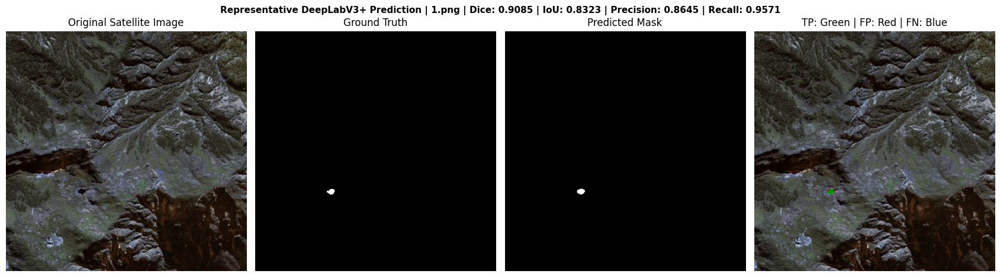

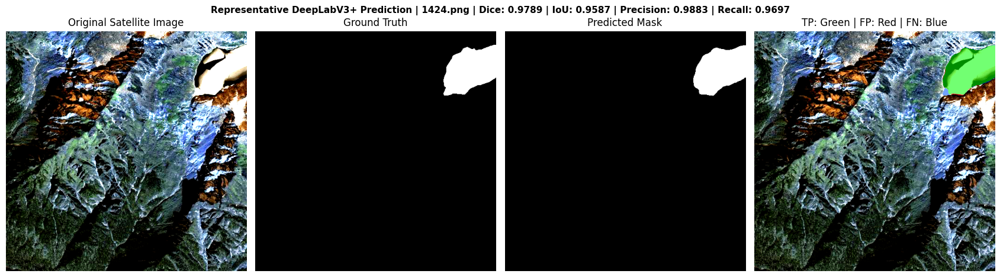

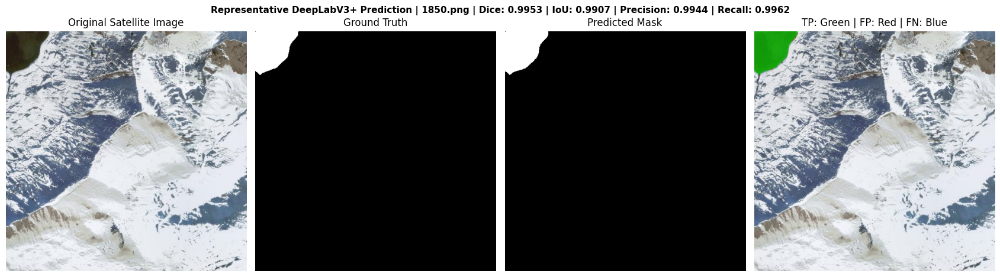

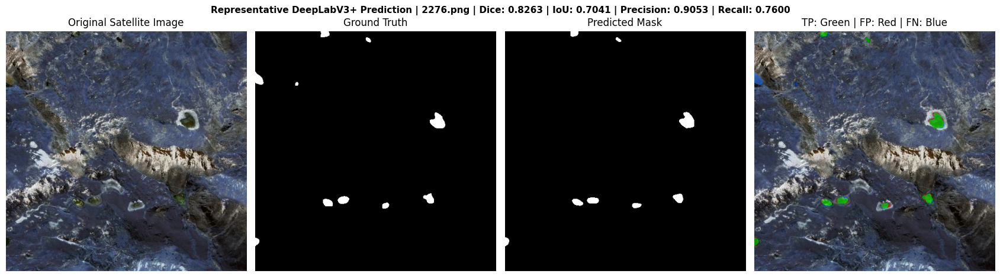

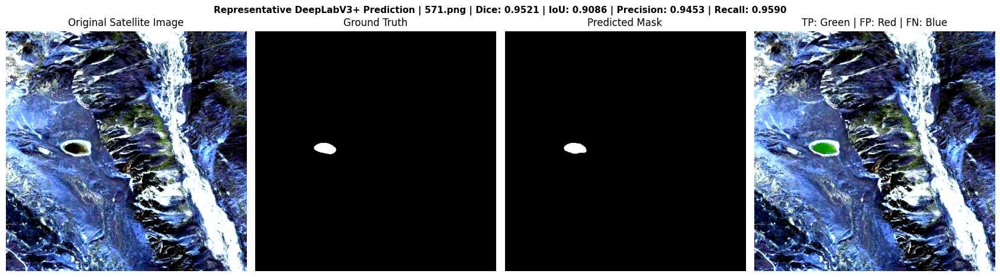

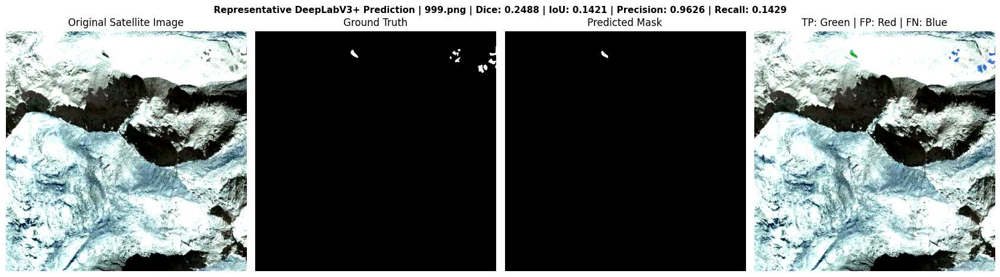


BEST DEEPLABV3+ PREDICTIONS


,index,image,dice,iou,precision,recall,gt_pixels,pred_pixels
0,1180,2060.png,0.999929,0.999859,1.000000,0.999859,262144,262107
1,19,1015.png,0.998887,0.997776,0.998872,0.998901,238490,238497
2,773,1695.png,0.997370,0.994754,0.999109,0.995637,115985,115582
3,1191,2070.png,0.997300,0.994615,0.994741,0.999873,157007,157817
4,162,1144.png,0.996760,0.993542,0.995895,0.997627,208640,209003
5,757,1680.png,0.996457,0.992939,0.999980,0.992959,254500,252713


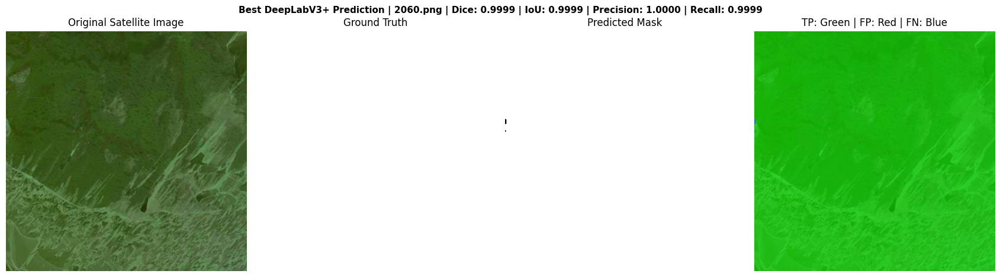

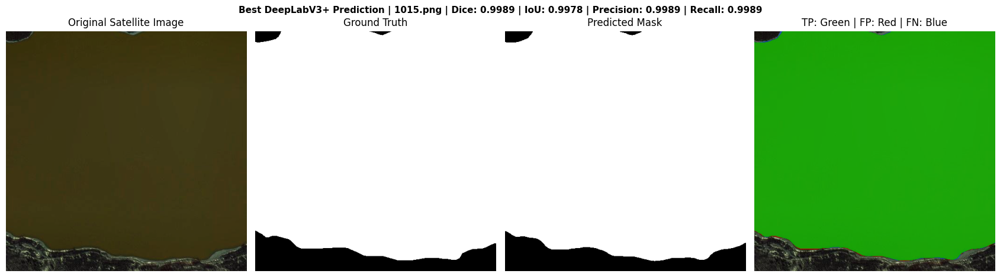

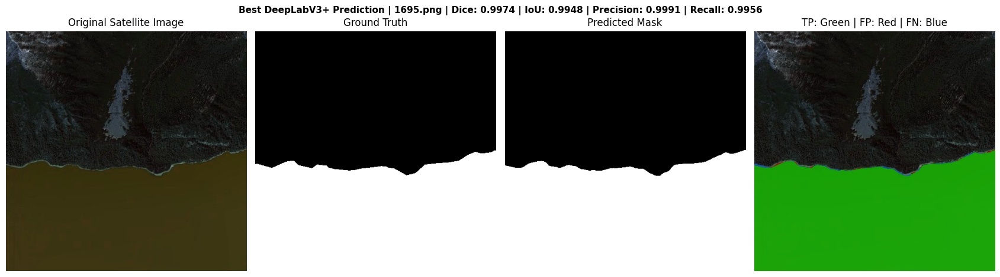

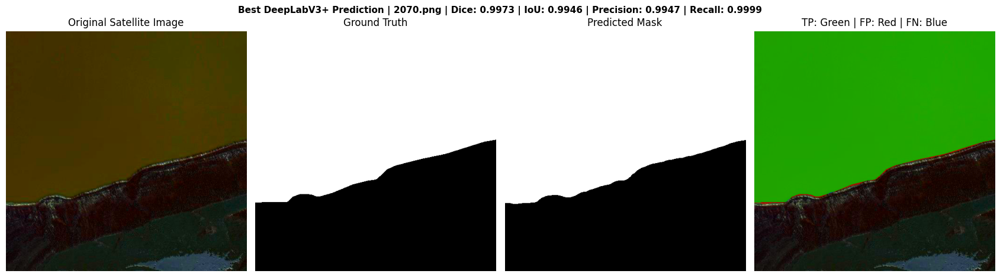

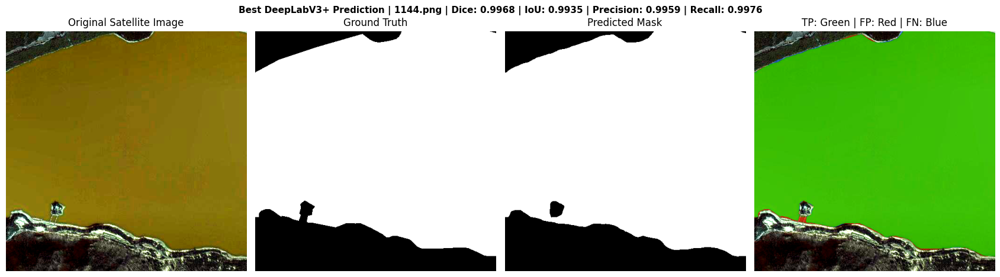

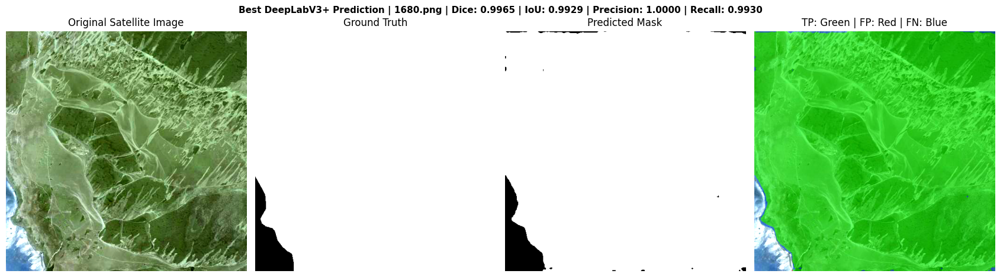


WORST DEEPLABV3+ PREDICTIONS


,index,image,dice,iou,precision,recall,tp,fp,fn,gt_pixels,pred_pixels
0,2021,688.png,0.0,0.0,0.0,0.0,0,219,44935,44935,219
1,1688,388.png,0.0,0.0,1.0,0.0,0,0,20573,20573,0
2,206,1184.png,0.0,0.0,1.0,0.0,0,0,15226,15226,0
3,903,1811.png,0.0,0.0,1.0,0.0,0,0,9980,9980,0
4,472,1423.png,0.0,0.0,1.0,0.0,0,0,3853,3853,0
5,2081,741.png,0.0,0.0,1.0,0.0,0,0,3769,3769,0
6,2325,961.png,0.0,0.0,1.0,0.0,0,0,3009,3009,0
7,264,1236.png,0.0,0.0,1.0,0.0,0,0,2919,2919,0
8,2051,714.png,0.0,0.0,1.0,0.0,0,0,2772,2772,0
9,1121,2007.png,0.0,0.0,1.0,0.0,0,0,2762,2762,0


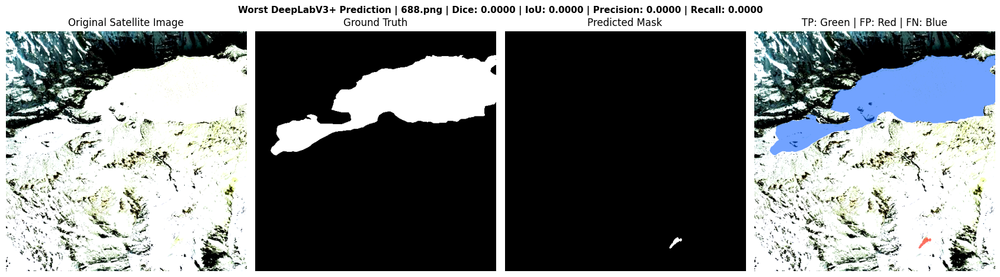

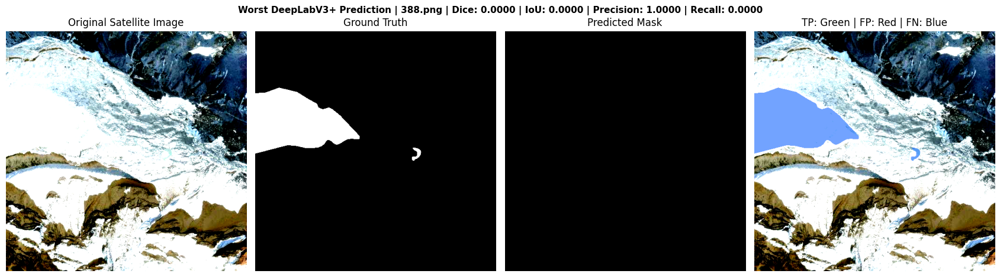

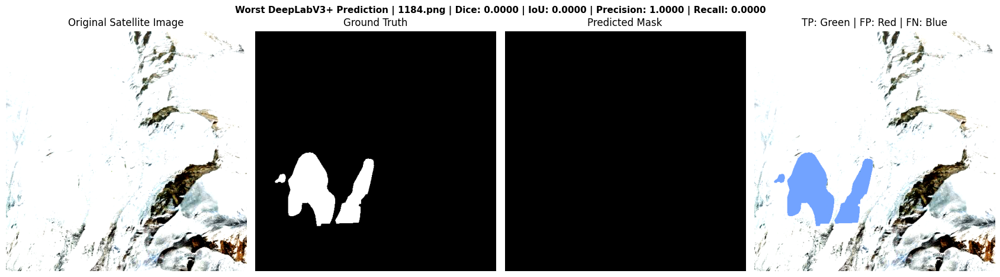

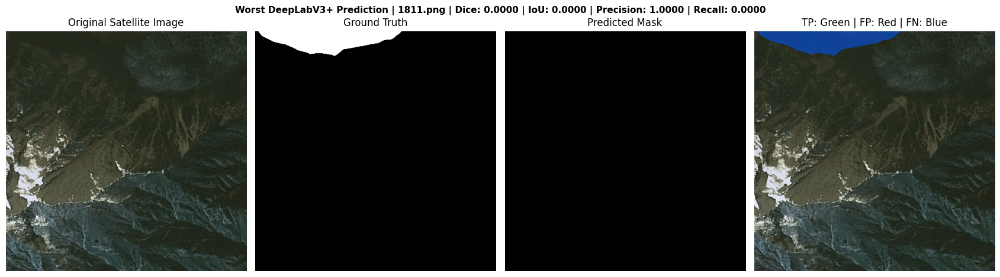

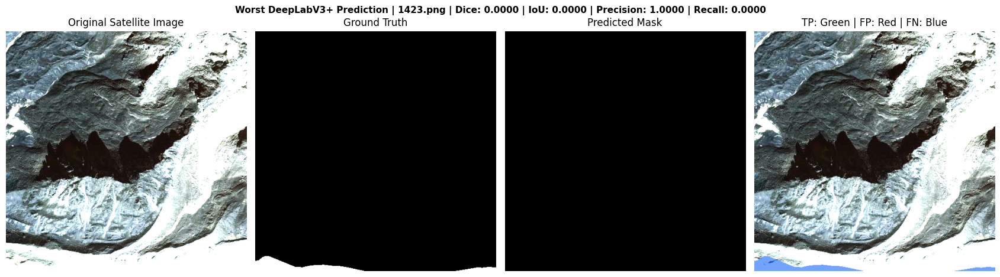

...

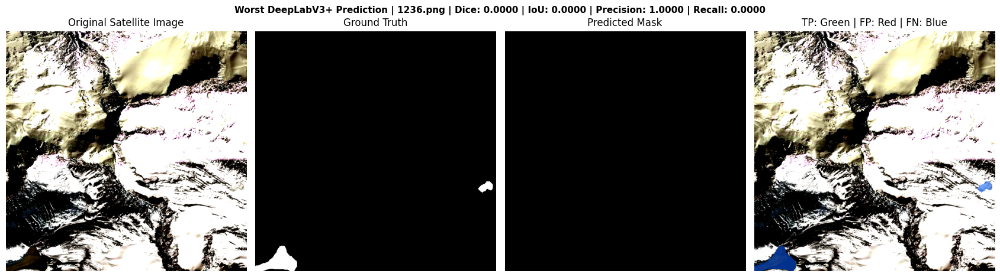

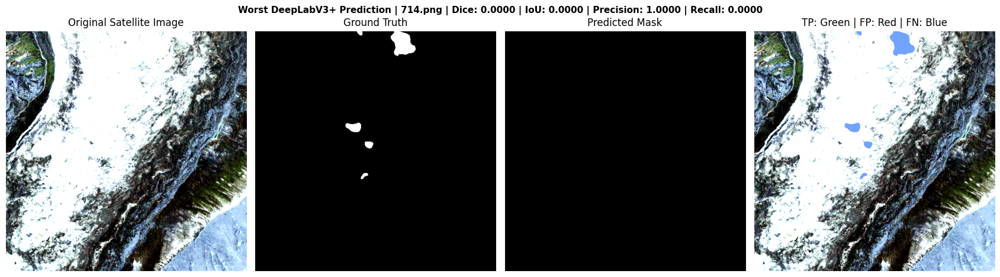

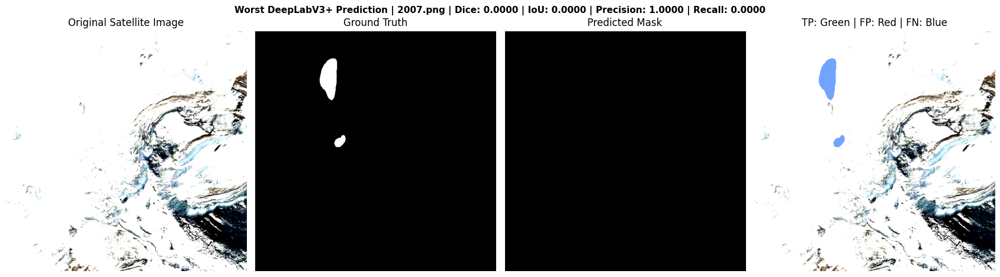

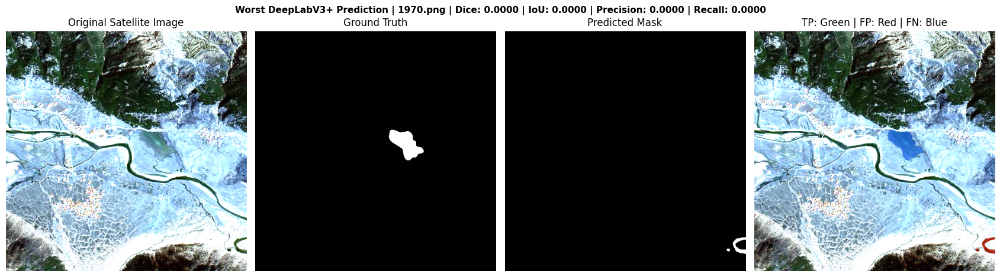

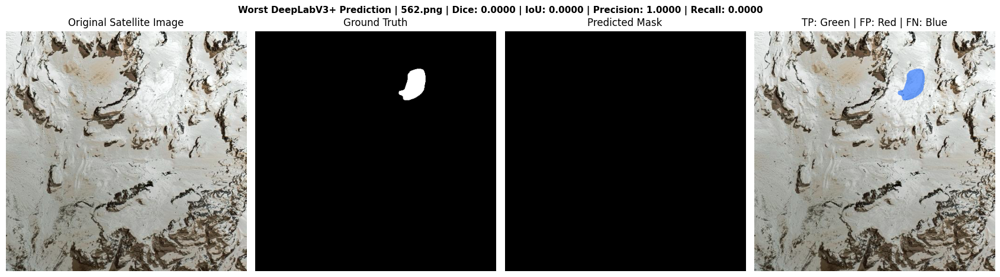


DEEPLABV3+ VISUAL ANALYSIS COMPLETED

Checkpoint epoch : 26
Validation images: 2,367
Representative   : 6
Best examples    : 6
Worst examples   : 12

Saved outputs:
  /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/deeplabv3plus_visualizations/deeplabv3plus_all_validation_metrics.csv
  /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/deeplabv3plus_visualizations/deeplabv3plus_best_cases.csv
  /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/deeplabv3plus_visualizations/deeplabv3plus_worst_cases.csv

Figures folder: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/resnet34_fcn_colab/deeplabv3plus_visualizations

No training was performed.
Model weights were not modified.


In [24]:

# ================================================================
# 14. DEEPLABV3+ REPRESENTATIVE & WORST-CASE VALIDATION ANALYSIS
#
# Inference only. No training or weight modification.
# Evaluates all validation images and saves per-image metrics,
# representative predictions, best cases and worst cases.
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from torch.utils.data import DataLoader
from IPython.display import display
from tqdm.auto import tqdm


# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

DEEPLAB_VIS_DIR = EXP_DIR / "deeplabv3plus_visualizations"
DEEPLAB_VIS_DIR.mkdir(parents=True, exist_ok=True)

DEEPLAB_VIS_THRESHOLD = 0.5

DEEPLAB_N_REPRESENTATIVE = 6
DEEPLAB_N_BEST = 6
DEEPLAB_N_WORST = 12

DEEPLAB_VIS_BATCH_SIZE = 8

# Exclude extremely tiny ground-truth regions from
# the primary worst-case analysis.
MIN_GT_PIXELS_FOR_WORST = 100

DEEPLAB_MEAN = np.asarray(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

DEEPLAB_STD = np.asarray(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)

DEEPLAB_CHECKPOINT_PATH = Path(
    "/content/drive/MyDrive/"
    "Glacial_Lake_Segmentation/"
    "training/deeplabv3plus_fast/"
    "checkpoints/best_amp_model.pth"
)

assert DEEPLAB_CHECKPOINT_PATH.exists(), (
    f"Checkpoint not found: {DEEPLAB_CHECKPOINT_PATH}"
)

assert len(val_ds) == 2367, (
    f"Unexpected validation size: {len(val_ds)}"
)

assert len(val_names) == len(val_ds), (
    "Validation filenames and dataset indices do not match."
)

assert len(set(map(str, val_names))) == len(val_names), (
    "Duplicate validation filenames detected."
)


# ------------------------------------------------
# 2. CLEAN PREVIOUS GENERATED VISUALIZATION FILES
# ------------------------------------------------

# Only removes files generated by this particular section.
# Checkpoints and other experiment outputs are untouched.

generated_patterns = [
    "representative_*.png",
    "best_dice_*.png",
    "worst_dice_*.png",
    "deeplabv3plus_*.csv"
]

for pattern in generated_patterns:
    for old_file in DEEPLAB_VIS_DIR.glob(pattern):
        old_file.unlink()

print("Previous DeepLabV3+ visualization outputs cleaned.")


# ------------------------------------------------
# 3. LOAD BEST DEEPLABV3+ CHECKPOINT
# ------------------------------------------------

print("\n" + "=" * 70)
print("DEEPLABV3+ VALIDATION VISUALIZATION")
print("=" * 70)

deeplab_vis_cfg = {
    "model": {
        "name": "deeplabv3plus",
        "pretrained": False,
        "num_classes": 1,
        "freeze_encoder": False,
        "aspp_dilations": [6, 12, 18],
    }
}

deeplab_vis_model = build_model(
    deeplab_vis_cfg
).to(device)

deeplab_vis_checkpoint = torch.load(
    DEEPLAB_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

deeplab_vis_model.load_state_dict(
    deeplab_vis_checkpoint["model_state_dict"]
)

deeplab_vis_model.eval()

deeplab_vis_epoch = deeplab_vis_checkpoint.get(
    "epoch", "unknown"
)

print(f"Checkpoint: {DEEPLAB_CHECKPOINT_PATH.name}")
print(f"Best epoch: {deeplab_vis_epoch}")
print(f"Validation images: {len(val_ds):,}")
print(f"Threshold: {DEEPLAB_VIS_THRESHOLD}")


# ------------------------------------------------
# 4. HELPER FUNCTIONS
# ------------------------------------------------

def dl_unpack_batch(batch):

    if not isinstance(batch, (tuple, list)) or len(batch) < 2:
        raise ValueError("Expected image and mask.")

    return batch[0], batch[1]

def dl_image_name(index):
    return Path(str(val_names[index])).name


def dl_mask_to_numpy(mask_tensor):

    arr = mask_tensor.detach().float().cpu().numpy()
    arr = np.squeeze(arr)

    if arr.ndim != 2:
        raise ValueError(
            f"Expected a 2D mask, received shape {arr.shape}"
        )

    return (arr > 0.5).astype(np.uint8)


def dl_display_rgb(image_tensor):

    image = (
        image_tensor.detach()
        .float()
        .cpu()
        .permute(1, 2, 0)
        .numpy()
    )

    image = image * DEEPLAB_STD + DEEPLAB_MEAN

    return np.clip(image, 0, 1)


def dl_compute_scores(gt, pred):

    gt = np.asarray(gt, dtype=bool)
    pred = np.asarray(pred, dtype=bool)

    tp = int(np.logical_and(gt, pred).sum())
    fp = int(np.logical_and(~gt, pred).sum())
    fn = int(np.logical_and(gt, ~pred).sum())

    gt_pixels = int(gt.sum())
    pred_pixels = int(pred.sum())

    dice_den = 2 * tp + fp + fn
    iou_den = tp + fp + fn

    dice = (
        2 * tp / dice_den
        if dice_den > 0 else 1.0
    )

    iou = (
        tp / iou_den
        if iou_den > 0 else 1.0
    )

    precision = (
        tp / (tp + fp)
        if tp + fp > 0 else 1.0
    )

    recall = (
        tp / (tp + fn)
        if tp + fn > 0 else 1.0
    )

    return {
        "dice": float(dice),
        "iou": float(iou),
        "precision": float(precision),
        "recall": float(recall),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "gt_pixels": gt_pixels,
        "pred_pixels": pred_pixels
    }


def dl_predict(images):

    x = images.to(
        device,
        non_blocking=True
    )

    if device.type == "cuda":

        x = x.to(
            memory_format=torch.channels_last
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = deeplab_vis_model(x)

    else:
        logits = deeplab_vis_model(x)

    return torch.sigmoid(
        logits.float()
    ).detach().cpu()


def dl_error_overlay(image_rgb, gt, pred):

    overlay = image_rgb.copy()

    tp = (gt == 1) & (pred == 1)
    fp = (gt == 0) & (pred == 1)
    fn = (gt == 1) & (pred == 0)

    tint = np.zeros_like(overlay)

    # Green: Correctly predicted lake pixels
    tint[tp] = (0, 1, 0)

    # Red: False positives
    tint[fp] = (1, 0, 0)

    # Blue: Missed lake pixels
    tint[fn] = (0, 0.35, 1)

    active = tp | fp | fn

    overlay[active] = (
        0.45 * overlay[active] +
        0.55 * tint[active]
    )

    return overlay


# ------------------------------------------------
# 5. EVALUATE ALL VALIDATION IMAGES
# ------------------------------------------------

print("\nEvaluating all validation images...")

deeplab_vis_loader = DataLoader(
    val_ds,
    batch_size=DEEPLAB_VIS_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

deeplab_rows = []

offset = 0

with torch.inference_mode():

    for images, masks in tqdm(
        deeplab_vis_loader,
        desc="DeepLabV3+ validation"
    ):

        probabilities = dl_predict(images)

        for j in range(images.shape[0]):

            gt = dl_mask_to_numpy(masks[j])

            pred = (
                probabilities[j, 0].numpy()
                >= DEEPLAB_VIS_THRESHOLD
            ).astype(np.uint8)

            scores = dl_compute_scores(gt, pred)

            deeplab_rows.append({
                "index": offset,
                "image": dl_image_name(offset),
                "mask": dl_image_name(offset),
                **scores
            })

            offset += 1


if offset != len(val_ds):

    raise RuntimeError(
        f"Evaluated {offset} images, "
        f"expected {len(val_ds)}."
    )


deeplab_per_image_df = pd.DataFrame(deeplab_rows)

# Save complete per-image metrics.

deeplab_all_csv = (
    DEEPLAB_VIS_DIR /
    "deeplabv3plus_all_validation_metrics.csv"
)

deeplab_per_image_df.to_csv(
    deeplab_all_csv,
    index=False
)

print("\nEvaluation completed successfully.")
print(f"Images evaluated: {len(deeplab_per_image_df):,}")


# ------------------------------------------------
# 6. PERFORMANCE SUMMARY
# ------------------------------------------------

print("\n" + "=" * 70)
print("DEEPLABV3+ PER-IMAGE PERFORMANCE SUMMARY")
print("=" * 70)

print(
    f"Mean per-image Dice : "
    f"{deeplab_per_image_df['dice'].mean():.4f}"
)

print(
    f"Mean per-image IoU  : "
    f"{deeplab_per_image_df['iou'].mean():.4f}"
)

print(
    f"Best Dice           : "
    f"{deeplab_per_image_df['dice'].max():.4f}"
)

print(
    f"Worst Dice          : "
    f"{deeplab_per_image_df['dice'].min():.4f}"
)

print(
    f"Zero-Dice cases     : "
    f"{(deeplab_per_image_df['dice'] == 0).sum()}"
)

print(
    f"Empty predictions   : "
    f"{(deeplab_per_image_df['pred_pixels'] == 0).sum()}"
)

print(
    f"Tiny GT masks (<{MIN_GT_PIXELS_FOR_WORST} pixels): "
    f"{(deeplab_per_image_df['gt_pixels'] < MIN_GT_PIXELS_FOR_WORST).sum()}"
)


# ------------------------------------------------
# 7. FOUR-PANEL VISUALIZATION FUNCTION
# ------------------------------------------------

def dl_plot_case(index, title_prefix, save_name):

    image_tensor, mask_tensor = dl_unpack_batch(
        val_ds[index]
        )

    with torch.inference_mode():

        probabilities = dl_predict(
            image_tensor.unsqueeze(0)
        )[0, 0].numpy()

    gt = dl_mask_to_numpy(mask_tensor)

    pred = (
        probabilities >= DEEPLAB_VIS_THRESHOLD
    ).astype(np.uint8)

    scores = dl_compute_scores(gt, pred)

    rgb = dl_display_rgb(image_tensor)

    overlay = dl_error_overlay(
        rgb,
        gt,
        pred
    )

    filename = dl_image_name(index)

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(17, 4.8)
    )

    axes[0].imshow(rgb)
    axes[0].set_title("Original Satellite Image")

    axes[1].imshow(
        gt,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Ground Truth")

    axes[2].imshow(
        pred,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[2].set_title("Predicted Mask")

    axes[3].imshow(overlay)
    axes[3].set_title(
        "TP: Green | FP: Red | FN: Blue"
    )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"{title_prefix} | {filename} | "
        f"Dice: {scores['dice']:.4f} | "
        f"IoU: {scores['iou']:.4f} | "
        f"Precision: {scores['precision']:.4f} | "
        f"Recall: {scores['recall']:.4f}",
        fontsize=11,
        fontweight="bold"
    )

    plt.tight_layout()

    save_path = DEEPLAB_VIS_DIR / save_name

    plt.savefig(
        save_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------
# 8. REPRESENTATIVE PREDICTIONS
# ------------------------------------------------

print("\n" + "=" * 70)
print("REPRESENTATIVE DEEPLABV3+ PREDICTIONS")
print("=" * 70)

representative_indices = sorted(
    set(
        np.linspace(
            0,
            len(val_ds) - 1,
            min(
                DEEPLAB_N_REPRESENTATIVE,
                len(val_ds)
            ),
            dtype=int
        ).tolist()
    )
)

for idx in representative_indices:

    dl_plot_case(
        idx,
        "Representative DeepLabV3+ Prediction",
        f"representative_{idx:04d}.png"
    )


# ------------------------------------------------
# 9. BEST-PERFORMING PREDICTIONS
# ------------------------------------------------

print("\n" + "=" * 70)
print("BEST DEEPLABV3+ PREDICTIONS")
print("=" * 70)

# Positive ground-truth regions only.
# This avoids filling the best list with empty-mask matches.

positive_gt_df = deeplab_per_image_df[
    deeplab_per_image_df["gt_pixels"] > 0
]

best_df = positive_gt_df.sort_values(
    ["dice", "iou", "gt_pixels", "index"],
    ascending=[False, False, False, True]
).head(DEEPLAB_N_BEST)

best_csv = (
    DEEPLAB_VIS_DIR /
    "deeplabv3plus_best_cases.csv"
)

best_df.to_csv(
    best_csv,
    index=False
)

display(
    best_df[
        [
            "index",
            "image",
            "dice",
            "iou",
            "precision",
            "recall",
            "gt_pixels",
            "pred_pixels"
        ]
    ].reset_index(drop=True)
)

for _, row in best_df.iterrows():

    idx = int(row["index"])

    dl_plot_case(
        idx,
        "Best DeepLabV3+ Prediction",
        f"best_dice_{idx:04d}.png"
    )


# ------------------------------------------------
# 10. WORST-PERFORMING PREDICTIONS
# ------------------------------------------------

print("\n" + "=" * 70)
print("WORST DEEPLABV3+ PREDICTIONS")
print("=" * 70)

# First select images containing meaningful lake regions.
# Ties are resolved by selecting the larger GT lake region.

meaningful_worst_pool = deeplab_per_image_df[
    deeplab_per_image_df["gt_pixels"]
    >= MIN_GT_PIXELS_FOR_WORST
]

# Fallback if the filter leaves too few images.

if len(meaningful_worst_pool) < DEEPLAB_N_WORST:

    print(
        "Warning: Fewer than the requested number of "
        "meaningful cases. Including smaller GT masks."
    )

    meaningful_worst_pool = deeplab_per_image_df[
        deeplab_per_image_df["gt_pixels"] > 0
    ]

worst_df = meaningful_worst_pool.sort_values(
    ["dice", "iou", "gt_pixels", "index"],
    ascending=[True, True, False, True]
).head(DEEPLAB_N_WORST)

worst_csv = (
    DEEPLAB_VIS_DIR /
    "deeplabv3plus_worst_cases.csv"
)

worst_df.to_csv(
    worst_csv,
    index=False
)

display(
    worst_df[
        [
            "index",
            "image",
            "dice",
            "iou",
            "precision",
            "recall",
            "tp",
            "fp",
            "fn",
            "gt_pixels",
            "pred_pixels"
        ]
    ].reset_index(drop=True)
)

for _, row in worst_df.iterrows():

    idx = int(row["index"])

    dl_plot_case(
        idx,
        "Worst DeepLabV3+ Prediction",
        f"worst_dice_{idx:04d}.png"
    )


# ------------------------------------------------
# 11. FINAL OUTPUT
# ------------------------------------------------

print("\n" + "=" * 70)
print("DEEPLABV3+ VISUAL ANALYSIS COMPLETED")
print("=" * 70)

print(f"\nCheckpoint epoch : {deeplab_vis_epoch}")
print(f"Validation images: {len(deeplab_per_image_df):,}")
print(f"Representative   : {len(representative_indices)}")
print(f"Best examples    : {len(best_df)}")
print(f"Worst examples   : {len(worst_df)}")

print("\nSaved outputs:")

for path in [
    deeplab_all_csv,
    best_csv,
    worst_csv
]:
    print(f"  {path}")

print(f"\nFigures folder: {DEEPLAB_VIS_DIR}")

print("\nNo training was performed.")
print("Model weights were not modified.")


In [25]:
# 4.1 Attn-ResUNet34 Architecture Definition
from typing import Dict, Optional, Tuple, Union
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import ResNet34_Weights, resnet34


class AttentionGate(nn.Module):
    """Additive Attention Gate (Oktay et al., 2018)."""
    def __init__(self, in_channels_x: int, in_channels_g: int, inter_channels: Optional[int] = None) -> None:
        super().__init__()
        if inter_channels is None:
            inter_channels = max(16, in_channels_x // 2)

        self.wx = nn.Sequential(
            nn.Conv2d(in_channels_x, inter_channels, kernel_size=1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(inter_channels),
        )
        self.wg = nn.Sequential(
            nn.Conv2d(in_channels_g, inter_channels, kernel_size=1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(inter_channels),
        )
        self.psi = nn.Conv2d(inter_channels, 1, kernel_size=1, stride=1, padding=0, bias=True)
        self.relu = nn.ReLU(inplace=False)
        self.sigmoid = nn.Sigmoid()
        self._init_weights()

    def _init_weights(self) -> None:
        for seq in (self.wx, self.wg):
            conv, bn = seq[0], seq[1]
            if isinstance(conv, nn.Conv2d):
                nn.init.kaiming_normal_(conv.weight, mode="fan_out", nonlinearity="relu")
            if isinstance(bn, nn.BatchNorm2d):
                nn.init.ones_(bn.weight)
                nn.init.zeros_(bn.bias)
        # Open-gate initialization: bias=+2.0 => sigmoid(2.0) ~ 0.8808
        nn.init.normal_(self.psi.weight, mean=0.0, std=0.01)
        if self.psi.bias is not None:
            nn.init.constant_(self.psi.bias, 2.0)

    def forward(self, x: torch.Tensor, g: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        if g.shape[2:] != x.shape[2:]:
            g = F.interpolate(g, size=x.shape[2:], mode="bilinear", align_corners=False)
        theta_x = self.wx(x)
        phi_g = self.wg(g)
        f = self.relu(theta_x + phi_g)
        psi = self.psi(f)
        alpha = self.sigmoid(psi)
        gated_x = x * alpha
        return gated_x, alpha


class DoubleConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, mid_channels: Optional[int] = None) -> None:
        super().__init__()
        if mid_channels is None:
            mid_channels = out_channels
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=False),
            nn.Conv2d(mid_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=False),
        )
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


class DecoderBlock(nn.Module):
    def __init__(self, in_channels: int, skip_channels: int, out_channels: int, use_attention: bool = True) -> None:
        super().__init__()
        self.use_attention = use_attention
        self.up_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=False),
        )
        if self.use_attention and skip_channels > 0:
            self.gate = AttentionGate(skip_channels, out_channels, max(16, skip_channels // 2))
        else:
            self.gate = None
        concat_channels = out_channels + skip_channels if skip_channels > 0 else out_channels
        self.conv = DoubleConv(concat_channels, out_channels)

    def forward(self, x: torch.Tensor, skip: Optional[torch.Tensor] = None) -> Tuple[torch.Tensor, Optional[torch.Tensor]]:
        target_size = skip.shape[2:] if skip is not None else (x.shape[2] * 2, x.shape[3] * 2)
        x_up = F.interpolate(x, size=target_size, mode="bilinear", align_corners=False)
        g = self.up_conv(x_up)
        alpha = None
        if skip is not None:
            if self.gate is not None:
                gated_skip, alpha = self.gate(skip, g)
            else:
                gated_skip = skip
            out = torch.cat([g, gated_skip], dim=1)
        else:
            out = g
        out = self.conv(out)
        return out, alpha


class AttnResUNet34(nn.Module):
    def __init__(self, pretrained: bool = True, num_classes: int = 1, freeze_encoder: bool = False, use_attention: bool = True) -> None:
        super().__init__()
        self.num_classes = num_classes
        self.use_attention = use_attention

        # Encoder: Pretrained ResNet-34
        weights = ResNet34_Weights.DEFAULT if pretrained else None
        backbone = resnet34(weights=weights)
        self.conv1 = backbone.conv1
        self.bn1 = backbone.bn1
        self.relu = backbone.relu
        self.maxpool = backbone.maxpool
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        # Decoder: 5 Stages with Attention Gates
        self.dec1 = DecoderBlock(512, 256, 256, use_attention=use_attention)
        self.dec2 = DecoderBlock(256, 128, 128, use_attention=use_attention)
        self.dec3 = DecoderBlock(128,  64,  64, use_attention=use_attention)
        self.dec4 = DecoderBlock( 64,  64,  32, use_attention=use_attention)
        self.dec5 = DecoderBlock( 32,   0,  16, use_attention=False)
        self.classifier = nn.Conv2d(16, num_classes, kernel_size=1)
        nn.init.kaiming_normal_(self.classifier.weight, mode="fan_out", nonlinearity="relu")
        if self.classifier.bias is not None:
            nn.init.zeros_(self.classifier.bias)

        if freeze_encoder:
            for p in self.encoder_parameters():
                p.requires_grad = False

    def encoder_parameters(self):
        for p in self.conv1.parameters(): yield p
        for p in self.bn1.parameters(): yield p
        for p in self.layer1.parameters(): yield p
        for p in self.layer2.parameters(): yield p
        for p in self.layer3.parameters(): yield p
        for p in self.layer4.parameters(): yield p

    def decoder_parameters(self):
        for m in (self.dec1, self.dec2, self.dec3, self.dec4, self.dec5, self.classifier):
            for p in m.parameters(): yield p

    def forward(self, x: torch.Tensor, return_attention_maps: bool = False):
        e0 = self.relu(self.bn1(self.conv1(x)))  # (B, 64, 256, 256)
        e1 = self.maxpool(e0)                    # (B, 64, 128, 128)
        e1 = self.layer1(e1)                     # (B, 64, 128, 128)
        e2 = self.layer2(e1)                     # (B, 128, 64, 64)
        e3 = self.layer3(e2)                     # (B, 256, 32, 32)
        e4 = self.layer4(e3)                     # (B, 512, 16, 16)

        d1, a4 = self.dec1(e4, skip=e3)
        d2, a3 = self.dec2(d1, skip=e2)
        d3, a2 = self.dec3(d2, skip=e1)
        d4, a1 = self.dec4(d3, skip=e0)
        d5, _  = self.dec5(d4, skip=None)
        logits = self.classifier(d5)

        if return_attention_maps:
            return logits, {"ag4": a4, "ag3": a3, "ag2": a2, "ag1": a1}
        return logits

    def predict_mask(self, x: torch.Tensor, threshold: float = 0.5) -> torch.Tensor:
        self.eval()
        with torch.no_grad():
            logits = self.forward(x)
            probs = torch.sigmoid(logits)
            return (probs >= threshold).float()

    def get_parameter_summary(self) -> Dict[str, int]:
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        encoder = sum(p.numel() for p in self.encoder_parameters())
        decoder = sum(p.numel() for p in self.decoder_parameters())
        return {
            "total_parameters": total,
            "trainable_parameters": trainable,
            "encoder_parameters": encoder,
            "decoder_parameters": decoder,
        }

# Verify model creation and parameter counts
model_check = AttnResUNet34(pretrained=False, num_classes=1)
summary = model_check.get_parameter_summary()
print("✓ Attn-ResUNet34 Architecture Initialized Successfully:")
print(f"  Total Parameters     : {summary['total_parameters']:,}")
print(f"  Encoder Parameters   : {summary['encoder_parameters']:,}")
print(f"  Decoder + AG Params  : {summary['decoder_parameters']:,}")
del model_check

✓ Attn-ResUNet34 Architecture Initialized Successfully:
  Total Parameters     : 25,313,269
  Encoder Parameters   : 21,284,672
  Decoder + AG Params  : 4,028,597


THREE-MODEL GLACIAL LAKE VALIDATION ANALYSIS
Validation samples : 2,367
Prediction threshold: 0.5
Device              : cuda

CHECKPOINT VERIFICATION
---------------------------------------------------------------------------
✓ ResNet34-FCN: selected_model.pth (275.83 MB)
✓ DeepLabV3+: best_amp_model.pth (462.24 MB)
✓ Attention ResUNet34: best_model.pth (96.76 MB)

Loading ResNet34-FCN...
✓ ResNet34-FCN loaded successfully
  Epoch: 29
  Parameters: 24,079,153

Loading DeepLabV3+...
✓ DeepLabV3+ loaded successfully
  Epoch: 26
  Parameters: 40,347,041

Loading Attention ResUNet34...
✓ Attention ResUNet34 loaded successfully
  Epoch: 30
  Parameters: 25,313,269

All three models loaded successfully.

RUNNING THREE-MODEL VALIDATION EVALUATION


Evaluating models:   0%|          | 0/592 [00:00<?, ?it/s]


✓ Evaluated 2,367 validation images using all three models.

GLOBAL PIXEL-LEVEL COMPARISON


,Model,Dice / F1,IoU,Precision,Recall,Pixel Accuracy
0,ResNet34-FCN,93.4105%,87.6358%,95.2569%,91.6344%,99.7043%
1,DeepLabV3+,93.9673%,88.6211%,95.6100%,92.3802%,99.7287%
2,Attention ResUNet34,91.7360%,84.7335%,93.1279%,90.3850%,99.6276%



PER-IMAGE MEAN COMPARISON


,Model,Mean Dice,Mean IoU,Zero-Dice Images
0,ResNet34-FCN,81.3355%,74.8501%,188
1,DeepLabV3+,85.5746%,79.5614%,109
2,Attention ResUNet34,79.7552%,73.0104%,188


... (3 outputs left out)

,index,image,DeepLabV3+_dice,DeepLabV3+_iou,DeepLabV3+_precision,DeepLabV3+_recall
1,1,10.png,0.0000,0.0000,0.0000,0.0000
63,63,1055.png,0.0000,0.0000,0.0000,0.0000
93,93,1082.png,0.0000,0.0000,0.0000,0.0000
102,102,1090.png,0.0000,0.0000,0.0000,0.0000
140,140,1124.png,0.0000,0.0000,0.0000,0.0000



Worst cases: Attention ResUNet34


,index,image,Attention ResUNet34_dice,Attention ResUNet34_iou,Attention ResUNet34_precision,Attention ResUNet34_recall
1,1,10.png,0.0000,0.0000,0.0000,0.0000
57,57,105.png,0.0000,0.0000,0.0000,0.0000
63,63,1055.png,0.0000,0.0000,0.0000,0.0000
67,67,1059.png,0.0000,0.0000,0.0000,0.0000
93,93,1082.png,0.0000,0.0000,0.0000,0.0000



REPRESENTATIVE VALIDATION PREDICTIONS

Image: 1.png


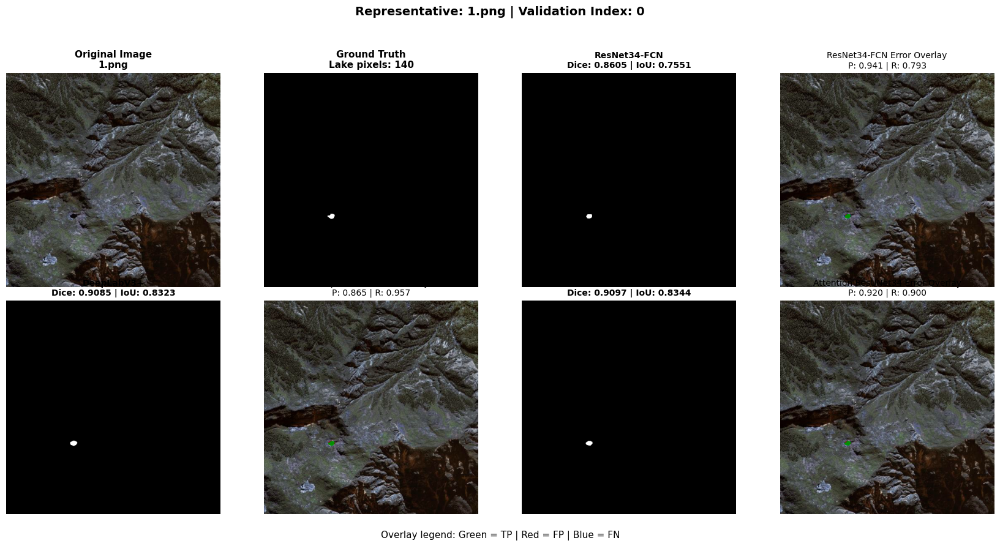


Image: 1424.png


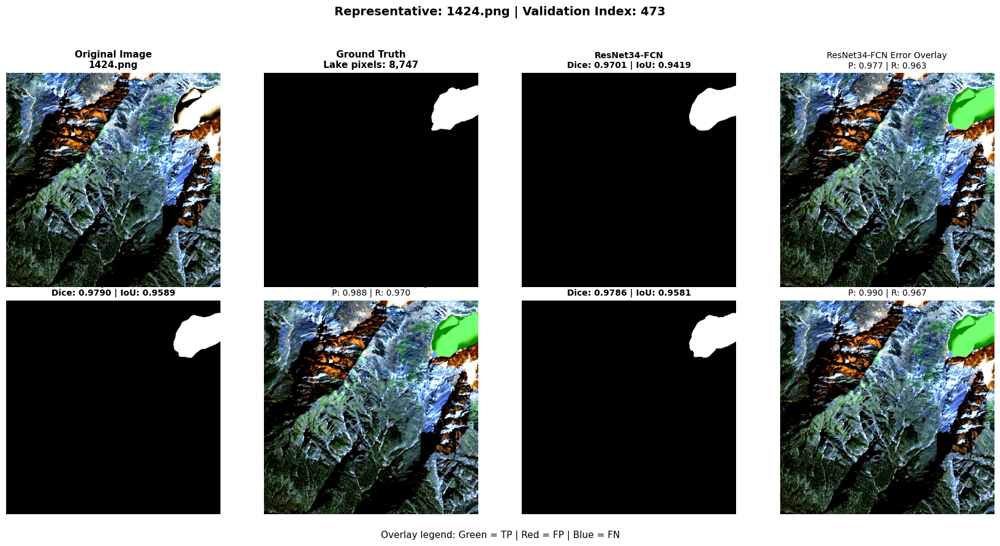


Image: 1850.png


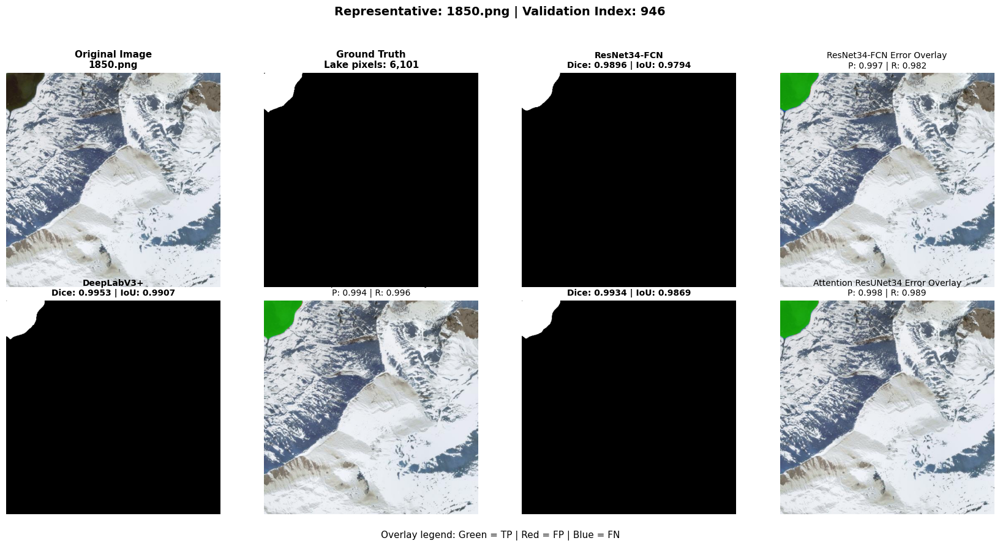


Image: 2276.png


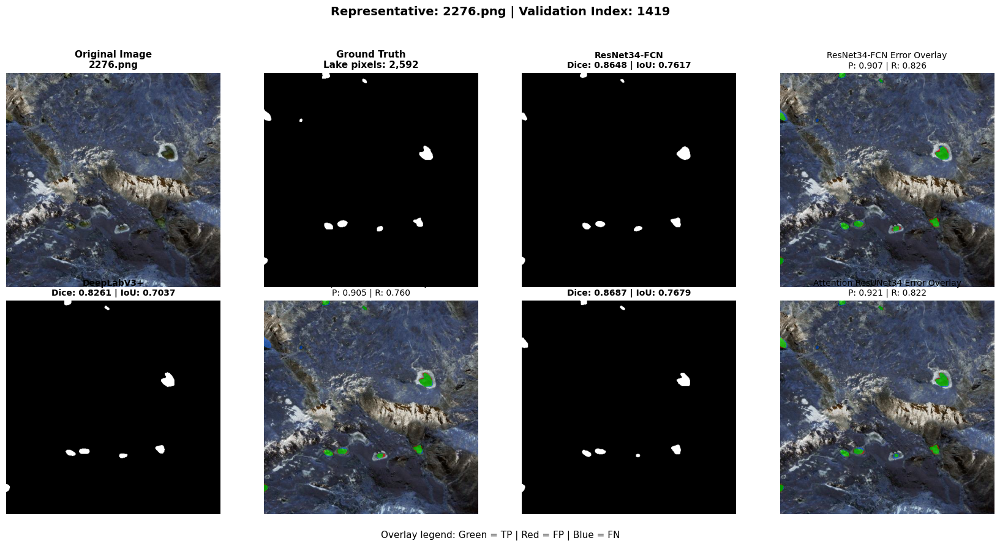


Image: 571.png


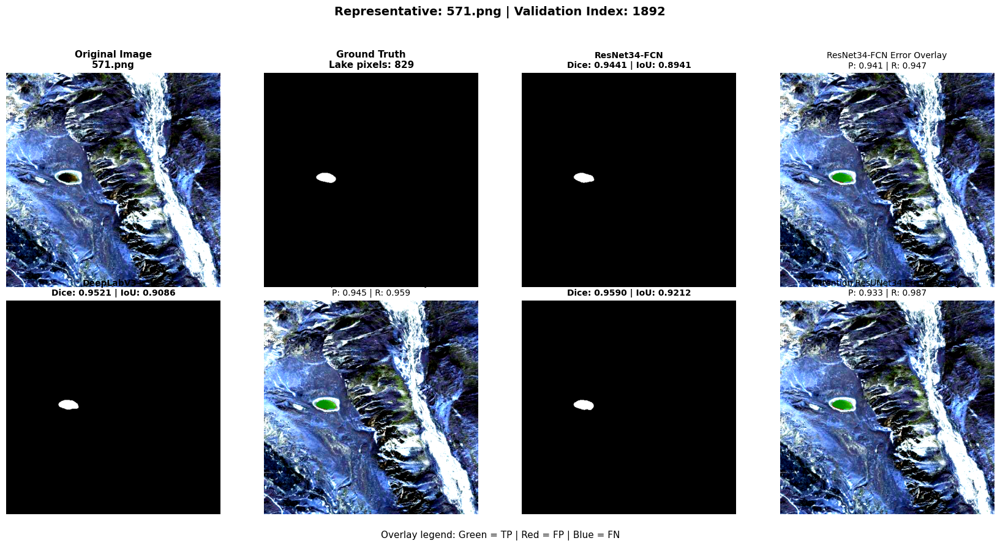


Image: 999.png


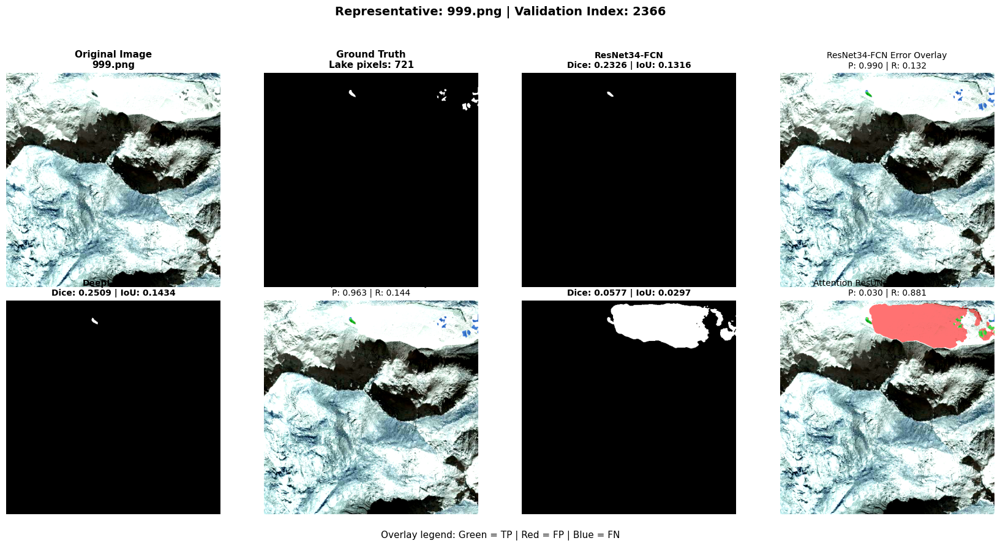


WORST-PERFORMING IMAGE VISUALIZATIONS

Image: 10.png
Per-model Dice:
  ResNet34-FCN: 0.0000
  DeepLabV3+: 0.0000
  Attention ResUNet34: 0.0000


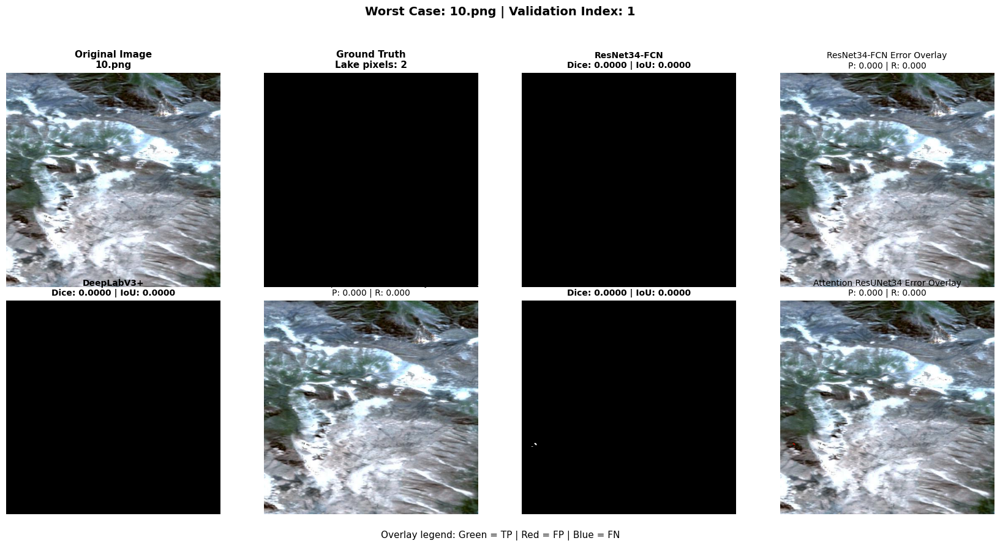


Image: 105.png
Per-model Dice:
  ResNet34-FCN: 0.8979
  DeepLabV3+: 0.9201
  Attention ResUNet34: 0.0000


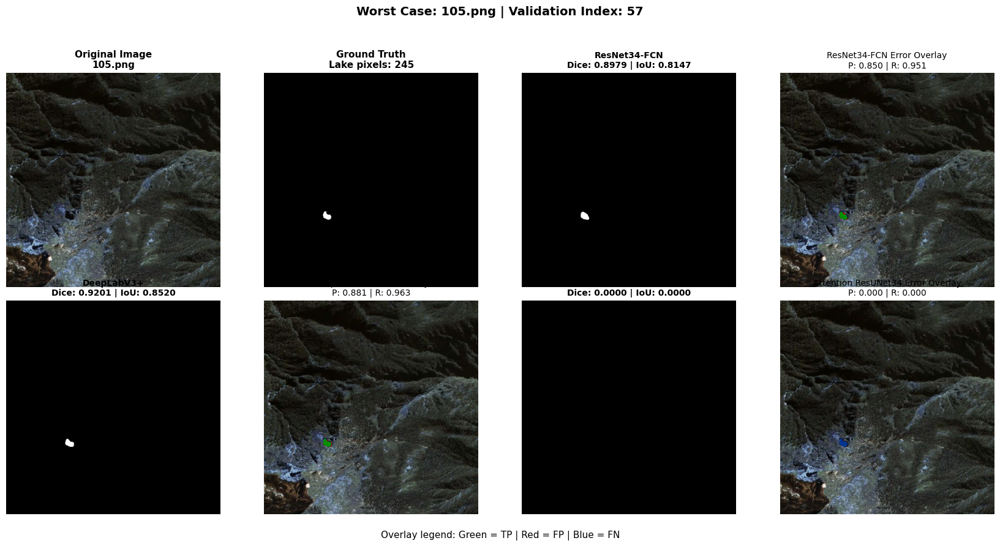


Image: 1055.png
Per-model Dice:
  ResNet34-FCN: 0.0000
  DeepLabV3+: 0.0000
  Attention ResUNet34: 0.0000


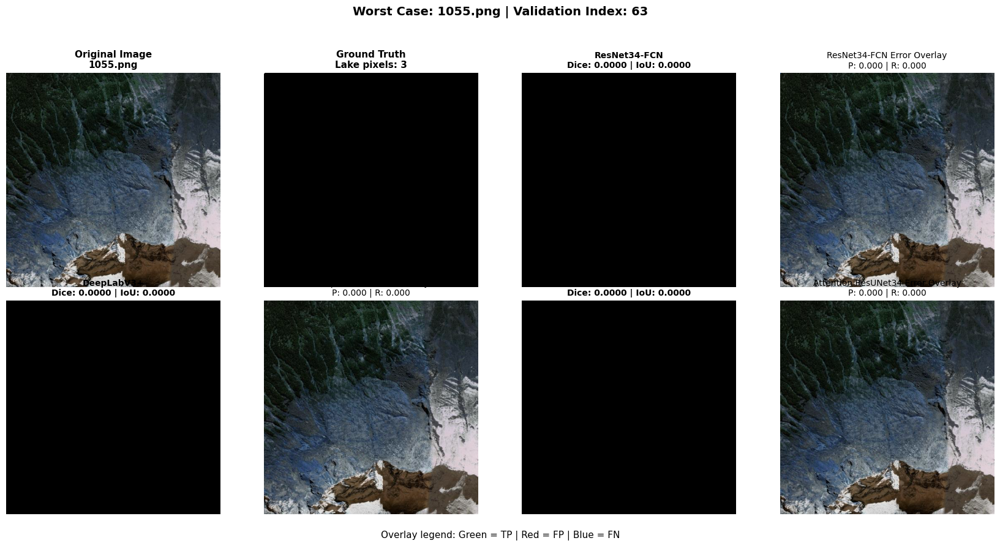


Image: 1059.png
Per-model Dice:
  ResNet34-FCN: 0.1669
  DeepLabV3+: 0.8559
  Attention ResUNet34: 0.0000


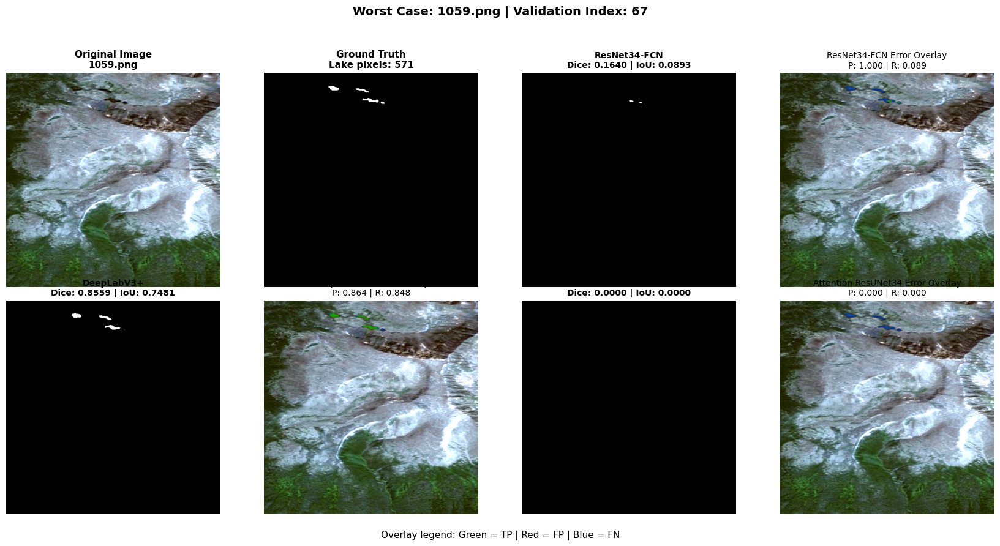


Image: 1082.png
Per-model Dice:
  ResNet34-FCN: 0.0000
  DeepLabV3+: 0.0000
  Attention ResUNet34: 0.0000


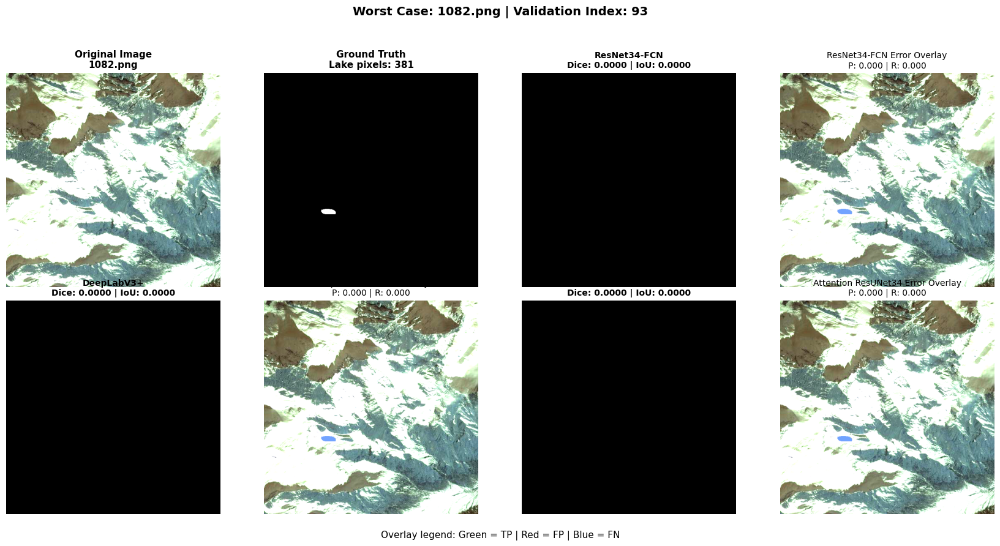


Image: 1090.png
Per-model Dice:
  ResNet34-FCN: 0.0000
  DeepLabV3+: 0.0000
  Attention ResUNet34: 0.0000


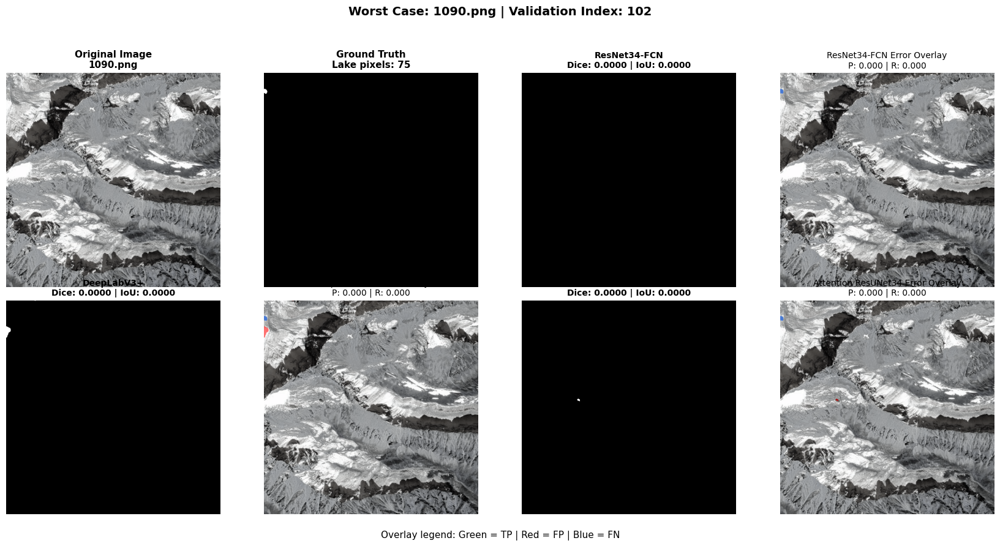


Image: 1099.png
Per-model Dice:
  ResNet34-FCN: 0.0000
  DeepLabV3+: 0.9040
  Attention ResUNet34: 0.0000


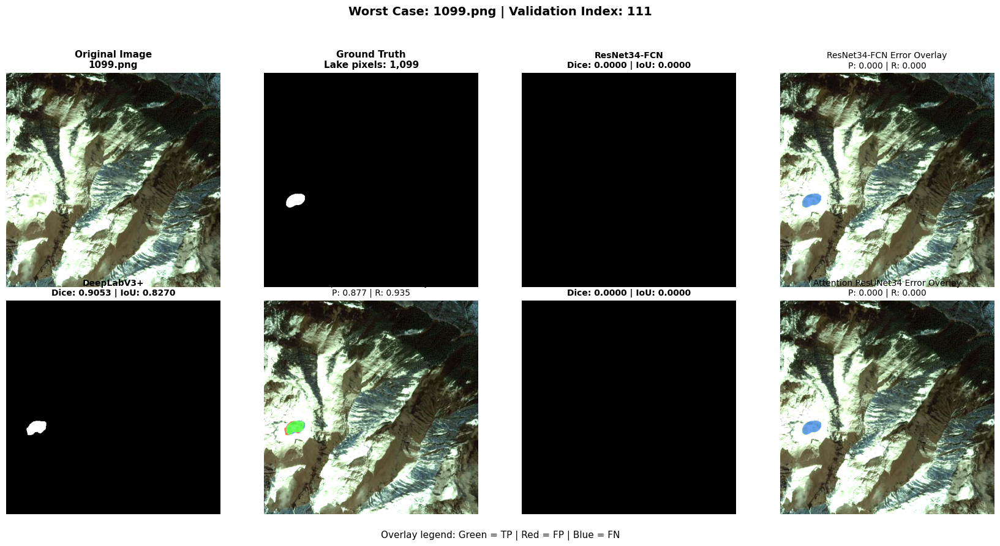


Image: 1124.png
Per-model Dice:
  ResNet34-FCN: 0.0000
  DeepLabV3+: 0.0000
  Attention ResUNet34: 0.0000


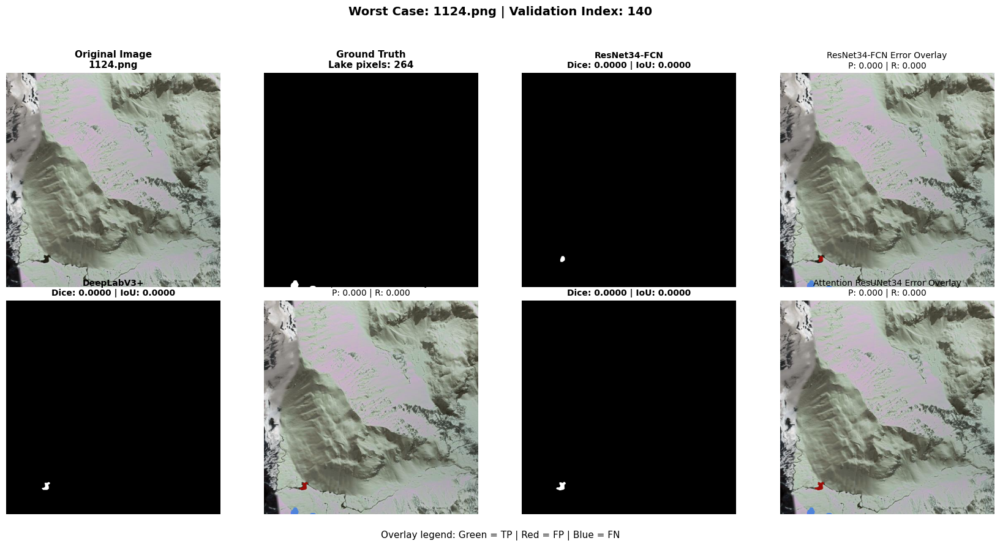


IMAGES WHERE ALL THREE MODELS STRUGGLE

10.png | Mean Dice: 0.0000


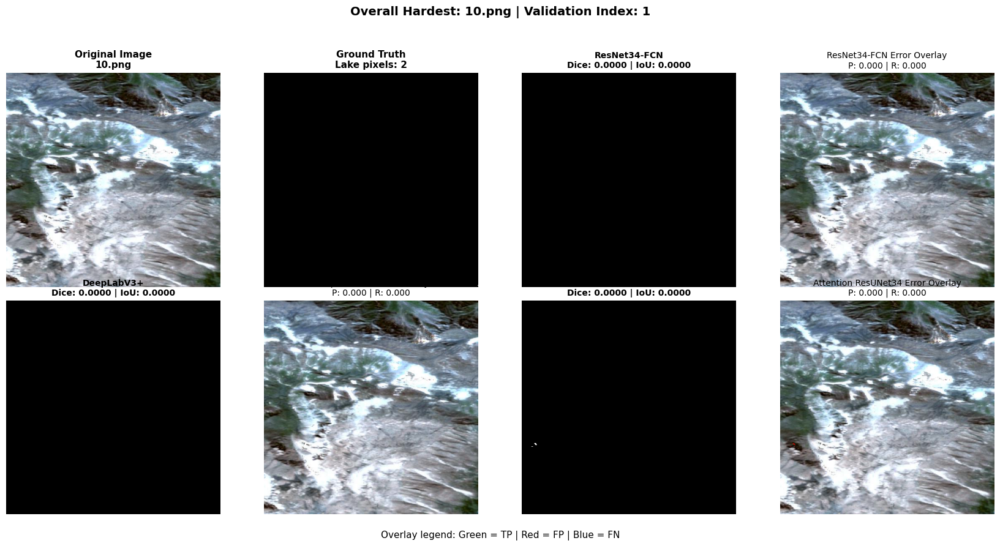


1055.png | Mean Dice: 0.0000


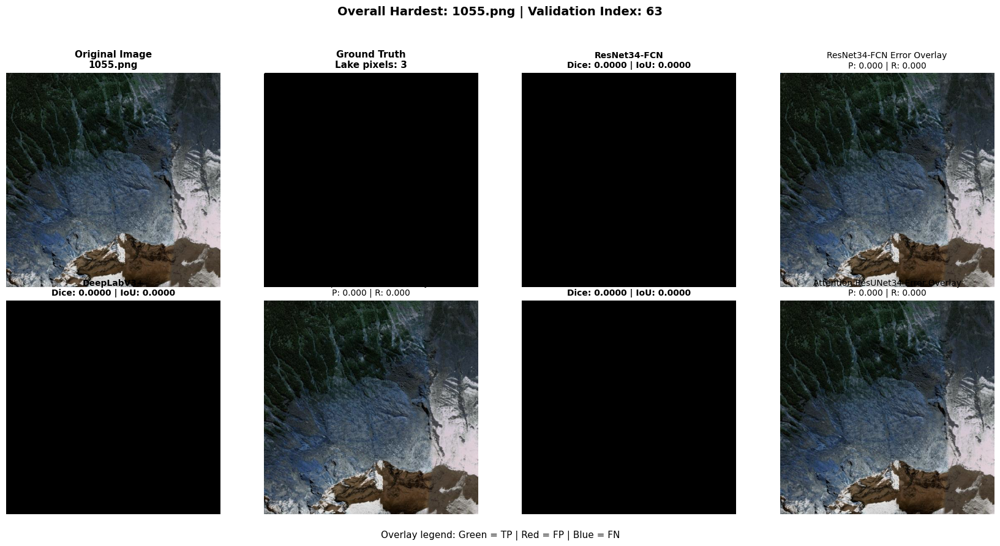


1082.png | Mean Dice: 0.0000


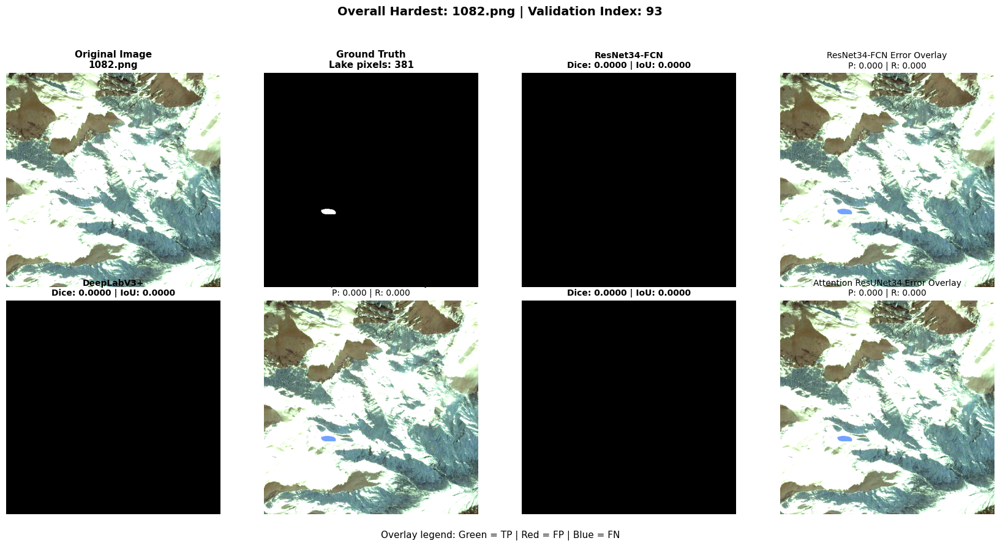


1090.png | Mean Dice: 0.0000


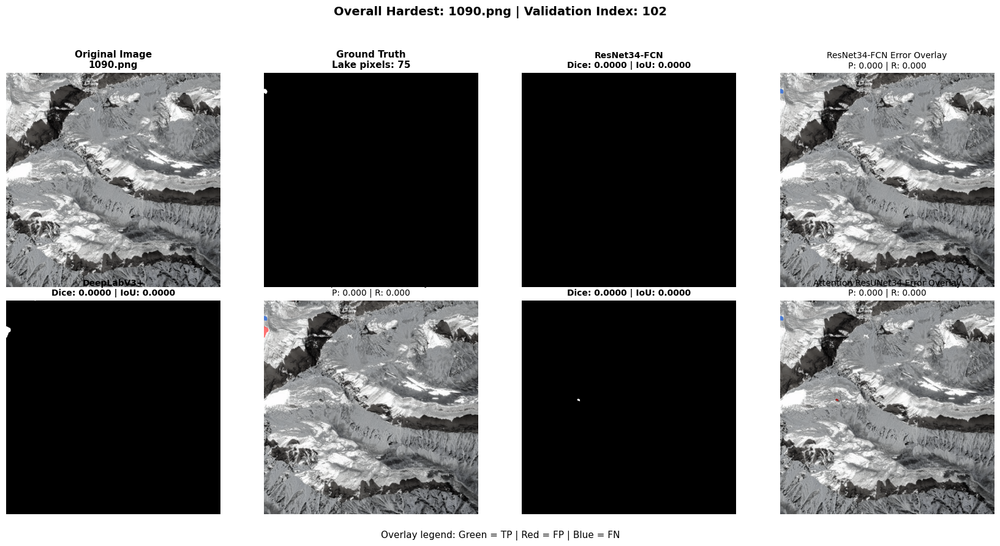


1124.png | Mean Dice: 0.0000


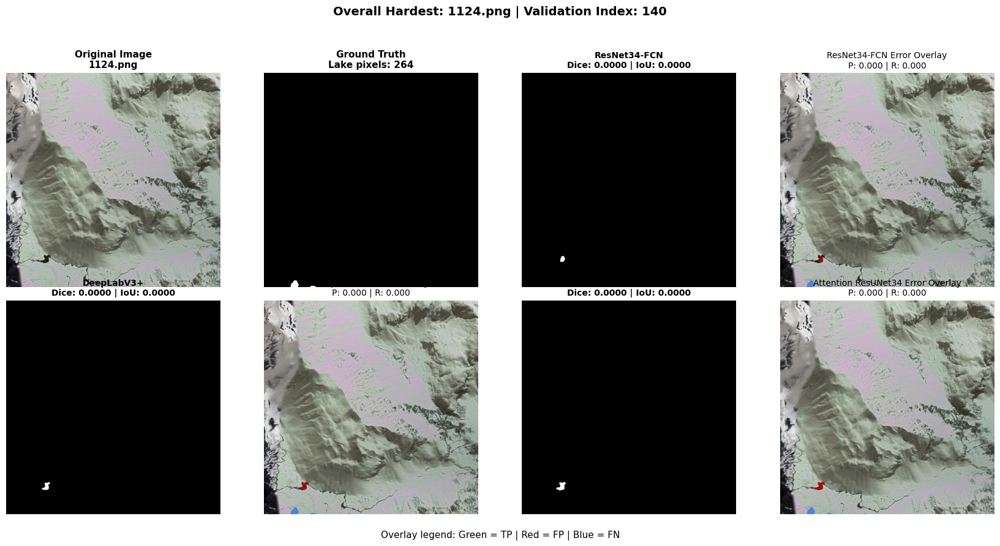


THREE-MODEL ANALYSIS COMPLETED

Validation images evaluated: 2,367

Saved files:
1. Per-image metrics:
   /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/three_model_comparison/three_model_per_image_comparison.csv

2. Global metrics:
   /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/three_model_comparison/three_model_global_metrics.csv

3. Overall hardest cases:
   /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/three_model_comparison/overall_hardest_validation_images.csv

4. Visualization folder:
   /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/three_model_comparison/visualizations

Representative figures: 6
Unique worst-case figures: 8
Overall hardest figures: 5

All visualization outputs are saved separately.
No training was performed and no checkpoint was modified.

✓ SECTION 15 FINISHED SUCCESSFULLY


In [31]:
# ================================================================
# 15. THREE-MODEL PER-IMAGE COMPARISON & VISUAL ANALYSIS
# ResNet34-FCN vs DeepLabV3+ vs Attention ResUNet34
# ================================================================

import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from torch.utils.data import DataLoader
from tqdm.auto import tqdm


# ------------------------------------------------
# 15.1 CONFIGURATION
# ------------------------------------------------

ROOT = Path(
    "/content/drive/MyDrive/Glacial_Lake_Segmentation"
)

COMPARISON_DIR = (
    ROOT / "experiments" / "three_model_comparison"
)

VIS_DIR = COMPARISON_DIR / "visualizations"

COMPARISON_DIR.mkdir(parents=True, exist_ok=True)
VIS_DIR.mkdir(parents=True, exist_ok=True)

THRESHOLD = 0.5
BATCH_SIZE = 4

N_REPRESENTATIVE = 6
N_WORST_PER_MODEL = 5
N_OVERALL_HARD = 5

MODEL_NAMES = [
    "ResNet34-FCN",
    "DeepLabV3+",
    "Attention ResUNet34"
]

assert len(val_ds) == 2367, (
    f"Expected 2367 validation images, got {len(val_ds)}"
)

assert len(val_names) == len(val_ds), (
    "Validation filename count does not match dataset length."
)

assert "AttnResUNet34" in globals(), (
    "Run the original AttnResUNet34 architecture definition "
    "cell before running Section 15."
)

if isinstance(device, str):
    device = torch.device(device)

print("=" * 75)
print("THREE-MODEL GLACIAL LAKE VALIDATION ANALYSIS")
print("=" * 75)

print(f"Validation samples : {len(val_ds):,}")
print(f"Prediction threshold: {THRESHOLD}")
print(f"Device              : {device}")


# ------------------------------------------------
# 15.2 CHECKPOINT PATHS
# ------------------------------------------------

CHECKPOINTS = {
    "ResNet34-FCN": Path(SELECTED_CHECKPOINT_PATH),

    "DeepLabV3+": ROOT / "training/deeplabv3plus_fast/checkpoints/best_amp_model.pth",

    "Attention ResUNet34": ROOT / "experiments/attn_resunet34_colab/checkpoints/best_model.pth",
}

print("\nCHECKPOINT VERIFICATION")
print("-" * 75)

for name, path in CHECKPOINTS.items():

    if not path.is_file():
        raise FileNotFoundError(
            f"{name} checkpoint not found:\n{path}"
        )

    print(
        f"✓ {name}: {path.name} "
        f"({path.stat().st_size / (1024**2):.2f} MB)"
    )


# ------------------------------------------------
# 15.3 MODEL CONFIGURATIONS
# ------------------------------------------------

MODEL_CONFIGS = {

    "ResNet34-FCN": {
        "model": {
            "name": "resnet34_fcn",
            "pretrained": False,
            "num_classes": 1,
            "freeze_encoder": False
        }
    },

    "DeepLabV3+": {
        "model": {
            "name": "deeplabv3plus",
            "pretrained": False,
            "num_classes": 1,
            "freeze_encoder": False,
            "aspp_dilations": [6, 12, 18]
        }
    }
}


# ------------------------------------------------
# 15.4 CHECKPOINT LOADING
# ------------------------------------------------

def load_model_checkpoint(name, checkpoint_path):

    print(f"\nLoading {name}...")

    if name == "Attention ResUNet34":

        model = AttnResUNet34(
            pretrained=False,
            num_classes=1,
            freeze_encoder=False,
            use_attention=True
        ).to(device)

    else:

        model = build_model(
            MODEL_CONFIGS[name]
        ).to(device)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    if (
        isinstance(checkpoint, dict)
        and "model_state_dict" in checkpoint
    ):
        state_dict = checkpoint["model_state_dict"]

    elif (
        isinstance(checkpoint, dict)
        and "state_dict" in checkpoint
    ):
        state_dict = checkpoint["state_dict"]

    else:
        state_dict = checkpoint

    model.load_state_dict(
        state_dict,
        strict=True
    )

    model.eval()

    epoch = (
        checkpoint.get(
            "best_epoch",
            checkpoint.get("epoch", "unknown")
        )
        if isinstance(checkpoint, dict)
        else "unknown"
    )

    params = sum(
        p.numel()
        for p in model.parameters()
    )

    print(f"✓ {name} loaded successfully")
    print(f"  Epoch: {epoch}")
    print(f"  Parameters: {params:,}")

    return model, checkpoint


models = {}
model_checkpoints = {}

for name in MODEL_NAMES:

    model, checkpoint = load_model_checkpoint(
        name,
        CHECKPOINTS[name]
    )

    models[name] = model
    model_checkpoints[name] = checkpoint


print("\nAll three models loaded successfully.")


# ------------------------------------------------
# 15.5 METRIC FUNCTIONS
# ------------------------------------------------

def calculate_metrics(gt, pred):

    gt = np.asarray(gt, dtype=bool)
    pred = np.asarray(pred, dtype=bool)

    tp = int(np.logical_and(gt, pred).sum())
    fp = int(np.logical_and(~gt, pred).sum())
    fn = int(np.logical_and(gt, ~pred).sum())
    tn = int(np.logical_and(~gt, ~pred).sum())

    dice_den = 2 * tp + fp + fn
    iou_den = tp + fp + fn

    dice = (
        2 * tp / dice_den
        if dice_den > 0 else 1.0
    )

    iou = (
        tp / iou_den
        if iou_den > 0 else 1.0
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else (1.0 if gt.sum() == 0 else 0.0)
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0 else 1.0
    )

    return {
        "dice": float(dice),
        "iou": float(iou),
        "precision": float(precision),
        "recall": float(recall),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
        "gt_pixels": int(gt.sum()),
        "pred_pixels": int(pred.sum())
    }


# ------------------------------------------------
# 15.6 PREDICTION FUNCTION
# ------------------------------------------------

def get_logits(model, images):

    output = model(images)

    if isinstance(output, (tuple, list)):
        output = output[0]

    if isinstance(output, dict):
        if "out" in output:
            output = output["out"]
        else:
            raise ValueError(
                "Model returned a dictionary without an 'out' key."
            )

    return output


def predict_batch(model, images):

    images = images.to(
        device,
        non_blocking=True
    )

    if device.type == "cuda":

        images = images.to(
            memory_format=torch.channels_last
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = get_logits(model, images)

    else:

        logits = get_logits(model, images)

    probabilities = torch.sigmoid(
        logits.float()
    )

    return probabilities.detach().cpu()


# ------------------------------------------------
# 15.7 IMAGE AND MASK HELPERS
# ------------------------------------------------

# ImageNet normalization used by the original models.

VIS_MEAN = np.asarray(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

VIS_STD = np.asarray(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)


def get_image_name(index):

    return Path(
        str(val_names[index])
    ).name


def denormalize_image(image_tensor):

    image = (
        image_tensor.detach()
        .float()
        .cpu()
        .permute(1, 2, 0)
        .numpy()
    )

    image = image * VIS_STD + VIS_MEAN

    return np.clip(image, 0, 1)


def get_overlay(image_rgb, gt, pred):

    overlay = image_rgb.copy()

    tp = (gt == 1) & (pred == 1)
    fp = (gt == 0) & (pred == 1)
    fn = (gt == 1) & (pred == 0)

    tint = np.zeros_like(overlay)

    # TP = Green
    tint[tp] = [0, 1, 0]

    # FP = Red
    tint[fp] = [1, 0, 0]

    # FN = Blue
    tint[fn] = [0, 0.35, 1]

    active = tp | fp | fn

    overlay[active] = (
        0.45 * overlay[active]
        + 0.55 * tint[active]
    )

    return overlay


# ------------------------------------------------
# 15.8 EVALUATE ALL THREE MODELS
# ------------------------------------------------

print("\n" + "=" * 75)
print("RUNNING THREE-MODEL VALIDATION EVALUATION")
print("=" * 75)

comparison_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

all_model_rows = []

global_counts = {
    name: {
        "tp": 0,
        "fp": 0,
        "fn": 0,
        "tn": 0
    }
    for name in MODEL_NAMES
}

with torch.inference_mode():

    for images, masks in tqdm(
        comparison_loader,
        desc="Evaluating models"
    ):

        gt_batch = [
            (
                masks[j]
                .squeeze()
                .cpu()
                .numpy() > 0.5
            )
            for j in range(images.shape[0])
        ]

        batch_predictions = {}

        # Same images, same order, all three models.
        for name in MODEL_NAMES:

            probabilities = predict_batch(
                models[name],
                images
            )

            batch_predictions[name] = (
                probabilities[:, 0].numpy()
                >= THRESHOLD
            ).astype(np.uint8)

        for j in range(images.shape[0]):

            index = len(all_model_rows)

            gt = gt_batch[j]

            row = {
                "index": index,
                "image": get_image_name(index),
                "gt_pixels": int(gt.sum())
            }

            for name in MODEL_NAMES:

                pred = batch_predictions[name][j]

                scores = calculate_metrics(
                    gt,
                    pred
                )

                for metric, value in scores.items():

                    if metric != "gt_pixels":
                        row[f"{name}_{metric}"] = value

                for metric in ["tp", "fp", "fn", "tn"]:

                    global_counts[name][metric] += (
                        scores[metric]
                    )

            all_model_rows.append(row)


assert len(all_model_rows) == len(val_ds), (
    f"Evaluation count mismatch: "
    f"{len(all_model_rows)} vs {len(val_ds)}"
)

print(
    f"\n✓ Evaluated {len(all_model_rows):,} validation images "
    f"using all three models."
)


# ------------------------------------------------
# 15.9 SAVE PER-IMAGE COMPARISON
# ------------------------------------------------

three_model_df = pd.DataFrame(
    all_model_rows
)

dice_columns = [
    f"{name}_dice"
    for name in MODEL_NAMES
]

iou_columns = [
    f"{name}_iou"
    for name in MODEL_NAMES
]

three_model_df["mean_dice"] = (
    three_model_df[dice_columns].mean(axis=1)
)

three_model_df["mean_iou"] = (
    three_model_df[iou_columns].mean(axis=1)
)

three_model_df["dice_std"] = (
    three_model_df[dice_columns].std(axis=1)
)

PER_IMAGE_CSV = (
    COMPARISON_DIR /
    "three_model_per_image_comparison.csv"
)

three_model_df.to_csv(
    PER_IMAGE_CSV,
    index=False
)


# ------------------------------------------------
# 15.10 GLOBAL PIXEL-LEVEL METRICS
# ------------------------------------------------

global_rows = []

for name, cm in global_counts.items():

    tp = cm["tp"]
    fp = cm["fp"]
    fn = cm["fn"]
    tn = cm["tn"]

    dice = (
        2 * tp / (2 * tp + fp + fn)
        if (2 * tp + fp + fn) else 1.0
    )

    iou = (
        tp / (tp + fp + fn)
        if (tp + fp + fn) else 1.0
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) else 1.0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) else 1.0
    )

    accuracy = (
        (tp + tn) / (tp + tn + fp + fn)
        if (tp + tn + fp + fn) else 1.0
    )

    global_rows.append({
        "Model": name,
        "Dice / F1": dice,
        "IoU": iou,
        "Precision": precision,
        "Recall": recall,
        "Pixel Accuracy": accuracy,
        "TP": tp,
        "FP": fp,
        "FN": fn
    })


global_comparison_df = pd.DataFrame(
    global_rows
)

GLOBAL_CSV = (
    COMPARISON_DIR /
    "three_model_global_metrics.csv"
)

global_comparison_df.to_csv(
    GLOBAL_CSV,
    index=False
)

print("\n" + "=" * 75)
print("GLOBAL PIXEL-LEVEL COMPARISON")
print("=" * 75)

display(
    global_comparison_df[
        [
            "Model",
            "Dice / F1",
            "IoU",
            "Precision",
            "Recall",
            "Pixel Accuracy"
        ]
    ].style.format({
        "Dice / F1": "{:.4%}",
        "IoU": "{:.4%}",
        "Precision": "{:.4%}",
        "Recall": "{:.4%}",
        "Pixel Accuracy": "{:.4%}"
    })
)


# ------------------------------------------------
# 15.11 PER-IMAGE MEAN COMPARISON
# ------------------------------------------------

mean_rows = []

for name in MODEL_NAMES:

    mean_rows.append({
        "Model": name,

        "Mean Dice": three_model_df[
            f"{name}_dice"
        ].mean(),

        "Mean IoU": three_model_df[
            f"{name}_iou"
        ].mean(),

        "Zero-Dice Images": int(
            (three_model_df[f"{name}_dice"] == 0).sum()
        )
    })


mean_comparison_df = pd.DataFrame(
    mean_rows
)

print("\nPER-IMAGE MEAN COMPARISON")

display(
    mean_comparison_df.style.format({
        "Mean Dice": "{:.4%}",
        "Mean IoU": "{:.4%}"
    })
)


# ------------------------------------------------
# 15.12 SELECT REPRESENTATIVE AND WORST CASES
# ------------------------------------------------

# Representative images: evenly spaced in validation order.

representative_indices = sorted(
    set(
        np.linspace(
            0,
            len(val_ds) - 1,
            min(N_REPRESENTATIVE, len(val_ds)),
            dtype=int
        ).tolist()
    )
)


# Worst images for each model, independently.

worst_indices_by_model = {}

for name in MODEL_NAMES:

    sorted_df = three_model_df.sort_values(
        by=[f"{name}_dice", f"{name}_iou", "index"],
        ascending=[True, True, True]
    )

    worst_df = sorted_df.head(
        N_WORST_PER_MODEL
    )

    worst_indices_by_model[name] = (
        worst_df["index"].astype(int).tolist()
    )

    output_csv = (
        COMPARISON_DIR /
        f"worst_{name.replace(' ', '_').replace('+', 'plus')}_cases.csv"
    )

    worst_df.to_csv(
        output_csv,
        index=False
    )

    print(f"\nWorst cases: {name}")

    display(
        worst_df[
            [
                "index",
                "image",
                f"{name}_dice",
                f"{name}_iou",
                f"{name}_precision",
                f"{name}_recall"
            ]
        ].style.format({
            f"{name}_dice": "{:.4f}",
            f"{name}_iou": "{:.4f}",
            f"{name}_precision": "{:.4f}",
            f"{name}_recall": "{:.4f}"
        })
    )


# Hardest images across all three models.
# Sorted by average Dice, lowest first.

overall_hard_df = three_model_df.sort_values(
    ["mean_dice", "mean_iou", "index"],
    ascending=[True, True, True]
).head(N_OVERALL_HARD)

OVERALL_HARD_CSV = (
    COMPARISON_DIR /
    "overall_hardest_validation_images.csv"
)

overall_hard_df.to_csv(
    OVERALL_HARD_CSV,
    index=False
)



# ------------------------------------------------
# 15.13 COMBINED VISUALIZATION FUNCTION (FIXED)
# ------------------------------------------------

def predict_single_image(model, image_tensor):
    """
    Predict a single validation image.

    Input:
        image_tensor: [C, H, W] or [1, C, H, W]

    Output:
        Binary prediction mask: [H, W]
    """

    model.eval()

    # Add batch dimension if the image is 3D.
    if image_tensor.ndim == 3:
        image_tensor = image_tensor.unsqueeze(0)

    if image_tensor.ndim != 4:
        raise ValueError(
            f"Expected a 4D image tensor, got shape {image_tensor.shape}"
        )

    image_tensor = image_tensor.to(device)

    with torch.inference_mode():

        # Use existing helper to handle model outputs consistently.
        logits = get_logits(model, image_tensor)

        probabilities = torch.sigmoid(logits.float())

        # Convert safely to NumPy.
        probabilities = (
            probabilities[0, 0]
            .detach()
            .cpu()
            .numpy()
        )

        prediction = (
            probabilities >= THRESHOLD
        ).astype(np.uint8)

    return prediction


def plot_three_model_case(index, category):

    sample = val_ds[index]

    image_tensor = sample[0]
    mask_tensor = sample[1]

    # Original image.
    image_rgb = denormalize_image(image_tensor)

    # Ground truth mask.
    gt = (
        mask_tensor.squeeze()
        .detach()
        .cpu()
        .numpy() > 0.5
    ).astype(np.uint8)

    predictions = {}
    scores_by_model = {}

    # Generate predictions from all three models.
    for name in MODEL_NAMES:

        pred = predict_single_image(
            models[name],
            image_tensor
        )

        predictions[name] = pred

        scores_by_model[name] = calculate_metrics(
            gt,
            pred
        )

    # Create comparison figure.
    fig, axes = plt.subplots(
        2,
        4,
        figsize=(17, 9)
    )

    axes = axes.flatten()

    image_name = get_image_name(index)

    # Original image.
    axes[0].imshow(image_rgb)
    axes[0].set_title(
        f"Original Image\n{image_name}",
        fontsize=11,
        fontweight="bold"
    )

    # Ground truth.
    axes[1].imshow(
        gt,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1].set_title(
        f"Ground Truth\nLake pixels: {int(gt.sum()):,}",
        fontsize=11,
        fontweight="bold"
    )

    # Predictions and error overlays.
    for model_position, name in enumerate(MODEL_NAMES):

        pred = predictions[name]
        scores = scores_by_model[name]

        pred_axis = axes[2 + model_position * 2]
        overlay_axis = axes[3 + model_position * 2]

        # Binary prediction.
        pred_axis.imshow(
            pred,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        pred_axis.set_title(
            f"{name}\n"
            f"Dice: {scores['dice']:.4f} | "
            f"IoU: {scores['iou']:.4f}",
            fontsize=10,
            fontweight="bold"
        )

        # TP / FP / FN overlay.
        overlay_axis.imshow(
            get_overlay(image_rgb, gt, pred)
        )

        overlay_axis.set_title(
            f"{name} Error Overlay\n"
            f"P: {scores['precision']:.3f} | "
            f"R: {scores['recall']:.3f}",
            fontsize=10
        )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"{category}: {image_name} | "
        f"Validation Index: {index}",
        fontsize=14,
        fontweight="bold"
    )

    fig.text(
        0.5,
        0.015,
        "Overlay legend: Green = TP | Red = FP | Blue = FN",
        ha="center",
        fontsize=11
    )

    plt.tight_layout(
        rect=[0, 0.04, 1, 0.94]
    )

    safe_category = (
        category.lower()
        .replace(" ", "_")
        .replace("/", "_")
    )

    output_path = (
        VIS_DIR /
        f"{safe_category}_{index:04d}.png"
    )

    plt.savefig(
        output_path,
        dpi=140,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    return scores_by_model

# ------------------------------------------------
# 15.14 REPRESENTATIVE VALIDATION VISUALIZATIONS
# ------------------------------------------------

print("\n" + "=" * 75)
print("REPRESENTATIVE VALIDATION PREDICTIONS")
print("=" * 75)

for index in representative_indices:

    print(f"\nImage: {get_image_name(index)}")

    plot_three_model_case(
        index,
        "Representative"
    )


# ------------------------------------------------
# 15.15 WORST-PERFORMING IMAGE VISUALIZATIONS
# ------------------------------------------------

print("\n" + "=" * 75)
print("WORST-PERFORMING IMAGE VISUALIZATIONS")
print("=" * 75)

# Union of the worst images from all three models.
# This avoids repeatedly generating the same figure.

all_worst_indices = sorted(
    set(
        idx
        for indices in worst_indices_by_model.values()
        for idx in indices
    )
)

for index in all_worst_indices:

    print(f"\nImage: {get_image_name(index)}")

    print("Per-model Dice:")

    for name in MODEL_NAMES:

        value = three_model_df.loc[
            index,
            f"{name}_dice"
        ]

        print(f"  {name}: {value:.4f}")

    plot_three_model_case(
        index,
        "Worst Case"
    )


# ------------------------------------------------
# 15.16 OVERALL HARDEST VALIDATION IMAGES
# ------------------------------------------------

print("\n" + "=" * 75)
print("IMAGES WHERE ALL THREE MODELS STRUGGLE")
print("=" * 75)

for index in overall_hard_df["index"].astype(int):

    print(
        f"\n{get_image_name(index)} | "
        f"Mean Dice: "
        f"{three_model_df.loc[index, 'mean_dice']:.4f}"
    )

    plot_three_model_case(
        index,
        "Overall Hardest"
    )


# ------------------------------------------------
# 15.17 FINAL OUTPUTS
# ------------------------------------------------

print("\n" + "=" * 75)
print("THREE-MODEL ANALYSIS COMPLETED")
print("=" * 75)

print(f"\nValidation images evaluated: {len(three_model_df):,}")

print("\nSaved files:")

print(f"1. Per-image metrics:\n   {PER_IMAGE_CSV}")

print(f"\n2. Global metrics:\n   {GLOBAL_CSV}")

print(f"\n3. Overall hardest cases:\n   {OVERALL_HARD_CSV}")

print(f"\n4. Visualization folder:\n   {VIS_DIR}")

print(
    "\nRepresentative figures:",
    len(representative_indices)
)

print(
    "Unique worst-case figures:",
    len(all_worst_indices)
)

print(
    "Overall hardest figures:",
    len(overall_hard_df)
)

print("\nAll visualization outputs are saved separately.")
print("No training was performed and no checkpoint was modified.")

# Release GPU memory after evaluation.
for model in models.values():
    model.eval()

if device.type == "cuda":
    torch.cuda.empty_cache()

gc.collect()

print("\n✓ SECTION 15 FINISHED SUCCESSFULLY")